<a href="https://colab.research.google.com/github/ReposofPriyanka/flyrank-ai-internship-ml-track/blob/main/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Google Search Ranking & Discoverability
Machine Learning Engineering Internship Capstone

---

# Capstone name - **Search Performance Intelligence: Ranking Signal Analysis & Structured Content Archetype Clustering**


*Built on the FlyRank ML Internship dataset — <https://flyrank.ai>*
<br>
# Lane
Freestyle — Integrated Ranking Signal Analysis & Structured Content Archetype Clustering. Both research pillars are co-primary; CTR-opportunity scoring and content prioritization are supporting applications of the combined research.
<br>
# Abstract
Generated from this run in §9.1 (five sentences: question → method → result) and published in the paper. It is deliberately not typed here, so it cannot disagree with the results.
<br>
## Objectives
- **Data validity first:** audit feed health, the position fields, duplicated metric blocks, zero-impression targets, the CTR benchmark and market-wide regime shifts *before* trusting any model or score.
- **Forecasting:** predict the log change in next-month impressions, `log1p(next) − log1p(current)`, from current-month GSC, month-over-month history and GA4 features. A prediction of zero is persistence.
- **Model evaluation:** compare Random Forest and XGBoost with persistence, market-trend, constant, decile-median and ridge baselines under a chronological train / validation / test split, with client-clustered confidence intervals, a paired comparison of *every* model against both persistence **and** the market-trend baseline, an impression-weighted view (the queue is about volume), and a **walk-forward retraining** check (the deployment protocol).
- **Research pillar 01 — Ranking Signal Analysis:** measure what each feature group adds beyond persistence; investigate observable search and engagement signals; explain the selected model with SHAP and permutation importance.
- **Research pillar 02 — Structured Content Archetype Clustering:** group items into performance archetypes, evaluate cluster selection and stability, profile the archetypes, and test whether they separate next-month outcomes before using them.
- **Prioritization:** produce a ranked, reason-coded **per-client** review queue, validated by a backtest against naive rankings and fair no-model controls, and stress-tested for sensitivity.
- **Reproducibility:** generate every number, figure and the paper page from the executed notebook.

## Method at a glance
Warehouse scan → data-validity audit (feed health, position, duplicates, zero targets, CTR benchmark, regime) → monthly panel → change label → baselines and models (chronological split) → signal ablation and SHAP → archetypes (validated or demoted) → reason-coded per-client queue and backtest

## Scope and interpretation
This project analyzes predictive relationships in historical search-performance data. It does not reverse-engineer Google's proprietary ranking algorithm, establish causal ranking factors, or guarantee that refreshing a page will improve its performance.

Model predictions and opportunity scores are decision-support signals for human review, not definitive rankings of content quality or guaranteed future outcomes.

## How to read this notebook
Every number in the paper is computed here, in this run. Section 9 assembles the abstract, figures and the deployed paper (`docs/index.html`) from the run's `RESULTS` dictionary.

| § | Paper section | What happens |
|---|---|---|
| 1 | Introduction / problem | Decision supported, research question, scope |
| 2 | Data | Release, tables, windows, validity audit (feed health, position field, duplicates, CTR benchmark, regime), exclusions ledger |
| 3 | Methodology | Target, features, baselines, split, leakage tests |
| 4 | Results | Models vs. baselines (all paired with persistence and the trend baseline), volume-weighted view, signal ablation, explainability, error analysis, walk-forward retraining |
| 5 | Archetypes | Performance archetypes, outcome-separation test, action map |
| 6 | Ranked recommendations | Reason-coded per-client queue, backtest with fair controls, sensitivity |
| 7 | Limitations | Data-driven caveats |
| 8 | Reproducibility | Environment lock, run record |
| 9 | Paper assets | Abstract, figures, HTML paper, `paper_url.txt`, self-check |

## Before you run
- **Environment:** Google Colab, CPU runtime. Add a Hugging Face read token as the Colab secret `HF_TOKEN`.
- **Repo:** clone your GitHub repo into Colab first (so `docs/`, `submission/` and `outputs_*` land inside it), or set `REPO_ROOT` to a Drive folder you will copy into the repo — `/content` is wiped when the session ends.
- **Config:** fill in `AUTHOR_NAME`, `REPO_URL` and `PAPER_URL` in the §0 config cell.
- **Run:** Runtime → Run all (about 20–40 minutes, an estimate), then save so outputs and execution counts are stored.
- Results and generated assets reflect the current execution, not manually maintained figures.

## Standard-Colab execution and memory notes

This notebook is configured for a standard Colab runtime:
- DuckDB uses a 3 GB memory budget, two threads and a disk spill directory.
- Monthly DuckDB aggregates are written directly to Parquet before loading into Pandas.
- Model candidates are fitted sequentially; only the selected XGBoost candidate is retained.
- Tree models use two workers; walk-forward estimators and intermediate audit frames are released after use.
- Historical labelled split data remain intact; only redundant combined frames are compacted.

**Run from a fresh runtime in order.** The Parquet aggregation cache lives under `outputs_private/cache/` in the repository/runtime filesystem. If Colab disconnects and its local disk is reset, the cache may need to be rebuilt. Do not skip modelling or validation cells: the paper's figures and claims are generated from those results.


## 0. Setup and configuration

In [ ]:
# One install cell (no scattered !pip calls). Exact versions are recorded in §8.
%pip install -q "duckdb>=1.2" xgboost shap pyarrow scikit-learn matplotlib scipy

In [ ]:
import os, re, gc, json, math, hashlib, base64, warnings, platform, textwrap, html
from pathlib import Path
from importlib import metadata

import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*IProgress.*")
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 60
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

# ------------------------------------------------------------------ configuration
SEED = 42
np.random.seed(SEED)

# Data release. FLYRANK_RELEASE can point to a local copy of the release (same folder layout).
RELEASE = os.environ.get("FLYRANK_RELEASE", "hf://datasets/FlyRank/internship-warehouse")
FACT_GLOB = f"{RELEASE}/fact_content_daily_performance/**/*.parquet"

# A client-month is "healthy" when the GSC feed reported on at least this share of the calendar days.
MIN_CLIENT_COVERAGE = 0.85
ROBUSTNESS_COVERAGE = 0.95          # stricter threshold used only in the §4 robustness check

# Data-validity rules (all fixed before looking at any model result)
POSITION_SOURCE = "auto"            # "auto" | "sum" | "weighted": see §2.3 for the decision rule
DUP_MIN_IMPR = 100                  # a metric block is "duplicated" only for items with at least this many impressions ...
DUP_MIN_GROUP = 5                   # ... when >= this many items of one client share identical (impressions, clicks, position) in a month
EXCLUDE_DUPLICATE_BLOCKS = True
MIN_BUCKET_IMPR = 5_000             # a client contributes to the pooled CTR-by-position curve only with this many impressions in a bucket
CTR_PRIOR_STRENGTH = 2_000          # pseudo-impressions of the pooled curve blended into each client-month CTR expectation
# Near-duplicate rule: >= DUP_NEAR_MIN_GROUP items of one client-month whose impressions agree within DUP_NEAR_REL_TOL (log scale)
# and whose average positions agree within DUP_NEAR_POS_TOL, for items with at least DUP_NEAR_MIN_IMPR impressions (replicated blocks with jitter).
DUP_NEAR_MIN_IMPR, DUP_NEAR_MIN_GROUP, DUP_NEAR_REL_TOL, DUP_NEAR_POS_TOL = 1_000, 6, 0.01, 0.10
# Reason-code selectivity: change codes need volume; CTR-gap codes need enough EXPECTED clicks for the gap to exceed Poisson noise.
MIN_IMPR_CODES = 100
OBS_CHANGE = 0.5                    # |month-over-month log change| for OBSERVED_* codes (about +65% / -39%)
MIN_EXPECTED_CLICKS = 5
GATE_MIN_LIFT = 1.15                # routing gate: a predicted-change code must beat unflagged items by this lift, repeatedly
GATE_MIN_FLAGGED = 200              # a month only counts toward the gate when at least this many items were flagged (else its lift is noise)
CLUSTER_MIN_IMPR = 30               # items below this volume form a separate "micro-volume" bucket outside the clustering

# Chronological split, defined by FEATURE month (the label is the following month).
def month_range(start, end):
    return [str(p) for p in pd.period_range(start, end, freq="M")]

SPLITS = {
    "train":      month_range("2025-01", "2025-12"),
    "validation": month_range("2026-01", "2026-03"),
    "test":       month_range("2026-04", "2026-05"),
}

# Paper metadata -- fill these in before running §9 (the HTML builder warns about placeholders; the paper_url.txt writer refuses them).
AUTHOR_NAME = "Priyanka Goswami"
REPO_URL    = "https://github.com/ReposofPriyanka/flyrank-ai-internship-ml-track"
PAPER_URL   = "https://<your-username>.github.io/<your-repo>/"
NOTEBOOK_PATH_IN_REPO = "work/notebooks/capstone.ipynb"

# ------------------------------------------------------------------ paths
def find_repo_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / ".git").exists():
            return cand
    return p

REPO_ROOT      = Path(os.environ.get("REPO_ROOT", find_repo_root()))
PAPER_DIR      = REPO_ROOT / "docs"                 # GitHub Pages: Settings -> Pages -> /docs
FIG_DIR        = PAPER_DIR / "figures"
PUBLIC_DIR     = REPO_ROOT / "outputs_public"       # aggregate, shareable artifacts
PRIVATE_DIR    = REPO_ROOT / "outputs_private"      # raw-ish: ID-level queue, cache. NEVER commit.
SUBMISSION_DIR = REPO_ROOT / "submission"
for d in (FIG_DIR, PUBLIC_DIR, PRIVATE_DIR / "cache", SUBMISSION_DIR):
    d.mkdir(parents=True, exist_ok=True)

gitignore = REPO_ROOT / ".gitignore"
existing = gitignore.read_text() if gitignore.exists() else ""
if "outputs_private/" not in existing:
    gitignore.write_text(existing.rstrip("\n") + "\noutputs_private/\n")

# ------------------------------------------------------------------ run-wide containers and helpers
RESULTS = {}                       # everything the paper reports lives here
ID_COLS = ["client_hash_id", "content_hash_id"]

PALETTE = {"Persistence": "#6B7280", "Constant": "#9CA3AF", "Decile": "#A78BFA", "Ridge": "#3B82F6",
           "Random Forest": "#8B5CF6", "XGBoost": "#EC4899", "accent": "#EC4899", "ink": "#111827"}

def show(df, n=None):
    """Display a frame without identifier columns (public-safe by construction)."""
    out = df.drop(columns=[c for c in ID_COLS if c in df.columns])
    display(out if n is None else out.head(n))

def savefig(name):
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close("all")  # prevent saved figures accumulating in Colab RAM

def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, float):
        return None if not np.isfinite(o) else o
    if isinstance(o, (pd.Timestamp, pd.Period)):
        return str(o)
    if isinstance(o, pd.DataFrame):
        return to_jsonable(o.to_dict(orient="records"))
    return o

def month_idx(m):
    p = pd.Period(m, freq="M")
    return p.year * 12 + p.month

print(f"Repo root : {REPO_ROOT}\nRelease   : {RELEASE}\nSeed      : {SEED}")

Repo root : /content
Release   : hf://datasets/FlyRank/internship-warehouse
Seed      : 42


## Research design — two co-primary pillars

This is a **Freestyle** capstone combining two equally important research lanes: **Ranking Signal Analysis** and **Structured Content Archetype Clustering**. Neither is a supporting analysis of the other.

1. **Research pillar 01 — Ranking Signal Analysis:** examine which observable search and engagement signals are associated with visibility, clicks, engagement and subsequent movement; quantify incremental information and explainability without making causal or Google-algorithm claims.
2. **Research pillar 02 — Structured Content Archetype Clustering:** discover and profile distinct content-performance archetypes, assess cluster quality and stability, test their association with subsequent outcomes, and map them to cautious review actions.

The ranked content-review framework is the integrated decision-support application of these two research pillars. It does not replace either research question.

## 1. Introduction / problem statement

**Decision supported.** A content or SEO team cannot review every page every month. *Which content items should be reviewed first, why, and what kind of review is warranted?*

**Research question.** Can current-month Google Search Console (GSC) and GA4 signals forecast the *change* in a content item's next-month impressions better than the obvious baseline — "next month looks like this month" (persistence) — and can those forecasts, combined with measurable under-capture of clicks, produce a ranked, reason-coded review queue that is validated out-of-time?

**Why the target is a change, not a level.** Impressions are strongly autocorrelated. A model that predicts the *level* of next month's impressions can look excellent simply by echoing this month's impressions. Predicting `log1p(next) − log1p(current)` removes that free lunch: a prediction of zero **is** persistence, so every unit of skill must come from the other signals. Errors are identical on the level and change scales (the offset is known), so the level-scale results from earlier iterations remain comparable.

**Scope and public-safe framing.** Everything here is observational and decision-support only. No client names, domains, URLs, private queries, credentials or raw exports appear in any output; identifier columns are used only for joins and are dropped from every displayed or published artifact. Nothing here proves how Google's algorithm works, and nothing estimates the causal effect of refreshing a page.

## 2. Data

**Release.** FlyRank ML Internship warehouse (Hugging Face, gated), table `fact_content_daily_performance` — one row per client × content item × day, with GSC (impressions, clicks, summed position) and GA4 (pageviews, sessions, users, engagement, traffic-source and AI-source sessions, scroll events) fields plus availability flags.

**Unit of analysis.** Client × content item × calendar month.

This section audits the schema and — importantly — **data availability**, because availability, not modeling, is where this kind of panel most often goes wrong.

In [ ]:
def connect(release=RELEASE):
    con = duckdb.connect()
    if release.startswith("hf://"):
        token = os.environ.get("HF_TOKEN")
        if not token:
            try:
                from google.colab import userdata          # Colab Secrets
                token = userdata.get("HF_TOKEN")
            except Exception:
                token = None
        if not token:
            raise RuntimeError("HF_TOKEN not found. Export HF_TOKEN or add a READ token to Colab Secrets.")
        escaped = token.replace("'", "''")
        try:
            con.execute(f"CREATE SECRET hf_read (TYPE huggingface, TOKEN '{escaped}')")
        except duckdb.Error:
            # Statement intentionally not echoed: it contains the token.
            raise RuntimeError("Could not create the Hugging Face secret; check the token and its dataset access.") from None
    return con

con = connect()
# Standard-Colab memory budget; larger DuckDB intermediates spill to local disk.
DUCKDB_TMP = Path("/content/duckdb_tmp") if Path("/content").exists() else (Path.cwd() / "duckdb_tmp")
DUCKDB_TMP.mkdir(parents=True, exist_ok=True)
con.execute("SET memory_limit='3GB'")
con.execute("SET threads=2")
con.execute("SET preserve_insertion_order=false")
con.execute(f"SET temp_directory='{DUCKDB_TMP.as_posix()}'")

REQUIRED_COLS = ["report_date", "client_hash_id", "content_hash_id", "gsc_data_available", "ga4_data_available",
                 "gsc_impressions", "gsc_clicks", "gsc_sum_position", "ga4_pageviews", "ga4_sessions", "ga4_users",
                 "ga4_engaged_sessions", "ga4_total_engagement_sec", "gsc_avg_position", "sessions_organic", "sessions_direct",
                 "sessions_referral", "sessions_social", "sessions_paid", "sessions_ai", "scroll_events"]

schema_df = con.sql(f"DESCRIBE SELECT * FROM read_parquet('{FACT_GLOB}', hive_partitioning = true)").df()
missing_cols = sorted(set(REQUIRED_COLS) - set(schema_df["column_name"]))
assert not missing_cols, f"Release is missing expected columns: {missing_cols}"
print(f"Schema OK: {len(schema_df)} columns; all {len(REQUIRED_COLS)} required fields present.")
display(schema_df[["column_name", "column_type"]])      # schema only — no data rows are displayed anywhere in this notebook

overview = con.sql(f"""
    SELECT COUNT(*) AS daily_rows, MIN(report_date) AS first_date, MAX(report_date) AS last_date
    FROM read_parquet('{FACT_GLOB}', hive_partitioning = true)""").df().iloc[0]
RESULTS["data"] = {"release": "FlyRank ML Internship warehouse (Hugging Face: FlyRank/internship-warehouse)",
                   "table": "fact_content_daily_performance", "daily_rows": int(overview["daily_rows"]),
                   "first_date": str(pd.Timestamp(overview["first_date"]).date()),
                   "last_date": str(pd.Timestamp(overview["last_date"]).date())}
print(RESULTS["data"])

Schema OK: 31 columns; all 21 required fields present.


,column_name,column_type
0,report_date,DATE
1,client_hash_id,VARCHAR
2,content_hash_id,VARCHAR
3,client_has_gsc,BOOLEAN
4,client_has_ga4,BOOLEAN
5,gsc_data_available,BOOLEAN
6,ga4_data_available,BOOLEAN
7,gsc_impressions,BIGINT
8,gsc_clicks,BIGINT
9,gsc_sum_position,BIGINT


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

{'release': 'FlyRank ML Internship warehouse (Hugging Face: FlyRank/internship-warehouse)', 'table': 'fact_content_daily_performance', 'daily_rows': 78835655, 'first_date': '2025-01-27', 'last_date': '2026-06-30'}


### 2.1 Monthly aggregation (with availability-aware sums)

Two scans of the warehouse:

1. **Item-month table** — GSC sums are taken **only over days where `gsc_data_available` is true**; GA4 fields are summed as-is; we also keep `gsc_days` / `ga4_days` (days with a row from each source).
2. **Client-month coverage table** — the number of *distinct calendar days on which the client's GSC feed reported anything*. This is the right unit for feed health: GSC typically emits an item-day row only when the item had impressions, so item-level day counts measure *activity*, not coverage. A client-month with large gaps in feed days has **under-counted** impressions, and a "next month" built from it is an artifact, not a demand change.

Results are cached under `outputs_private/` (git-ignored).

In [ ]:
GSC_FIELDS = {"impressions": "gsc_impressions", "clicks": "gsc_clicks", "sum_position": "gsc_sum_position"}
GA4_FIELDS = {"pageviews": "ga4_pageviews", "sessions": "ga4_sessions", "users": "ga4_users",
              "engaged_sessions": "ga4_engaged_sessions", "engagement_sec": "ga4_total_engagement_sec",
              "sessions_organic": "sessions_organic", "sessions_direct": "sessions_direct",
              "sessions_referral": "sessions_referral", "sessions_social": "sessions_social",
              "sessions_paid": "sessions_paid", "sessions_ai": "sessions_ai", "scroll_events": "scroll_events"}

def item_month_sql(glob):
    gsc = ",\n    ".join(f"CAST(SUM(CASE WHEN gsc_data_available IS TRUE THEN COALESCE({s}, 0) ELSE 0 END) AS DOUBLE) AS {d}"
                         for d, s in GSC_FIELDS.items())
    ga4 = ",\n    ".join(f"CAST(SUM(COALESCE({s}, 0)) AS DOUBLE) AS {d}" for d, s in GA4_FIELDS.items())
    # impression-weighted sum of the warehouse's OWN daily average position, used to cross-check gsc_sum_position (§2.3)
    pos_w = ("CAST(SUM(CASE WHEN gsc_data_available IS TRUE THEN COALESCE(gsc_avg_position, 0) * COALESCE(gsc_impressions, 0) "
             "ELSE 0 END) AS DOUBLE) AS pos_w")
    return f"""
SELECT client_hash_id, content_hash_id, strftime(report_date, '%Y-%m') AS month,
    CAST(SUM(CASE WHEN gsc_data_available IS TRUE THEN 1 ELSE 0 END) AS INTEGER) AS gsc_days,
    CAST(SUM(CASE WHEN ga4_data_available IS TRUE THEN 1 ELSE 0 END) AS INTEGER) AS ga4_days,
    {gsc},
    {pos_w},
    {ga4}
FROM read_parquet('{glob}', hive_partitioning = true)
GROUP BY client_hash_id, content_hash_id, strftime(report_date, '%Y-%m')
"""

def client_month_sql(glob):
    return f"""
SELECT client_hash_id, strftime(report_date, '%Y-%m') AS month,
    CAST(COUNT(DISTINCT CASE WHEN gsc_data_available IS TRUE THEN report_date END) AS INTEGER) AS client_gsc_days,
    CAST(COUNT(DISTINCT CASE WHEN ga4_data_available IS TRUE THEN report_date END) AS INTEGER) AS client_ga4_days,
    CAST(COUNT(DISTINCT content_hash_id) AS INTEGER) AS client_items
FROM read_parquet('{glob}', hive_partitioning = true)
GROUP BY client_hash_id, strftime(report_date, '%Y-%m')
"""

def cached_query(name, sql):
    key = hashlib.sha1((RELEASE + sql).encode()).hexdigest()[:10]
    path = PRIVATE_DIR / "cache" / f"{name}_{key}.parquet"
    if path.exists():
        print(f"[cache] {name}")
        return pd.read_parquet(path)
    print(f"[scan ] {name} ...")
    safe_path = str(path).replace("'", "''")
    con.execute(f"COPY ({sql}) TO '{safe_path}' (FORMAT PARQUET, COMPRESSION ZSTD)")
    return pd.read_parquet(path)

monthly    = cached_query("item_month",   item_month_sql(FACT_GLOB))
client_cov = cached_query("client_month", client_month_sql(FACT_GLOB))

def add_month_fields(df):
    period = pd.PeriodIndex(df["month"].astype(str), freq="M")
    df["month_idx"] = np.asarray(period.year * 12 + period.month)
    df["days_in_month"] = np.asarray(period.days_in_month)
    return df

monthly, client_cov = add_month_fields(monthly), add_month_fields(client_cov)
client_cov["gsc_cov"] = (client_cov["client_gsc_days"] / client_cov["days_in_month"]).clip(0, 1)
client_cov["ga4_cov"] = (client_cov["client_ga4_days"] / client_cov["days_in_month"]).clip(0, 1)
LAST_IDX = int(monthly["month_idx"].max())
LAST_MONTH = str(pd.Period(year=(LAST_IDX - 1) // 12, month=(LAST_IDX - 1) % 12 + 1, freq="M"))
print(f"Item-month rows: {len(monthly):,} | client-month rows: {len(client_cov):,} | last month in release: {LAST_MONTH}")

[scan ] item_month ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[scan ] client_month ...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Item-month rows: 2,871,202 | client-month rows: 540 | last month in release: 2026-06


### 2.2 Coverage audit — is the feed healthy, and is it comparable across time?

Median item-level active-day share (days with a GSC row / days in month): 0.742
  Interpretation: if this is well below 1, GSC emits item-day rows mostly for days with impressions, so a missing
  next-month row under a HEALTHY client feed is a true zero (§2.3); if it is close to 1, items report almost daily and
  true zeros are rarer. Either way, an UNHEALTHY client feed makes the month unusable as a label.


,month,clients,healthy_gsc_clients,clients_with_ga4,median_gsc_coverage,healthy_share
0,2025-01,2,0,0,0.1613,0.0000
1,2025-02,3,2,0,1.0000,0.6667
2,2025-03,4,2,0,0.9194,0.5000
3,2025-04,4,4,0,1.0000,1.0000
4,2025-05,4,4,0,1.0000,1.0000
5,2025-06,9,4,0,0.8000,0.4444
6,2025-07,16,9,0,1.0000,0.5625
7,2025-08,15,14,0,1.0000,0.9333
8,2025-09,23,15,0,1.0000,0.6522
9,2025-10,31,19,4,1.0000,0.6129


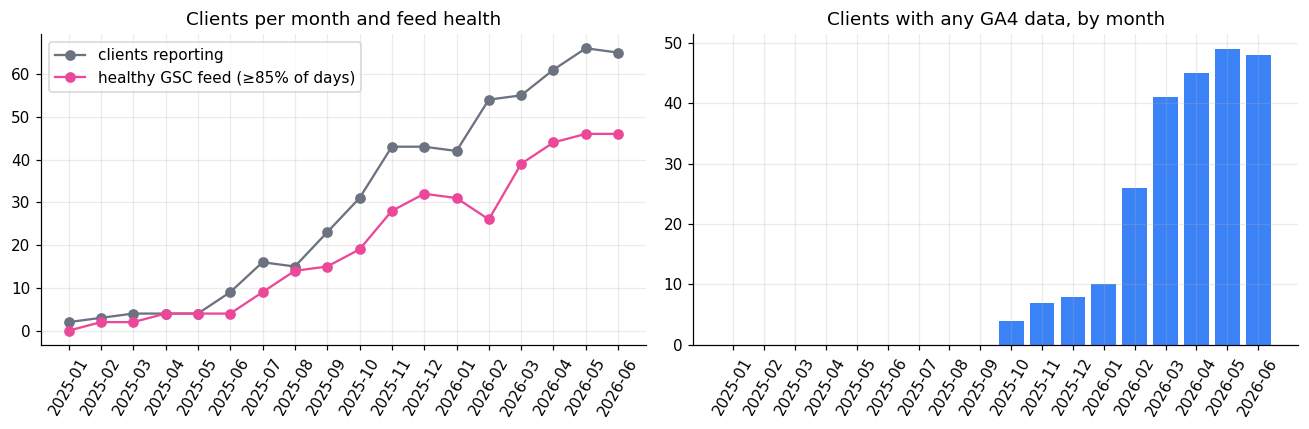

In [ ]:
cov_summary = (client_cov.assign(healthy=client_cov["gsc_cov"] >= MIN_CLIENT_COVERAGE,
                                 ga4_any=client_cov["client_ga4_days"] > 0)
               .groupby("month", as_index=False)
               .agg(clients=("client_hash_id", "nunique"), healthy_gsc_clients=("healthy", "sum"),
                    clients_with_ga4=("ga4_any", "sum"), median_gsc_coverage=("gsc_cov", "median")))
cov_summary["healthy_share"] = cov_summary["healthy_gsc_clients"] / cov_summary["clients"]

# Item-level sparsity: do items report on every day, or only on days with impressions?
sparsity = monthly.loc[monthly["gsc_days"] > 0].assign(active_share=lambda d: d["gsc_days"] / d["days_in_month"])
print("Median item-level active-day share (days with a GSC row / days in month):",
      round(float(sparsity["active_share"].median()), 3))
print("  Interpretation: if this is well below 1, GSC emits item-day rows mostly for days with impressions, so a missing\n"
      "  next-month row under a HEALTHY client feed is a true zero (§2.3); if it is close to 1, items report almost daily and\n"
      "  true zeros are rarer. Either way, an UNHEALTHY client feed makes the month unusable as a label.")
display(cov_summary)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(cov_summary["month"], cov_summary["clients"], marker="o", color=PALETTE["Persistence"], label="clients reporting")
ax[0].plot(cov_summary["month"], cov_summary["healthy_gsc_clients"], marker="o", color=PALETTE["accent"],
           label=f"healthy GSC feed (≥{MIN_CLIENT_COVERAGE:.0%} of days)")
ax[0].set_title("Clients per month and feed health"); ax[0].tick_params(axis="x", rotation=60); ax[0].legend()
ax[1].bar(cov_summary["month"], cov_summary["clients_with_ga4"], color=PALETTE["Ridge"])
ax[1].set_title("Clients with any GA4 data, by month"); ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
savefig("fig01_coverage")

RESULTS["coverage"] = {"min_client_coverage": MIN_CLIENT_COVERAGE,
                       "median_item_active_share": float(sparsity["active_share"].median()),
                       "client_months": int(len(client_cov)),
                       "client_months_healthy": int((client_cov["gsc_cov"] >= MIN_CLIENT_COVERAGE).sum())}

### 2.3 Is the position field trustworthy?

Average position is `gsc_sum_position / impressions` — *if* `gsc_sum_position` is an impression-weighted sum. The warehouse also ships its own `gsc_avg_position`. Both are aggregated per item-month and **cross-checked**:

* If the two **agree** (≥ 95% of rows within one position, on rows where both exist), the sum-based field is used.
* If they **disagree**, the **impression-weighted warehouse average position** is used instead.
* Independently of that choice, rows with **no position reported** (numerator 0) or an **impossible position between 0 and 1** are counted separately and dropped as an explicit data-quality exclusion in §2.4 — they are not evidence that the fields disagree.

This rule is fixed in advance (`POSITION_SOURCE = "auto"`); the decision, its *code* (`agree` / `disagree` / `sparse`) and the evidence are printed and saved.

In [ ]:
from scipy.stats import spearmanr

def audit_position_fields(monthly):
    m = monthly.loc[(monthly["gsc_days"] > 0) & (monthly["impressions"] > 0), ["client_hash_id", "impressions", "sum_position", "pos_w"]]
    a = m["sum_position"] / m["impressions"]
    has_w = m["pos_w"] > 0
    b = (m["pos_w"] / m["impressions"]).where(has_w)
    diff = (a - b).abs()
    stats = {"rows": int(len(m)),
             "share_sum_based_below_1": float((a < 0.999).mean()),
             "share_sum_based_zero": float((m["sum_position"] <= 0).mean()),
             "share_sum_based_between_0_and_1": float(((a > 0) & (a < 0.999)).mean()),
             "median_impressions_of_rows_without_position": float(m.loc[m["sum_position"] <= 0, "impressions"].median()) if (m["sum_position"] <= 0).any() else float("nan"),
             "share_weighted_below_1": float((b[has_w] < 0.999).mean()) if has_w.any() else float("nan"),
             "weighted_field_coverage": float(has_w.mean()),
             "median_abs_diff": float(diff[has_w].median()) if has_w.any() else float("nan"),
             "share_within_1_position": float((diff[has_w] <= 1.0).mean()) if has_w.any() else float("nan"),
             "rank_corr": float(spearmanr(a[has_w], b[has_w]).statistic) if has_w.sum() > 10 else float("nan")}
    return stats, m.assign(mismatch=(diff > 1.0) & has_w)


def choose_position_source(stats):
    """Returns (source, code, reason). The reason text matches the code, so it can never contradict the evidence."""
    if POSITION_SOURCE in ("sum", "weighted"):
        return POSITION_SOURCE, "configured", "set in the config cell"
    if not stats["weighted_field_coverage"] >= 0.9:
        return "sum", "sparse", f"the warehouse average-position field covers only {stats['weighted_field_coverage']:.0%} of rows; keeping the sum-based field (inspect manually)"
    if stats["share_within_1_position"] >= 0.95:
        return "sum", "agree", f"the two fields agree on rows where both exist ({stats['share_within_1_position']:.1%} within one position)"
    return "weighted", "disagree", f"the sum-based position is within one position of the warehouse's own average on only {stats['share_within_1_position']:.1%} of rows"


pos_stats, pos_rows = audit_position_fields(monthly)
POS_CHOICE, POS_CODE, POS_REASON = choose_position_source(pos_stats)
display(pd.Series(pos_stats, name="value").to_frame())
mm = (pos_rows.groupby("client_hash_id").agg(rows=("mismatch", "size"), mismatch_share=("mismatch", "mean"))
      .sort_values("mismatch_share", ascending=False))
mm.index = [f"Client {i + 1}" for i in range(len(mm))]            # anonymised, ordered by mismatch
print("Clients with the highest share of rows where the two position fields disagree by > 1:")
display(mm.head(5))
print(f"\nDECISION → position source = '{POS_CHOICE}' (code: {POS_CODE}): {POS_REASON}.")
print(f"Rows with NO position reported (numerator 0): {pos_stats['share_sum_based_zero']:.2%} (median impressions {pos_stats['median_impressions_of_rows_without_position']:,.0f}); "
      f"rows with an impossible position between 0 and 1: {pos_stats['share_sum_based_between_0_and_1']:.2%}  → dropped as a data-quality exclusion in §2.4.")
monthly["sum_position_raw"] = monthly["sum_position"]
if POS_CHOICE == "weighted":
    monthly["sum_position"] = monthly["pos_w"]
RESULTS["position_audit"] = {**pos_stats, "decision": POS_CHOICE, "code": POS_CODE, "reason": POS_REASON,
                             "clients_with_mismatch_over_20pct": int((mm["mismatch_share"] > 0.2).sum())}

,value
rows,"1,546,456.0000"
share_sum_based_below_1,0.0370
share_sum_based_zero,0.0294
share_sum_based_between_0_and_1,0.0076
median_impressions_of_rows_without_position,1.0000
share_weighted_below_1,0.0079
weighted_field_coverage,0.9706
median_abs_diff,0.0000
share_within_1_position,1.0000
rank_corr,1.0000


Clients with the highest share of rows where the two position fields disagree by > 1:


,rows,mismatch_share
Client 1,3634,0.0000
Client 2,374,0.0000
Client 3,153247,0.0000
Client 4,1573,0.0000
Client 5,2089,0.0000



DECISION → position source = 'sum' (code: agree): the two fields agree on rows where both exist (100.0% within one position).
Rows with NO position reported (numerator 0): 2.94% (median impressions 1); rows with an impossible position between 0 and 1: 0.76%  → dropped as a data-quality exclusion in §2.4.


### 2.4 Panel construction, label definition, exclusions ledger and duplicate audit

**Observation row:** an item-month with GSC impressions > 0 in a month whose client feed is healthy.

**Label (target).** `y = log1p(next-month impressions) − log1p(current-month impressions)`, the log change. Two different things can make the next month's impressions zero, and both are tracked:

* the item has **no next-month row** under a healthy client feed (*absent row*), or
* the item **has** a next-month row but with zero GSC impressions (*present-but-zero*, e.g. a GA4-only row).

Both are kept as legitimate zero outcomes (dropping them would silently remove every page that fell out of search) and reported by split. If the client's next-month feed is **unhealthy**, the label is an availability artifact and the row is excluded.

**Implausible rows** are dropped *and broken down by reason* — clicks > impressions; **no position reported** (numerator 0); **impossible position** between 0 and 1; non-finite — with the median impressions of dropped vs. kept rows (a hint of selection bias).

**Duplicated metric blocks.** Two rules, because replication is often *almost* exact:

* **Exact:** ≥ `DUP_MIN_GROUP` items of one client share *identical* impressions, clicks and position (4 decimals) in a month (impressions ≥ `DUP_MIN_IMPR`).
* **Near-duplicate:** ≥ `DUP_NEAR_MIN_GROUP` items of one client-month have impressions within ~1% and positions within 0.1 of each other (impressions ≥ `DUP_NEAR_MIN_IMPR`). Impressions and positions are binned on four offset lattices so a block that straddles a bin edge is still caught.

Metrics replicated across content IDs are not independent observations. Flagged rows are audited — with the **largest blocks printed** so you can verify them by eye — and excluded from modeling and from the queue (`EXCLUDE_DUPLICATE_BLOCKS`).

The release's **final month** has no next month: its rows are never used for training or evaluation, but §6 scores them to produce the *current* queue.

In [ ]:
KEYS = ["client_hash_id", "content_hash_id", "month_idx"]
LOOKUP = ["impressions", "clicks", "sum_position"]

# Feature groups (used for the ablation in §4)
G_GSC  = ["log_impr", "log_clicks", "ctr", "avg_position", "active_day_share"]
G_LAGS = ["mom_change", "prev_known", "prev_absent", "ctr_change", "pos_change", "item_age_months"]
G_GA4  = ["log_pageviews", "log_sessions", "log_users", "log_engaged_sessions", "log_engagement_sec", "eng_rate",
          "log_sessions_organic", "log_sessions_direct", "log_sessions_referral", "log_sessions_social",
          "log_sessions_paid", "log_sessions_ai", "log_scroll_events", "ga4_day_share", "has_ga4"]
FEATURES = G_GSC + G_LAGS + G_GA4


def shift_months(df, k):
    out = df.copy()
    out["month_idx"] = out["month_idx"] + k
    return out


def engineer_features(d):
    """Current-month features, lags from the previous month, GA4 block, and the log-change label."""
    d["ctr"] = d["clicks"] / d["impressions"]
    d["avg_position"] = d["sum_position"] / d["impressions"]
    d["active_day_share"] = (d["gsc_days"] / d["days_in_month"]).clip(0, 1)
    d["log_impr"] = np.log1p(d["impressions"])
    d["log_clicks"] = np.log1p(d["clicks"])

    pi = d["prev_impressions"].to_numpy(float)
    known = d["prev_ok"].to_numpy(bool)
    pi0 = np.nan_to_num(pi, nan=0.0)
    safe = np.where(pi0 > 0, pi0, 1.0)
    pos_prev = np.nan_to_num(d["prev_sum_position"].to_numpy(float)) / safe
    ctr_prev = np.nan_to_num(d["prev_clicks"].to_numpy(float)) / safe
    d["prev_known"] = known.astype(int)
    d["prev_absent"] = (known & (pi0 == 0)).astype(int)
    d["mom_change"] = np.where(known, d["log_impr"].to_numpy() - np.log1p(pi0), 0.0)
    d["ctr_change"] = np.where(known & (pi0 > 0), d["ctr"].to_numpy() - ctr_prev, 0.0)
    d["pos_change"] = np.where(known & (pi0 > 0), d["avg_position"].to_numpy() - pos_prev, 0.0)
    d["item_age_months"] = (d["month_idx"] - d["first_idx"]).astype(float)

    for c in GA4_FIELDS:
        d[f"log_{c}"] = np.log1p(d[c])
    d["eng_rate"] = np.where(d["sessions"] > 0, (d["engaged_sessions"] / d["sessions"].where(d["sessions"] > 0, 1.0)).clip(0, 1), 0.0)
    d["ga4_day_share"] = (d["ga4_days"] / d["days_in_month"]).clip(0, 1)
    d["has_ga4"] = (d["ga4_days"] > 0).astype(int)

    # label: log change in impressions (a prediction of 0 == persistence)
    d["y_level"] = np.log1p(d["next_impressions"])
    d["y_delta"] = d["y_level"] - d["log_impr"]
    return d


def flag_exact_duplicates(obs):
    """True for items whose (impressions, clicks, position) are identical to those of >= DUP_MIN_GROUP items of the same client-month."""
    flag = pd.Series(False, index=obs.index)
    big = obs.loc[obs["impressions"] >= DUP_MIN_IMPR, ["client_hash_id", "month_idx", "impressions", "clicks", "avg_position"]].copy()
    big["pos_r"] = big["avg_position"].round(4)
    size = big.groupby(["client_hash_id", "month_idx", "impressions", "clicks", "pos_r"])["impressions"].transform("size")
    flag.loc[big.index] = size >= DUP_MIN_GROUP
    return flag


def flag_near_duplicates(obs):
    """True for items sharing a client-month with >= DUP_NEAR_MIN_GROUP others whose impressions agree within ~DUP_NEAR_REL_TOL (log scale)
    and positions within ~DUP_NEAR_POS_TOL. Four offset lattices catch blocks that straddle a bin edge."""
    flag = pd.Series(False, index=obs.index)
    big = obs.loc[obs["impressions"] >= DUP_NEAR_MIN_IMPR, ["client_hash_id", "month_idx", "impressions", "avg_position"]]
    if big.empty:
        return flag
    li = np.log(big["impressions"].to_numpy(float)) / DUP_NEAR_REL_TOL
    pp = big["avg_position"].to_numpy(float) / DUP_NEAR_POS_TOL
    hit = np.zeros(len(big), bool)
    for oi in (0.0, 0.5):
        for op in (0.0, 0.5):
            key = pd.DataFrame({"c": big["client_hash_id"].to_numpy(), "m": big["month_idx"].to_numpy(),
                                "i": np.floor(li + oi).astype(np.int64), "p": np.floor(pp + op).astype(np.int64)})
            hit |= key.groupby(["c", "m", "i", "p"])["i"].transform("size").to_numpy() >= DUP_NEAR_MIN_GROUP
    flag.loc[big.index] = hit
    return flag


def build_panel(monthly, client_cov, min_cov):
    ledger = {"item_months_total": int(len(monthly))}
    obs = monthly[(monthly["gsc_days"] > 0) & (monthly["impressions"] > 0)].copy()
    ledger["no_gsc_impressions"] = int(len(monthly) - len(obs))
    n0 = len(obs)

    nxt = shift_months(monthly[KEYS + LOOKUP], -1).rename(columns={c: f"next_{c}" for c in LOOKUP})
    prv = shift_months(monthly[KEYS + LOOKUP], +1).rename(columns={c: f"prev_{c}" for c in LOOKUP})
    obs = obs.merge(nxt, on=KEYS, how="left").merge(prv, on=KEYS, how="left")

    ckey = ["client_hash_id", "month_idx"]
    cov = client_cov[ckey + ["gsc_cov"]]
    obs = (obs.merge(cov.rename(columns={"gsc_cov": "cur_cov"}), on=ckey, how="left")
              .merge(shift_months(cov, -1).rename(columns={"gsc_cov": "next_cov"}), on=ckey, how="left")
              .merge(shift_months(cov, +1).rename(columns={"gsc_cov": "prev_cov"}), on=ckey, how="left"))
    assert len(obs) == n0, "join fan-out: keys are not unique"

    first = (monthly[monthly["impressions"] > 0].groupby(["client_hash_id", "content_hash_id"], as_index=False)["month_idx"]
             .min().rename(columns={"month_idx": "first_idx"}))
    obs = obs.merge(first, on=["client_hash_id", "content_hash_id"], how="left")

    obs["is_last_month"] = obs["month_idx"] == LAST_IDX
    obs["cur_ok"] = obs["cur_cov"].fillna(0) >= min_cov
    obs["next_ok"] = (~obs["is_last_month"]) & (obs["next_cov"].fillna(0) >= min_cov)
    obs["prev_ok"] = obs["prev_cov"].fillna(0) >= min_cov
    obs["next_missing"] = obs["next_impressions"].isna()                  # absent row
    for c in LOOKUP:
        obs[f"next_{c}"] = obs[f"next_{c}"].fillna(0.0)                    # absent row + healthy feed == zero
        obs[f"prev_{c}"] = obs[f"prev_{c}"].fillna(0.0).where(obs["prev_ok"])
    obs["label_ok"] = obs["cur_ok"] & obs["next_ok"]
    obs["next_zero"] = obs["label_ok"] & (obs["next_impressions"] == 0)   # absent OR present-but-zero

    obs = engineer_features(obs)

    m_clicks = obs["clicks"] > obs["impressions"]
    m_nopos = obs["sum_position"] <= 0                                          # no position reported at all
    m_pos = (obs["avg_position"] > 0) & (obs["avg_position"] < 0.999)          # impossible position between 0 and 1
    m_other = (obs["clicks"] < 0) | ~np.isfinite(obs["ctr"]) | ~np.isfinite(obs["avg_position"])
    bad = m_clicks | m_nopos | m_pos | m_other
    ledger["invalid_breakdown"] = {"clicks_gt_impressions": int(m_clicks.sum()), "position_missing": int(m_nopos.sum()),
                                   "position_between_0_and_1": int(m_pos.sum()), "position_lt_1": int((m_nopos | m_pos).sum()),
                                   "non_finite_or_negative": int(m_other.sum()), "any_reason": int(bad.sum()),
                                   "median_impressions_dropped": float(obs.loc[bad, "impressions"].median()) if bad.any() else float("nan"),
                                   "median_impressions_kept": float(obs.loc[~bad, "impressions"].median())}
    ledger["invalid_values_dropped"] = int(bad.sum())
    obs = obs.loc[~bad].reset_index(drop=True)

    obs["dup_exact"] = flag_exact_duplicates(obs)
    obs["dup_near"] = flag_near_duplicates(obs)
    obs["dup_block"] = obs["dup_exact"] | obs["dup_near"]
    return obs, ledger


def ledger_counts(obs_all, ledger):
    excl = obs_all["dup_block"] & EXCLUDE_DUPLICATE_BLOCKS
    main = obs_all.loc[~excl]
    ledger["observations"] = int(len(obs_all))
    ledger["duplicate_blocks_excluded"] = int(excl.sum())
    ledger["current_feed_unhealthy"] = int((~main["cur_ok"]).sum())
    ledger["final_month_scoring_only"] = int((main["cur_ok"] & main["is_last_month"]).sum())
    ledger["next_feed_unhealthy"] = int((main["cur_ok"] & ~main["is_last_month"] & ~main["next_ok"]).sum())
    ledger["labeled_rows"] = int(main["label_ok"].sum())
    assert ledger["observations"] == (ledger["duplicate_blocks_excluded"] + ledger["current_feed_unhealthy"] + ledger["final_month_scoring_only"]
                                      + ledger["next_feed_unhealthy"] + ledger["labeled_rows"]), "ledger does not reconcile"
    ledger["labeled_zero_target"] = int(main["next_zero"].sum())
    ledger["labeled_absent_next_row"] = int((main["label_ok"] & main["next_missing"]).sum())
    return main.reset_index(drop=True)


panel_all, ledger = build_panel(monthly, client_cov, MIN_CLIENT_COVERAGE)
panel = ledger_counts(panel_all, ledger)
assert not panel.loc[panel["cur_ok"], FEATURES].isna().any().any(), "NaN in features"
assert np.isfinite(panel.loc[panel["cur_ok"], FEATURES].to_numpy(float)).all(), "non-finite feature"
RESULTS["ledger"] = ledger

ledger_df = pd.DataFrame([
    ("Item-months in the release", ledger["item_months_total"]),
    ("− without GSC impressions (not an observation)", -ledger["no_gsc_impressions"]),
    ("− implausible values (see breakdown below)", -ledger["invalid_values_dropped"]),
    ("= Observations", ledger["observations"]),
    ("− duplicated metric blocks" + ("" if EXCLUDE_DUPLICATE_BLOCKS else " (flagged, NOT excluded)"), -ledger["duplicate_blocks_excluded"]),
    ("− current-month client feed unhealthy", -ledger["current_feed_unhealthy"]),
    (f"− final month ({LAST_MONTH}): no next month; scored in §6 only", -ledger["final_month_scoring_only"]),
    ("− next-month client feed unhealthy", -ledger["next_feed_unhealthy"]),
    ("= Labeled rows (modeling set)", ledger["labeled_rows"]),
    ("   of which: zero next-month impressions (absent row + present-but-zero)", ledger["labeled_zero_target"]),
    ("      of which: item absent next month", ledger["labeled_absent_next_row"]),
], columns=["step", "rows"])
display(ledger_df)

ib = ledger["invalid_breakdown"]
display(pd.DataFrame({"reason (non-exclusive)": ["clicks > impressions", "no position reported (numerator 0)", "impossible position (between 0 and 1)",
                                                   "non-finite / negative", "ANY (exclusive total)"],
                      "rows": [ib["clicks_gt_impressions"], ib["position_missing"], ib["position_between_0_and_1"], ib["non_finite_or_negative"], ib["any_reason"]]}))
print(f"Median impressions — dropped rows: {ib['median_impressions_dropped']:,.0f} | kept rows: {ib['median_impressions_kept']:,.0f}"
      "  (a large gap would mean the filter is removing a particular kind of item).")

# ---- duplicate-block audit (all flagged rows, whether or not excluded)
dups = panel_all[panel_all["dup_block"]]
by_m = (panel_all.groupby("month").agg(observations=("impressions", "size"), total_impressions=("impressions", "sum"))
        .join(dups.groupby("month").agg(flagged_rows=("impressions", "size"), flagged_impressions=("impressions", "sum")), how="left").fillna(0))
by_m["share_of_rows"] = by_m["flagged_rows"] / by_m["observations"]
by_m["share_of_impressions"] = by_m["flagged_impressions"] / by_m["total_impressions"]
print(f"\nDuplicated-metric blocks flagged: {len(dups):,} rows ({len(dups) / len(panel_all):.2%} of observations) — "
      f"exact rule: {int(panel_all['dup_exact'].sum()):,}; near-duplicate rule: {int(panel_all['dup_near'].sum()):,}; "
      f"caught ONLY by the near rule: {int((panel_all['dup_near'] & ~panel_all['dup_exact']).sum()):,}")
display(by_m.loc[by_m["flagged_rows"] > 0, ["flagged_rows", "share_of_rows", "share_of_impressions"]])
rank_by_size = panel_all["client_hash_id"].value_counts().index
anon_all = {cid: f"Client {i + 1}" for i, cid in enumerate(rank_by_size)}
dup_clients = dups["client_hash_id"].map(anon_all).value_counts(normalize=True).head(5).rename("share_of_flagged_rows")
if len(dups):
    display(dup_clients.to_frame())
    # the largest flagged blocks, printed so they can be verified by eye (anonymised client labels, no content identifiers)
    top_blocks = (dups.groupby(["client_hash_id", "month"])
                  .agg(flagged_items=("impressions", "size"), impressions_min=("impressions", "min"), impressions_max=("impressions", "max"),
                       position_min=("avg_position", "min"), position_max=("avg_position", "max")).reset_index()
                  .sort_values("flagged_items", ascending=False).head(8))
    top_blocks["client"] = top_blocks["client_hash_id"].map(anon_all)
    top_blocks = top_blocks[["client", "month", "flagged_items", "impressions_min", "impressions_max", "position_min", "position_max"]].reset_index(drop=True)
    print("Largest flagged client-months (verify these by eye; a client-month can hold more than one block):")
    display(top_blocks)
lab_pa = panel_all[panel_all["label_ok"]]
zero_dup = float(lab_pa.loc[lab_pa["dup_block"], "next_zero"].mean()) if lab_pa["dup_block"].any() else float("nan")
zero_non = float(lab_pa.loc[~lab_pa["dup_block"], "next_zero"].mean())
print(f"Share of zero next-month labels — duplicated blocks: {zero_dup:.1%} | all other rows: {zero_non:.1%}")
RESULTS["duplicates"] = {"flagged_rows": int(len(dups)), "share_of_observations": float(len(dups) / len(panel_all)),
                         "excluded": EXCLUDE_DUPLICATE_BLOCKS, "zero_label_share_in_blocks": zero_dup, "zero_label_share_elsewhere": zero_non,
                         "clients_affected": int(dups["client_hash_id"].nunique()),
                         "exact_rows": int(panel_all["dup_exact"].sum()), "near_rows": int(panel_all["dup_near"].sum()),
                         "near_only_rows": int((panel_all["dup_near"] & ~panel_all["dup_exact"]).sum()),
                         "largest_block_items": int(top_blocks["flagged_items"].iloc[0]) if len(dups) else 0,
                         "top_client_share_of_flagged": float(dup_clients.iloc[0]) if len(dups) else 0.0}

# Release temporary duplicate-audit copies after all audit statistics are recorded.
del panel_all, dups, lab_pa, rank_by_size, anon_all
if "dup_clients" in globals(): del dup_clients
if "top_blocks" in globals(): del top_blocks
gc.collect()
print("Released temporary panel and duplicate-audit copies.")

if "client_cov" in globals():
    del client_cov
gc.collect()


,step,rows
0,Item-months in the release,2871202
1,− without GSC impressions (not an observation),-1324746
2,− implausible values (see breakdown below),-57253
3,= Observations,1489203
4,− duplicated metric blocks,-6122
5,− current-month client feed unhealthy,-65867
6,− final month (2026-06): no next month; scored...,-194174
7,− next-month client feed unhealthy,-14358
8,= Labeled rows (modeling set),1208682
9,of which: zero next-month impressions (abse...,110674


,reason (non-exclusive),rows
0,clicks > impressions,0
1,no position reported (numerator 0),45431
2,impossible position (between 0 and 1),11822
3,non-finite / negative,0
4,ANY (exclusive total),57253


Median impressions — dropped rows: 1 | kept rows: 118  (a large gap would mean the filter is removing a particular kind of item).

Duplicated-metric blocks flagged: 6,122 rows (0.41% of observations) — exact rule: 5,424; near-duplicate rule: 5,934; caught ONLY by the near rule: 698


,flagged_rows,share_of_rows,share_of_impressions
month,,,
2025-11,795.0000,0.0082,0.0508
2025-12,833.0000,0.0078,0.1365
2026-01,833.0000,0.0070,0.0451
2026-02,833.0000,0.0056,0.0117
2026-03,858.0000,0.0049,0.0151
2026-04,839.0000,0.0043,0.0454
2026-05,764.0000,0.0037,0.0132
2026-06,367.0000,0.0018,0.0093


,share_of_flagged_rows
client_hash_id,
Client 3,0.9178
Client 22,0.0343
Client 2,0.0232
Client 40,0.0136
Client 1,0.0046


Largest flagged client-months (verify these by eye; a client-month can hold more than one block):


,client,month,flagged_items,impressions_min,impressions_max,position_min,position_max
0,Client 3,2025-12,833,"18,183.0000","18,183.0000",6.2430,6.2430
1,Client 3,2026-01,833,"7,694.0000","7,694.0000",6.8417,6.8417
2,Client 3,2026-03,833,"4,991.0000","4,991.0000",6.3586,6.3586
3,Client 3,2026-02,833,"2,482.0000","2,482.0000",7.3662,7.3662
4,Client 3,2026-04,833,"15,860.0000","15,860.0000",5.2896,5.2896
5,Client 3,2025-11,795,"5,284.0000","5,370.0000",4.5547,4.8017
6,Client 3,2026-05,659,"5,219.0000","5,585.0000",5.3527,6.6969
7,Client 2,2026-06,129,"8,584.0000","8,584.0000",4.8442,4.8442


Share of zero next-month labels — duplicated blocks: 4.0% | all other rows: 9.2%
Released temporary panel and duplicate-audit copies.


0

### 2.5 Chronological splits and what each split looks like

Labeled rows outside the configured splits: 0


,split,months,rows,clients,share_rows_unseen_clients,share_rows_with_ga4,share_zero_impression_labels,share_absent_next_row,median_impressions
0,train,2025-01 → 2025-12,416675,31,0.0000,0.0789,0.0909,0.0255,93.0000
1,validation,2026-01 → 2026-03,402754,39,0.1018,0.2835,0.0882,0.0000,155.0000
2,test,2026-04 → 2026-05,389253,46,0.2681,0.5015,0.0957,0.0000,140.0000


,split,zero_label_share,of_which_absent_row,of_which_present_but_zero,clients_with_zero_labels,top_client_share_of_zeros
0,train,0.0909,0.0255,0.0655,31,0.1787
1,validation,0.0882,0.0000,0.0882,38,0.3795
2,test,0.0957,0.0000,0.0957,42,0.1375


Share of training rows in its final 3 months: 61.0%
GA4 coverage — train: 7.9%  |  test: 50.1%


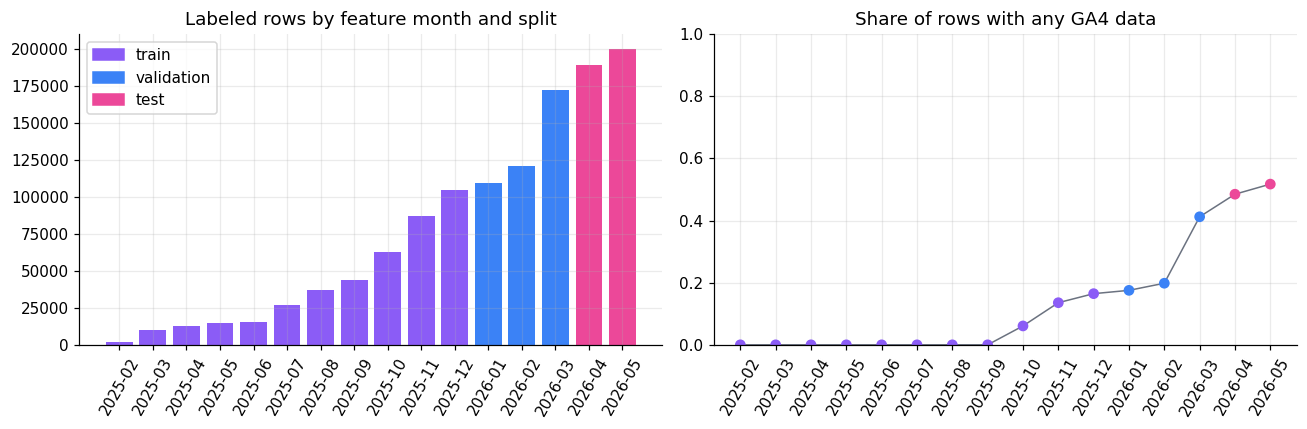

Retained 194,174 final-month scoring rows in panel; historical splits remain unchanged in D.
Compacted shared lab frame to 33 columns; split-specific D frames are unchanged.


In [ ]:
split_of = {m: s for s, ms in SPLITS.items() for m in ms}
panel["split"] = panel["month"].astype(str).map(split_of).fillna("unassigned")

for s, ms in SPLITS.items():
    absent = [m for m in ms if m not in set(monthly["month"].astype(str))]
    assert not absent, f"{s}: months not in release: {absent}"

# ---- pooled CTR-by-position prior + peer-relative expected CTR (§2.6) are attached to `panel` BEFORE the split tables
def bucket_of(pos, max_pos=50):
    return np.clip(np.floor(np.asarray(pos, float)), 1, max_pos).astype(int)


from sklearn.isotonic import IsotonicRegression

def fit_prior_curve(df, max_pos=50):
    """Pooled CTR by integer position: the MEDIAN ACROSS CLIENTS (each client weighted equally, so one giant client cannot dominate),
    forced monotone non-increasing by isotonic regression."""
    d = pd.DataFrame({"client": df["client_hash_id"].to_numpy(), "b": bucket_of(df["avg_position"], max_pos),
                      "clicks": df["clicks"].to_numpy(), "impr": df["impressions"].to_numpy()})
    cb_all = d.groupby(["client", "b"], as_index=False)[["clicks", "impr"]].sum()
    for min_impr in (MIN_BUCKET_IMPR, 1_000, 100, 0):
        cb = cb_all[cb_all["impr"] >= max(min_impr, 1)].copy()
        cb["ctr"] = cb["clicks"] / cb["impr"]
        stats = cb.groupby("b")["ctr"].agg(median="median", n_clients="size").reindex(range(1, max_pos + 1))
        if stats["median"].notna().sum() >= 5:
            break
    vals = stats["median"].interpolate(limit_direction="both")
    w = stats["n_clients"].fillna(1).clip(lower=1)
    iso = IsotonicRegression(increasing=False, out_of_bounds="clip").fit(np.arange(1, max_pos + 1), vals.to_numpy(), sample_weight=w.to_numpy())
    curve = pd.Series(iso.predict(np.arange(1, max_pos + 1)), index=range(1, max_pos + 1), name="prior_ctr")
    return curve, stats["n_clients"].fillna(0).astype(int), cb


def peer_expected_ctr(df, prior, strength=CTR_PRIOR_STRENGTH):
    """Expected CTR of each item = CTR of the SAME client's OTHER items at the same position bucket in the SAME month
    (leave-one-out), shrunk toward the pooled prior. Uses only information available at the end of the observation month."""
    b = bucket_of(df["avg_position"])
    tmp = pd.DataFrame({"client": df["client_hash_id"].to_numpy(), "m": df["month_idx"].to_numpy(), "b": b,
                        "clicks": df["clicks"].to_numpy(), "impr": df["impressions"].to_numpy()})
    tot = tmp.groupby(["client", "m", "b"])[["clicks", "impr"]].transform("sum")
    loo_c, loo_i = tot["clicks"].to_numpy() - tmp["clicks"].to_numpy(), tot["impr"].to_numpy() - tmp["impr"].to_numpy()
    pri = prior.reindex(b).to_numpy()
    return (loo_c + strength * pri) / (loo_i + strength)


is_train = (panel["split"] == "train") & panel["cur_ok"]
BENCH_PRIOR, BENCH_NCLIENTS, BENCH_CB = fit_prior_curve(panel[is_train])
panel["expected_ctr"] = peer_expected_ctr(panel, BENCH_PRIOR)

lab = panel[panel["label_ok"] & panel["split"].isin(list(SPLITS))].reset_index(drop=True)
stray = int((panel["label_ok"] & (panel["split"] == "unassigned")).sum())
print(f"Labeled rows outside the configured splits: {stray:,}" + ("  (months not assigned to any split)" if stray else ""))

D = {s: lab[lab["split"] == s].reset_index(drop=True) for s in SPLITS}
train_clients = set(D["train"]["client_hash_id"])
for s in SPLITS:
    D[s]["seen_client"] = D[s]["client_hash_id"].isin(train_clients)

split_table = pd.DataFrame([{
    "split": s, "months": f"{min(SPLITS[s])} → {max(SPLITS[s])}", "rows": len(D[s]),
    "clients": D[s]["client_hash_id"].nunique(),
    "share_rows_unseen_clients": 1 - D[s]["seen_client"].mean(),
    "share_rows_with_ga4": D[s]["has_ga4"].mean(),
    "share_zero_impression_labels": D[s]["next_zero"].mean(),
    "share_absent_next_row": D[s]["next_missing"].mean(),
    "median_impressions": D[s]["impressions"].median()} for s in SPLITS])
display(split_table)
RESULTS["splits"] = split_table.to_dict(orient="records")

# zero-target audit by split: how many are "present-but-zero", and are they concentrated in a few clients?
zrows = []
for s in SPLITS:
    z = D[s][D[s]["next_zero"]]
    top = z["client_hash_id"].value_counts(normalize=True)
    zrows.append({"split": s, "zero_label_share": D[s]["next_zero"].mean(), "of_which_absent_row": float(D[s]["next_missing"].mean()),
                  "of_which_present_but_zero": float(D[s]["next_zero"].mean() - D[s]["next_missing"].mean()),
                  "clients_with_zero_labels": int(z["client_hash_id"].nunique()),
                  "top_client_share_of_zeros": float(top.iloc[0]) if len(top) else 0.0})
zero_df = pd.DataFrame(zrows)
display(zero_df)
RESULTS["zero_targets"] = zero_df.to_dict(orient="records")

tr = D["train"]
last3 = sorted(SPLITS["train"])[-3:]
RESULTS["train_composition"] = {
    "share_rows_in_last_3_train_months": float(tr["month"].astype(str).isin(last3).mean()),
    "share_train_rows_with_ga4": float(tr["has_ga4"].mean()),
    "share_test_rows_with_ga4": float(D["test"]["has_ga4"].mean())}
print(f"Share of training rows in its final 3 months: {RESULTS['train_composition']['share_rows_in_last_3_train_months']:.1%}")
print(f"GA4 coverage — train: {RESULTS['train_composition']['share_train_rows_with_ga4']:.1%}  |  test: {RESULTS['train_composition']['share_test_rows_with_ga4']:.1%}")

comp = (lab.groupby(["month", "split"], as_index=False).agg(rows=("log_impr", "size"), ga4=("has_ga4", "mean"))
        .assign(month=lambda d: d["month"].astype(str)).sort_values("month").reset_index(drop=True))
split_colors = {"train": "#8B5CF6", "validation": "#3B82F6", "test": "#EC4899"}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
xpos = np.arange(len(comp))
ax[0].bar(xpos, comp["rows"], color=[split_colors[s] for s in comp["split"]])
ax[1].plot(xpos, comp["ga4"], color="#6B7280", lw=1, zorder=1)
ax[1].scatter(xpos, comp["ga4"], c=[split_colors[s] for s in comp["split"]], zorder=2)
for a_, ttl in zip(ax, ["Labeled rows by feature month and split", "Share of rows with any GA4 data"]):
    a_.set_xticks(xpos); a_.set_xticklabels(comp["month"], rotation=60); a_.set_title(ttl)
ax[1].set_ylim(0, 1)
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=c_, label=s_) for s_, c_ in split_colors.items()])
plt.tight_layout()
savefig("fig02_split_composition")

# Keep full historical observations in D; panel is only needed for final-month scoring later.
panel = panel.loc[panel["is_last_month"] & panel["cur_ok"]].copy()
gc.collect()
print(f"Retained {len(panel):,} final-month scoring rows in panel; historical splits remain unchanged in D.")


# Keep only fields used by later regime diagnostics and walk-forward fitting in the
# combined `lab` frame. The full split-specific DataFrames D remain untouched.
LAB_KEEP = list(dict.fromkeys(FEATURES + [
    "month", "month_idx", "y_delta", "client_hash_id",
    "impressions", "next_impressions", "next_zero"
]))
lab = lab[LAB_KEEP].copy()
gc.collect()
print(f"Compacted shared lab frame to {len(LAB_KEEP)} columns; split-specific D frames are unchanged.")


### 2.6 Expected CTR — a peer benchmark, sanity-checked before it is trusted

"Missed clicks" needs an *expected CTR* for an item at its position. A single pooled curve can be dominated by one or two huge clients, so two safeguards are used:

1. A **pooled prior**: CTR by integer position bucket as the **median across clients** (each client counts once; buckets need ≥ `MIN_BUCKET_IMPR` impressions per client), made monotone with isotonic regression, from **training months only**.
2. A **peer expectation** per item: the CTR of the *same client's other items* at the same position bucket in the *same month* (leave-one-out, shrunk toward the prior with `CTR_PRIOR_STRENGTH` pseudo-impressions). This asks the question a content team actually cares about — *"is this page getting fewer clicks than the site's other pages at the same rank?"* — and cannot be distorted by cross-client differences in brand mix or SERP features.

**Sanity checks printed below.** (i) The pooled curve should fall steeply with position (position-1 CTR several times position-10 CTR, and in the tens of percent for organic web search). (ii) Within a client-month, expected clicks must match actual clicks (calibration ≈ 1). If (i) fails, the position/click fields may not behave like standard web-search metrics: the *peer-relative* ranking remains usable, but "missed clicks" must **not** be read as clicks relative to a typical SERP.

,position,pooled_prior_CTR,clients_in_bucket
0,1,0.0058,11
1,2,0.0058,13
2,3,0.0058,15
3,5,0.0058,18
4,10,0.0034,15
5,20,0.0023,11
6,30,0.0016,10
7,50,0.0003,16


CTR@1 = 0.58%, CTR@3 = 0.58%, CTR@10 = 0.34%; CTR@1 / CTR@10 = 1.7×
Pooled-curve plausibility: NOT PLAUSIBLE — treat 'missed clicks' as peer-relative only (see §7)
Calibration (expected clicks / actual clicks, within client-month): {'train': 0.998, 'validation': 1.0, 'test': 1.003}


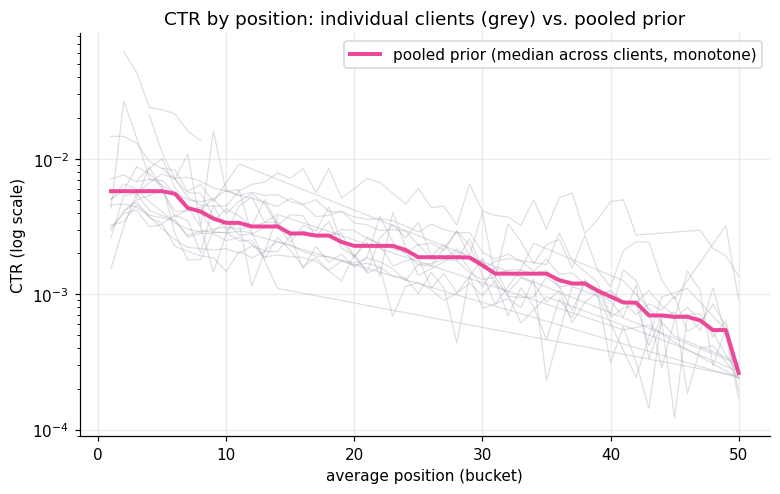

In [ ]:
pts = [1, 2, 3, 5, 10, 20, 30, 50]
bench_tbl = pd.DataFrame({"position": pts, "pooled_prior_CTR": [float(BENCH_PRIOR[p]) for p in pts],
                          "clients_in_bucket": [int(BENCH_NCLIENTS[p]) for p in pts]})
display(bench_tbl)
ctr1, ctr3, ctr10 = float(BENCH_PRIOR[1]), float(BENCH_PRIOR[3]), float(BENCH_PRIOR[10])
bench_plausible = bool(ctr1 >= 0.03 and ctr1 >= 3 * ctr10)
print(f"CTR@1 = {ctr1:.2%}, CTR@3 = {ctr3:.2%}, CTR@10 = {ctr10:.2%}; CTR@1 / CTR@10 = {ctr1 / max(ctr10, 1e-12):.1f}×")
print("Pooled-curve plausibility:", "PLAUSIBLE" if bench_plausible else
      "NOT PLAUSIBLE — treat 'missed clicks' as peer-relative only (see §7)")

calib = {}
for s in list(SPLITS):
    d = D[s]
    calib[s] = float((d["expected_ctr"] * d["impressions"]).sum() / max(d["clicks"].sum(), 1e-9))
print("Calibration (expected clicks / actual clicks, within client-month):", {k: round(v, 3) for k, v in calib.items()})
RESULTS["benchmark"] = {"prior_at_positions": {int(p): float(BENCH_PRIOR[p]) for p in pts}, "plausible": bench_plausible,
                        "ctr1_over_ctr10": float(ctr1 / max(ctr10, 1e-12)), "calibration": calib,
                        "prior_strength": CTR_PRIOR_STRENGTH, "min_bucket_impressions": MIN_BUCKET_IMPR}

fig, ax = plt.subplots(figsize=(7.2, 4.6))
cl = BENCH_CB.groupby("client").filter(lambda g: len(g) >= 4)
for _, g in list(cl.groupby("client"))[:40]:
    g = g.sort_values("b")
    ax.plot(g["b"], g["ctr"], color="#9CA3AF", alpha=0.35, lw=0.8)
ax.plot(BENCH_PRIOR.index, BENCH_PRIOR.values, color=PALETTE["accent"], lw=2.6, label="pooled prior (median across clients, monotone)")
ax.set_yscale("log"); ax.set_xlabel("average position (bucket)"); ax.set_ylabel("CTR (log scale)")
ax.set_title("CTR by position: individual clients (grey) vs. pooled prior"); ax.legend()
plt.tight_layout()
savefig("fig12_ctr_benchmark")

### 2.7 Is the panel stationary? A market-wide regime diagnostic

A model trained on one regime and tested on another will look unskilled whatever its features. For every feature month the diagnostic reports, over the **same items** in month *t* and *t+1*:

* the **portfolio log change** `log(Σ impressions_{t+1} / Σ impressions_t)`,
* the **share of items that fell**, and the **median item change**.

If these differ sharply between training and test months, errors are dominated by the regime, not by item-level signal, and any model that learned the training regime will carry a persistent bias.

,month,split,items,clients,portfolio_log_change,median_item_change,share_fell,share_zero_label
0,2025-02,train,1616,1,0.9456,0.7479,0.0668,0.0031
1,2025-03,train,10046,2,0.7378,0.6931,0.2639,0.0266
2,2025-04,train,13013,4,0.4730,0.3194,0.2706,0.0325
3,2025-05,train,14837,4,0.1173,-0.1439,0.5848,0.0618
4,2025-06,train,15240,4,0.0307,-0.1001,0.5536,0.0877
5,2025-07,train,27033,9,0.2574,0.1427,0.4098,0.0694
6,2025-08,train,36787,14,0.0929,-0.2425,0.6033,0.0869
7,2025-09,train,43751,15,0.2232,0.0757,0.4448,0.0726
8,2025-10,train,62429,18,0.2406,0.2196,0.3595,0.0934
9,2025-11,train,86973,28,0.1136,0.0541,0.4423,0.1107


,mean_portfolio_log_change,mean_share_fell,mean_median_item_change
split,,,
train,0.3226,0.3993,0.1765
validation,0.1469,0.4750,0.0044
test,-0.1829,0.6957,-0.4627


Share of items falling: test − train = +29.6%  →  REGIME SHIFT between training and test months.


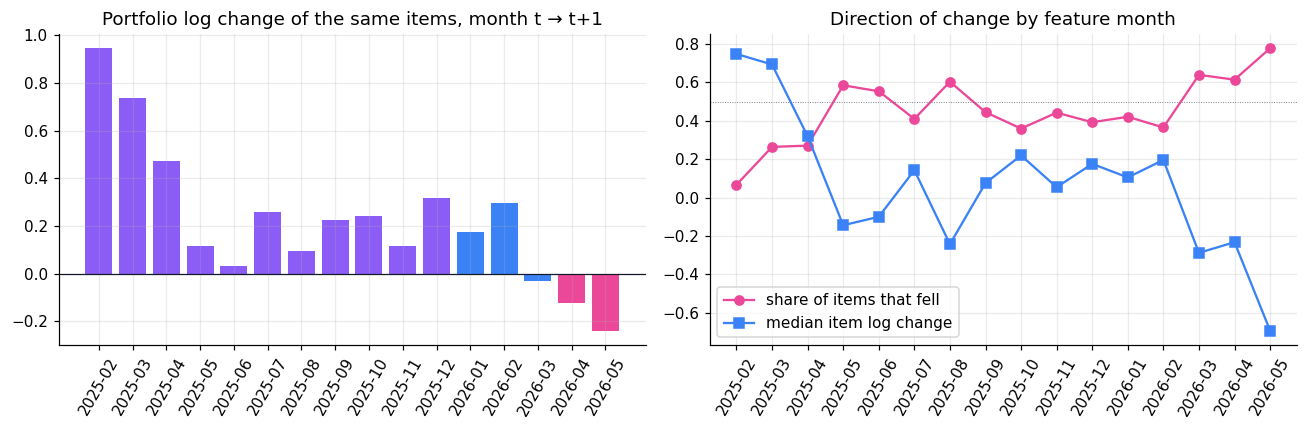

In [ ]:
reg = (lab.assign(month=lab["month"].astype(str)).groupby("month")
       .agg(items=("y_delta", "size"), clients=("client_hash_id", "nunique"), impr=("impressions", "sum"), next_impr=("next_impressions", "sum"),
            median_item_change=("y_delta", "median"), share_fell=("y_delta", lambda s: float((s < 0).mean())),
            share_zero_label=("next_zero", "mean")).reset_index())
reg["portfolio_log_change"] = np.log(reg["next_impr"] / reg["impr"])
reg["split"] = reg["month"].map(split_of)
display(reg[["month", "split", "items", "clients", "portfolio_log_change", "median_item_change", "share_fell", "share_zero_label"]])

reg_split = reg.groupby("split").agg(mean_portfolio_log_change=("portfolio_log_change", "mean"), mean_share_fell=("share_fell", "mean"),
                                     mean_median_item_change=("median_item_change", "mean")).reindex(list(SPLITS))
display(reg_split)
shift_gap = float(reg_split.loc["test", "mean_share_fell"] - reg_split.loc["train", "mean_share_fell"])
regime_shift = abs(shift_gap) >= 0.15
print(f"Share of items falling: test − train = {shift_gap:+.1%}  →  " + ("REGIME SHIFT between training and test months." if regime_shift else "no large regime shift."))
RESULTS["regime"] = {"by_split": reg_split.reset_index().to_dict(orient="records"), "share_fell_gap_test_minus_train": shift_gap,
                     "shift_flag": bool(regime_shift), "by_month": reg[["month", "split", "portfolio_log_change", "share_fell", "median_item_change"]].to_dict(orient="records")}

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
xr = np.arange(len(reg))
ax[0].bar(xr, reg["portfolio_log_change"], color=[split_colors[s] for s in reg["split"]])
ax[0].axhline(0, color=PALETTE["ink"], lw=0.8)
ax[0].set_title("Portfolio log change of the same items, month t → t+1")
ax[1].plot(xr, reg["share_fell"], marker="o", color=PALETTE["accent"], label="share of items that fell")
ax[1].plot(xr, reg["median_item_change"], marker="s", color=PALETTE["Ridge"], label="median item log change")
ax[1].axhline(0.5, color=PALETTE["Persistence"], lw=0.6, ls=":")
ax[1].set_title("Direction of change by feature month"); ax[1].legend()
for a_ in ax:
    a_.set_xticks(xr); a_.set_xticklabels(reg["month"], rotation=60)
plt.tight_layout()
savefig("fig13_regime")

### 2.8 What the audit means for modeling

* **Position, zeros, duplicates and the benchmark were checked, not assumed.** The decisions (position source, duplicate exclusion, peer-based CTR expectation) and their evidence are printed above and saved to `RESULTS`.
* **GA4 is not present uniformly over time.** The share of training rows with any GA4 data is far below the test share, so GA4/engagement features are mostly zeros in training; GA4 findings describe *this release*, not GA4.
* **The panel is unbalanced across time and clients, and may be non-stationary.** §4 reports seen-vs-unseen clients, per-client macro averages and an explicit **market-trend baseline** so that a regime shift cannot masquerade as model error or model skill.
* **Zero outcomes are kept** (absent *and* present-but-zero rows), and §4 reports results with and without them.

## 3. Methodology

**Assumptions.** (1) A client-month is usable when its GSC feed reports on ≥ the configured share of days; (2) a missing next-month row under a healthy feed means zero impressions; (3) the previous month is a legitimate lag feature when its feed was also healthy; (4) rows in duplicated metric blocks are replicated, not independent, observations.

**Label.** `y = log1p(next impressions) − log1p(current impressions)`; model error on `y` equals error on `log1p(next impressions)` once the known offset is added.

**Features.** 5 GSC features, 6 lag/history features, 15 GA4/traffic-source features (grouped for ablation). Position comes from the field chosen in §2.3.

**Baselines (all evaluated on the same split, same rows):**
1. **Persistence** (`y = 0`): next month equals this month — the baseline that matters.
2. **Trailing market change**: every item moves by the *previous month's median change* (known at forecast time) — a regime-aware, model-free forecast.
3. Constant median change (training).
4. Constant median *level* (the weak baseline used in earlier iterations; kept so results remain comparable).
5. Training-decile median change by current impressions.
6. Ridge regression on standardized features.

**Models.** Random Forest and XGBoost; XGBoost hyperparameters are tuned on the validation months with early stopping. The model is selected on **validation MAE only**; the test months are touched once for reporting, and **every** model and baseline is paired with persistence there.

**Validation design.** Chronological train / validation / test by feature month. A forecast made at the end of month *t* may only use labels already resolved by then. We assert programmatically that every training label month is ≤ the first validation feature month (and validation labels ≤ the first test feature month). Several clients appear in every period, so we also report seen-vs-unseen client results.

**Uncertainty.** Rows from one client are correlated, so confidence intervals use a **client-clustered bootstrap** (resample clients, 1,000 replicates), not a row bootstrap.

**Leakage controls.** Identifiers and all `next_*` / label columns are excluded from features by assertion; the walk-forward timing rule is asserted; a shuffled-label canary must fail to beat a constant; the largest single-feature rank correlation with the label is reported.

In [ ]:
from xgboost import XGBRegressor

def assert_walk_forward(splits):
    """Training labels (month t+1) must be resolved by the first feature month of every later split."""
    order = ["train", "validation", "test"]
    for a, b in zip(order, order[1:]):
        last_label_a = max(month_idx(m) for m in splits[a]) + 1
        first_feature_b = min(month_idx(m) for m in splits[b])
        assert last_label_a <= first_feature_b, f"{a} labels ({last_label_a}) not resolved before {b} starts ({first_feature_b})"
    all_months = [m for s in order for m in splits[s]]
    assert len(all_months) == len(set(all_months)), "a month appears in two splits"
    assert max(month_idx(m) for m in splits["test"]) + 1 <= LAST_IDX, "test label month is beyond the release"

tests = []
assert_walk_forward(SPLITS); tests.append(("Walk-forward timing: labels resolved before next split begins", "PASS"))

forbidden = set(ID_COLS) | {"month", "month_idx", "split", "y_delta", "y_level", "next_zero", "next_missing", "dup_block", "expected_ctr"}
bad_feats = [f for f in FEATURES if f in forbidden or f.startswith("next_") or "next" in f.split("_")]
assert not bad_feats, f"forbidden columns used as features: {bad_feats}"
tests.append(("No identifiers, label, next_* or benchmark column among features", "PASS"))

rs = np.random.default_rng(SEED)
canary = XGBRegressor(n_estimators=150, max_depth=6, learning_rate=0.1, tree_method="hist", n_jobs=2, random_state=SEED)
canary.fit(D["train"][FEATURES], rs.permutation(D["train"]["y_delta"].to_numpy()))
canary_mae = float(np.abs(canary.predict(D["validation"][FEATURES]) - D["validation"]["y_delta"]).mean())
const_mae = float(np.abs(D["train"]["y_delta"].median() - D["validation"]["y_delta"]).mean())
assert canary_mae > 0.98 * const_mae, "canary beat the constant by >2%: possible leakage or bug"
tests.append((f"Shuffled-label canary cannot beat constant (canary {canary_mae:.3f} vs constant {const_mae:.3f})", "PASS"))

samp = D["train"].sample(min(60_000, len(D["train"])), random_state=SEED)
rho = {f: abs(spearmanr(samp[f], samp["y_delta"]).statistic) for f in FEATURES if samp[f].nunique() > 1}
top_f = max(rho, key=rho.get)
assert rho[top_f] < 0.9, f"feature {top_f} has |rho|={rho[top_f]:.2f} with the label — investigate"
tests.append((f"Max single-feature |Spearman| with label = {rho[top_f]:.2f} ({top_f}); below 0.90 alarm", "PASS"))

assert np.isfinite(D["train"][FEATURES].to_numpy(float)).all()
tests.append(("All features finite; no NaN imputation required", "PASS"))

leak_df = pd.DataFrame(tests, columns=["leakage / integrity test", "result"])
display(leak_df)
RESULTS["leakage_tests"] = leak_df.to_dict(orient="records")

,leakage / integrity test,result
0,Walk-forward timing: labels resolved before ne...,PASS
1,"No identifiers, label, next_* or benchmark col...",PASS
2,Shuffled-label canary cannot beat constant (ca...,PASS
3,Max single-feature |Spearman| with label = 0.1...,PASS
4,All features finite; no NaN imputation required,PASS


## 4. Results

### 4.1 Evaluation utilities and baselines

All errors are on the log-change scale. A **typical multiplicative error** of `exp(MAE)` is also reported, because "MAE 0.9 in log units" is not intuitive on its own. Confidence intervals come from a **client-clustered bootstrap** (resample whole clients, 1,000 replicates); differences between two methods are **paired** (same rows, same resampled clients).

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

MIN_ROWS_MACRO = 50
XY = {s: dict(X=D[s][FEATURES], y=D[s]["y_delta"].to_numpy(float), base=D[s]["log_impr"].to_numpy(float),
              groups=D[s]["client_hash_id"].to_numpy(), month_idx=D[s]["month_idx"].to_numpy(),
              impr=D[s]["impressions"].to_numpy(float)) for s in SPLITS}


def cluster_bootstrap(values, groups, B=1000, seed=SEED):
    """Client-clustered bootstrap CI for a mean: resample whole clients with replacement."""
    codes, uniques = pd.factorize(pd.Series(groups))
    g = len(uniques)
    sums = np.bincount(codes, weights=values, minlength=g)
    cnt = np.bincount(codes, minlength=g).astype(float)
    draws = np.random.default_rng(seed).integers(0, g, size=(B, g))
    boot = sums[draws].sum(1) / cnt[draws].sum(1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return float(np.mean(values)), float(lo), float(hi)


def score_split(pred, split):
    d = XY[split]
    y, base, g = d["y"], d["base"], d["groups"]
    err = pred - y
    ae = np.abs(err)
    mae, mae_lo, mae_hi = cluster_bootstrap(ae, g)
    mse, mse_lo, mse_hi = cluster_bootstrap(err ** 2, g)
    lvl = y + base
    sse = float((err ** 2).sum())
    pc = pd.Series(ae).groupby(g).agg(["mean", "size"])
    macro = pc.loc[pc["size"] >= MIN_ROWS_MACRO, "mean"].mean()
    rho = spearmanr(pred, y).statistic if np.ptp(pred) > 0 else np.nan
    return {"MAE": mae, "MAE_lo": mae_lo, "MAE_hi": mae_hi, "RMSE": math.sqrt(mse),
            "RMSE_lo": math.sqrt(mse_lo), "RMSE_hi": math.sqrt(mse_hi),
            "R2_change": 1 - sse / float(((y - y.mean()) ** 2).sum()),
            "R2_level": 1 - sse / float(((lvl - lvl.mean()) ** 2).sum()),
            "MedAE": float(np.median(ae)), "Macro_MAE": float(macro), "Spearman": float(rho),
            "typical_factor": math.exp(mae)}


def paired_diff(pred_a, pred_b, split_or_mask, split=None):
    """MAE(A) − MAE(B) with a client-clustered paired bootstrap CI. Negative => A is better."""
    if split is None:
        d, sel = XY[split_or_mask], slice(None)
    else:
        d, sel = XY[split], split_or_mask
    y, g = d["y"][sel], d["groups"][sel]
    diff = np.abs(pred_a[sel] - y) - np.abs(pred_b[sel] - y)
    return cluster_bootstrap(diff, g)


def verdict(lo, hi):
    """Interpret a paired MAE difference CI (model minus comparator)."""
    return "better" if hi < 0 else ("worse" if lo > 0 else "indistinguishable")


def fmt_ci(p, lo, hi, nd=3):
    return f"{p:.{nd}f} [{lo:.{nd}f}, {hi:.{nd}f}]"


# ---------------------------------------------------------------- baselines
tr_y, tr_base = XY["train"]["y"], XY["train"]["base"]
med_delta = float(np.median(tr_y))
med_level = float(np.median(tr_y + tr_base))
edges = np.unique(np.quantile(tr_base, np.linspace(0, 1, 11)[1:-1]))
bin_med = pd.Series(tr_y).groupby(np.digitize(tr_base, edges)).median()
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(XY["train"]["X"], tr_y)

PERSIST = "Persistence (Δ = 0)"
TREND = "Trailing market Δ (previous month's median change)"
# Model-free, regime-aware forecast: every item moves by the median change of the PREVIOUS feature month (its labels are
# resolved by the end of the current month, so this is known at forecast time).
trail_by_month = lab.groupby("month_idx")["y_delta"].median()

def baseline_predictions(split):
    d = XY[split]
    return {PERSIST: np.zeros(len(d["y"])),
            TREND: trail_by_month.reindex(d["month_idx"] - 1).fillna(med_delta).to_numpy(),
            "Constant median Δ": np.full(len(d["y"]), med_delta),
            "Constant median level (earlier baseline)": med_level - d["base"],
            "Decile median Δ (by current impressions)": bin_med.reindex(np.digitize(d["base"], edges)).fillna(med_delta).to_numpy(),
            "Ridge (all features)": ridge.predict(d["X"])}

BASELINES = list(baseline_predictions("validation"))
print("Baselines:", BASELINES)

Baselines: ['Persistence (Δ = 0)', "Trailing market Δ (previous month's median change)", 'Constant median Δ', 'Constant median level (earlier baseline)', 'Decile median Δ (by current impressions)', 'Ridge (all features)']


### 4.2 Model fitting, tuning and selection

* **XGBoost**: a small grid over objective (squared error vs. absolute error) and depth, with early stopping on the **validation** months.
* **Random Forest**: one regularised configuration.
* **Selection rule (fixed in advance): lowest validation MAE.** Because validation is used for early stopping and selection, *validation scores are mildly optimistic*; the test months are used once, for reporting.

In [ ]:
def fit_xgb(params, Xtr, ytr, Xva=None, yva=None, n_estimators=1500, early=True):
    kw = dict(n_estimators=n_estimators, learning_rate=0.06, subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
              tree_method="hist", n_jobs=2, random_state=SEED, **params)
    if early:
        m = XGBRegressor(eval_metric="mae", early_stopping_rounds=50, **kw)
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    else:
        m = XGBRegressor(**kw)
        m.fit(Xtr, ytr, verbose=False)
    return m


def xgb_predict(m, X):
    """Predict with the early-stopping best iteration when one exists (models refit without early stopping use all trees)."""
    try:
        it = int(m.best_iteration)
    except Exception:
        return m.predict(X)
    return m.predict(X, iteration_range=(0, it + 1))


XGB_GRID = [dict(objective=o, max_depth=d) for o in ("reg:squarederror", "reg:absoluteerror") for d in (4, 6, 8)]
Xtr, ytr, Xva, yva = XY["train"]["X"], XY["train"]["y"], XY["validation"]["X"], XY["validation"]["y"]

# Sequential candidate fitting: preserve all six validation trials, retain only the winner.
tuning, best_xgb, best_val_xgb = [], None, np.inf
for params in XGB_GRID:
    m = fit_xgb(params, Xtr, ytr, Xva, yva)
    pv = xgb_predict(m, Xva)
    score = float(np.abs(pv - yva).mean())
    tuning.append({"objective": params["objective"], "max_depth": params["max_depth"],
                   "best_round": int(m.best_iteration) + 1, "val_MAE": score,
                   "val_RMSE": float(np.sqrt(((pv - yva) ** 2).mean()))})
    if score < best_val_xgb:
        if best_xgb is not None: del best_xgb
        best_xgb, best_val_xgb, best_i = m, score, len(tuning) - 1
    else:
        del m
    del pv
    gc.collect()
tuning_df = pd.DataFrame(tuning)
xgb_fits = [None] * len(XGB_GRID)
xgb_fits[best_i] = best_xgb
display(tuning_df.assign(chosen=lambda d: np.where(d.index == best_i, "◄ chosen", "")))

RF_PARAMS = dict(n_estimators=150, max_depth=16, min_samples_leaf=20, max_features=0.33, max_samples=0.5,
                 n_jobs=2, random_state=SEED)
rf = RandomForestRegressor(**RF_PARAMS).fit(Xtr, ytr)

MODELS = {"XGBoost": xgb_fits[best_i], "Random Forest": rf}

def predict_model(name, X):
    return xgb_predict(MODELS[name], X) if name == "XGBoost" else MODELS[name].predict(X)

val_mae = {n: float(np.abs(predict_model(n, Xva) - yva).mean()) for n in MODELS}
SELECTED = min(val_mae, key=val_mae.get)
print("Validation MAE — " + " | ".join(f"{n}: {v:.4f}" for n, v in val_mae.items()))
print(f"Selected by validation MAE: {SELECTED}")

,objective,max_depth,best_round,val_MAE,val_RMSE,chosen
0,reg:squarederror,4,30,0.7546,1.0703,
1,reg:squarederror,6,32,0.7530,1.0630,
2,reg:squarederror,8,28,0.7553,1.0631,
3,reg:absoluteerror,4,57,0.7520,1.0807,
4,reg:absoluteerror,6,57,0.7500,1.0750,◄ chosen
5,reg:absoluteerror,8,36,0.7502,1.0733,


Validation MAE — XGBoost: 0.7500 | Random Forest: 0.7676
Selected by validation MAE: XGBoost


### 4.3 Models vs. baselines on the same held-out test months

,model,val_MAE,test_MAE,test_MAE_CI,test_RMSE,R2_change,R2_level,macro_MAE_per_client,Spearman,typical_×error
0,Persistence (Δ = 0),0.7729,0.9536,"0.954 [0.852, 1.088]",1.3056,-0.2085,0.7508,1.1699,NaN,2.5949
1,Trailing market Δ (previous month's median cha...,0.7994,0.8836,"0.884 [0.795, 1.008]",1.2268,-0.0670,0.7800,1.1038,-0.2316,2.4195
2,Constant median Δ,0.7816,1.0020,"1.002 [0.897, 1.139]",1.3521,-0.2960,0.7328,1.2122,NaN,2.7237
3,Constant median level (earlier baseline),2.2642,2.1809,"2.181 [2.030, 2.462]",2.6466,-3.9657,-0.0238,2.5280,-0.0511,8.8547
4,Decile median Δ (by current impressions),0.7793,1.0119,"1.012 [0.907, 1.150]",1.3668,-0.3243,0.7270,1.2141,-0.0167,2.7508
5,Ridge (all features),0.8272,0.9334,"0.933 [0.837, 1.063]",1.2649,-0.1342,0.7661,1.1653,0.0958,2.5431
6,XGBoost,0.7500,0.9442,"0.944 [0.839, 1.081]",1.2888,-0.1775,0.7572,1.1716,0.0922,2.5707
7,Random Forest,0.7676,0.9178,"0.918 [0.823, 1.046]",1.2355,-0.0822,0.7769,1.1442,0.1623,2.5037


XGBoost  −  Persistence (Δ = 0):  ΔMAE = -0.009 [-0.036, 0.016]  → XGBoost is INDISTINGUISHABLE on the test months
XGBoost  −  Trailing market Δ (previous month's median change):  ΔMAE = 0.061 [0.027, 0.090]  → XGBoost is WORSE on the test months
XGBoost  −  Decile median Δ (by current impressions):  ΔMAE = -0.068 [-0.096, -0.039]  → XGBoost is BETTER on the test months
XGBoost  −  Random Forest:  ΔMAE = 0.026 [0.009, 0.048]  → XGBoost is WORSE on the test months
(The 'best baseline' above is Decile median Δ (by current impressions), chosen on VALIDATION MAE by a rule fixed in advance; the trend baseline is compared separately because it is the strongest on test.)

Every model and baseline versus persistence (paired, same test rows; negative = lower error than persistence):


,model,test_MAE,ΔMAE vs persistence [95% CI],verdict vs persistence
0,Trailing market Δ (previous month's median cha...,0.8836,"-0.070 [-0.092, -0.050]",better
1,Constant median Δ,1.0020,"0.048 [0.042, 0.055]",worse
2,Constant median level (earlier baseline),2.1809,"1.227 [1.086, 1.444]",worse
3,Decile median Δ (by current impressions),1.0119,"0.058 [0.048, 0.067]",worse
4,Ridge (all features),0.9334,"-0.020 [-0.057, 0.016]",indistinguishable
5,XGBoost,0.9442,"-0.009 [-0.036, 0.016]",indistinguishable
6,Random Forest,0.9178,"-0.036 [-0.073, -0.006]",better



Every model and baseline versus the TRAILING-MARKET baseline (paired, same test rows; negative = lower error than the trend):


,model,test_MAE,ΔMAE vs trend baseline [95% CI],verdict vs trend baseline
0,Persistence (Δ = 0),0.9536,"0.070 [0.050, 0.092]",worse
1,Constant median Δ,1.0020,"0.118 [0.093, 0.146]",worse
2,Constant median level (earlier baseline),2.1809,"1.297 [1.165, 1.517]",worse
3,Decile median Δ (by current impressions),1.0119,"0.128 [0.099, 0.158]",worse
4,Ridge (all features),0.9334,"0.050 [0.019, 0.082]",worse
5,XGBoost,0.9442,"0.061 [0.027, 0.090]",worse
6,Random Forest,0.9178,"0.034 [0.001, 0.060]",worse



Selection disclosure: On the test months Random Forest had lower MAE than the pre-selected XGBoost (paired ΔMAE, XGBoost minus Random Forest: 0.0264 [0.0090, 0.0476]). Selection followed the pre-set validation-MAE rule and is not revised after seeing test results; both models are reported against persistence, and the queue (§6) uses XGBoost.

Validation → test MAE ratio:  persistence 1.23×   |   XGBoost 1.26×
Relative MAE reduction vs persistence on test: 1.0% (typical multiplicative error 2.57× vs 2.59× for persistence)


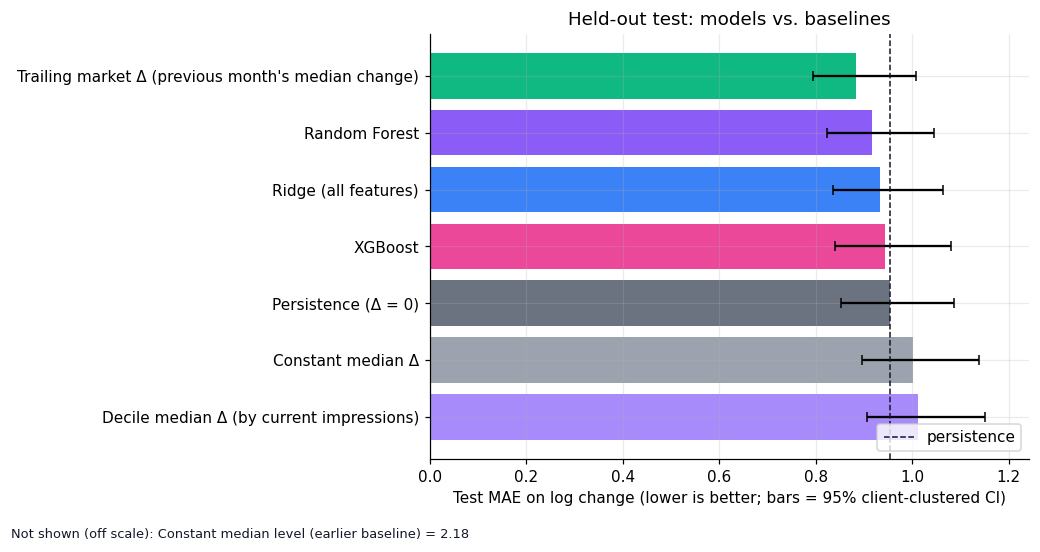

In [ ]:
preds = {s: {**baseline_predictions(s), **{n: predict_model(n, XY[s]["X"]) for n in MODELS}} for s in ("validation", "test")}
rows = []
for name in preds["test"]:
    v, t = score_split(preds["validation"][name], "validation"), score_split(preds["test"][name], "test")
    rows.append({"model": name, "val_MAE": v["MAE"], "test_MAE": t["MAE"], "test_MAE_CI": fmt_ci(t["MAE"], t["MAE_lo"], t["MAE_hi"]),
                 "test_RMSE": t["RMSE"], "R2_change": t["R2_change"], "R2_level": t["R2_level"],
                 "macro_MAE_per_client": t["Macro_MAE"], "Spearman": t["Spearman"], "typical_×error": t["typical_factor"],
                 "_t": t, "_v": v})
results_df = pd.DataFrame(rows)
display(results_df.drop(columns=["_t", "_v"]))
RESULTS["models"] = {r["model"]: {"validation": r["_v"], "test": r["_t"]} for r in rows}

# paired comparisons on the test months
persist_mae = RESULTS["models"][PERSIST]["test"]["MAE"]
sel_mae = RESULTS["models"][SELECTED]["test"]["MAE"]
best_baseline = min([b for b in BASELINES if b != PERSIST], key=lambda b: RESULTS["models"][b]["validation"]["MAE"])
other = [n for n in MODELS if n != SELECTED][0]
comparisons = {}
for label, a, b in [("selected_vs_persistence", SELECTED, PERSIST), ("selected_vs_trend", SELECTED, TREND),
                    ("selected_vs_best_baseline", SELECTED, best_baseline), ("selected_vs_other_model", SELECTED, other)]:
    d, lo, hi = paired_diff(preds["test"][a], preds["test"][b], "test")
    comparisons[label] = {"a": a, "b": b, "diff": d, "lo": lo, "hi": hi, "verdict": verdict(lo, hi)}
    print(f"{a}  −  {b}:  ΔMAE = {fmt_ci(d, lo, hi)}  → {a} is {verdict(lo, hi).upper()} on the test months")
print(f"(The 'best baseline' above is {best_baseline}, chosen on VALIDATION MAE by a rule fixed in advance; the trend baseline is compared separately because it is the strongest on test.)")
RESULTS["comparisons"] = comparisons

# every model and baseline, paired with persistence on the same test rows
paired_rows = []
for name in preds["test"]:
    if name == PERSIST:
        continue
    d_, lo_, hi_ = paired_diff(preds["test"][name], preds["test"][PERSIST], "test")
    paired_rows.append({"model": name, "test_MAE": RESULTS["models"][name]["test"]["MAE"],
                        "ΔMAE vs persistence [95% CI]": fmt_ci(d_, lo_, hi_), "verdict vs persistence": verdict(lo_, hi_),
                        "diff": d_, "lo": lo_, "hi": hi_})
paired_df = pd.DataFrame(paired_rows)
print("\nEvery model and baseline versus persistence (paired, same test rows; negative = lower error than persistence):")
display(paired_df[["model", "test_MAE", "ΔMAE vs persistence [95% CI]", "verdict vs persistence"]])
RESULTS["paired_vs_persistence"] = paired_rows

trend_rows = []
for name in preds["test"]:
    if name == TREND:
        continue
    d_, lo_, hi_ = paired_diff(preds["test"][name], preds["test"][TREND], "test")
    trend_rows.append({"model": name, "test_MAE": RESULTS["models"][name]["test"]["MAE"],
                       "ΔMAE vs trend baseline [95% CI]": fmt_ci(d_, lo_, hi_), "verdict vs trend baseline": verdict(lo_, hi_),
                       "diff": d_, "lo": lo_, "hi": hi_})
trend_df = pd.DataFrame(trend_rows)
print("\nEvery model and baseline versus the TRAILING-MARKET baseline (paired, same test rows; negative = lower error than the trend):")
display(trend_df[["model", "test_MAE", "ΔMAE vs trend baseline [95% CI]", "verdict vs trend baseline"]])
RESULTS["paired_vs_trend"] = trend_rows

# selection disclosure: the rule was fixed before looking at the test months, and is NOT revised after seeing them
test_mae_models = {n: RESULTS["models"][n]["test"]["MAE"] for n in MODELS}
test_best = min(test_mae_models, key=test_mae_models.get)
if test_best != SELECTED:
    c_o = comparisons["selected_vs_other_model"]
    disclosure = (f"On the test months {test_best} had lower MAE than the pre-selected {SELECTED} (paired ΔMAE, {SELECTED} minus {test_best}: "
                  f"{fmt_ci(c_o['diff'], c_o['lo'], c_o['hi'], 4)}). Selection followed the pre-set validation-MAE rule and is not revised after "
                  f"seeing test results; both models are reported against persistence, and the queue (§6) uses {SELECTED}.")
else:
    disclosure = f"The pre-selected {SELECTED} was also the better model on the test months."
print("\nSelection disclosure:", disclosure)
RESULTS["selection"] = {"selected": SELECTED, "validation_mae": val_mae, "best_baseline_by_validation": best_baseline,
                        "xgb_params": XGB_GRID[best_i], "xgb_best_round": int(tuning_df.loc[best_i, "best_round"]),
                        "rf_params": RF_PARAMS, "other_model": other, "test_best_model": test_best, "disclosure": disclosure}

drift = {n: RESULTS["models"][n]["test"]["MAE"] / RESULTS["models"][n]["validation"]["MAE"] for n in (PERSIST, SELECTED)}
RESULTS["val_to_test_mae_ratio"] = drift
print(f"\nValidation → test MAE ratio:  persistence {drift[PERSIST]:.2f}×   |   {SELECTED} {drift[SELECTED]:.2f}×")
print(f"Relative MAE reduction vs persistence on test: {(persist_mae - sel_mae) / persist_mae:.1%} "
      f"(typical multiplicative error {RESULTS['models'][SELECTED]['test']['typical_factor']:.2f}× vs {math.exp(persist_mae):.2f}× for persistence)")

# Figure: test MAE with client-clustered CIs (bars far off scale are listed in a footnote instead of crushing the axis)
order = results_df.sort_values("test_MAE")
shown, hidden = order[order["test_MAE"] <= 1.5 * persist_mae], order[order["test_MAE"] > 1.5 * persist_mae]
TREND_COLOR = "#10B981"
fig, ax = plt.subplots(figsize=(9.5, 4.8))
colors = [PALETTE["XGBoost"] if m == "XGBoost" else PALETTE["Random Forest"] if m == "Random Forest"
          else PALETTE["Persistence"] if m == PERSIST else TREND_COLOR if m == TREND else PALETTE["Ridge"] if m.startswith("Ridge")
          else PALETTE["Decile"] if m.startswith("Decile") else PALETTE["Constant"] for m in shown["model"]]
lo = [r["_t"]["MAE"] - r["_t"]["MAE_lo"] for _, r in shown.iterrows()]
hi = [r["_t"]["MAE_hi"] - r["_t"]["MAE"] for _, r in shown.iterrows()]
ax.barh(shown["model"], shown["test_MAE"], xerr=[lo, hi], color=colors, capsize=3)
ax.axvline(persist_mae, color=PALETTE["ink"], ls="--", lw=1, label="persistence")
ax.set_xlim(0, float((shown["_t"].apply(lambda t: t["MAE_hi"])).max()) * 1.08)
ax.set_xlabel("Test MAE on log change (lower is better; bars = 95% client-clustered CI)")
ax.set_title("Held-out test: models vs. baselines"); ax.legend(loc="lower right"); ax.invert_yaxis()
if len(hidden):
    fig.text(0.01, -0.03, "Not shown (off scale): " + "; ".join(f"{r['model']} = {r['test_MAE']:.2f}" for _, r in hidden.iterrows()),
             fontsize=8.5, color=PALETTE["ink"])
plt.tight_layout()
savefig("fig03_model_comparison")

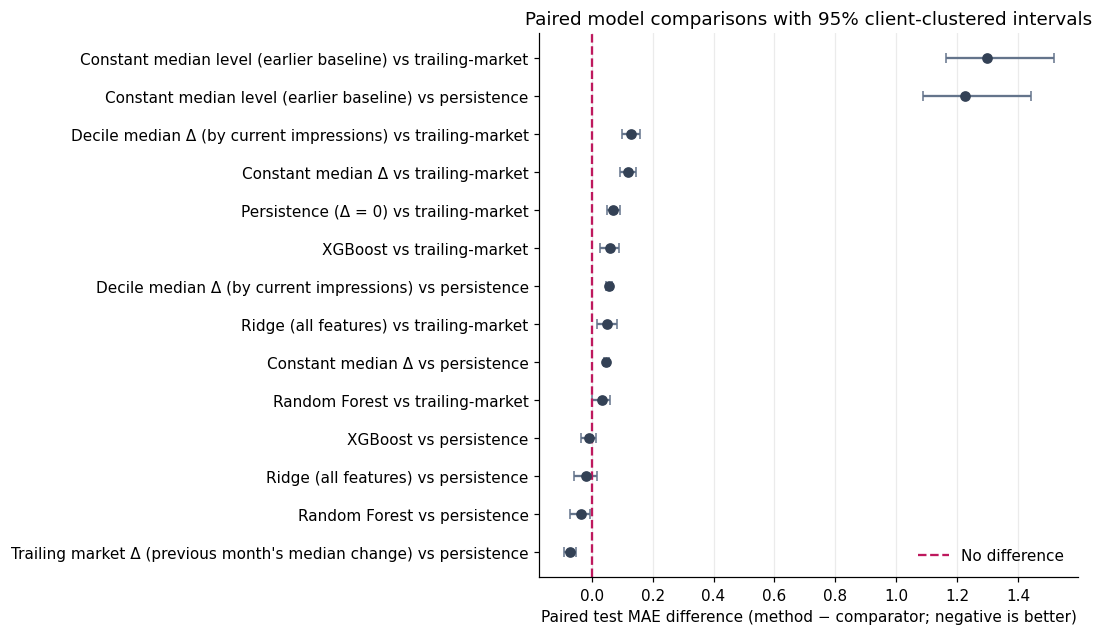

In [ ]:

# Figure 19 — paired-difference forest plot; negative ΔMAE favours the named method.
forest_rows = []
for r in RESULTS["paired_vs_persistence"]:
    forest_rows.append({"comparison": f'{r["model"]} vs persistence', "diff": r["diff"], "lo": r["lo"], "hi": r["hi"]})
for r in RESULTS["paired_vs_trend"]:
    forest_rows.append({"comparison": f'{r["model"]} vs trailing-market', "diff": r["diff"], "lo": r["lo"], "hi": r["hi"]})
forest_df = pd.DataFrame(forest_rows).sort_values("diff")
fig, ax = plt.subplots(figsize=(10, max(4.5, 0.42 * len(forest_df))))
yy = np.arange(len(forest_df))
ax.errorbar(forest_df["diff"], yy,
            xerr=[forest_df["diff"]-forest_df["lo"], forest_df["hi"]-forest_df["diff"]],
            fmt="o", capsize=3, color="#334155", ecolor="#64748B", markersize=6)
ax.axvline(0, color="#BE185D", linestyle="--", linewidth=1.5, label="No difference")
ax.set_yticks(yy); ax.set_yticklabels(forest_df["comparison"])
ax.set_xlabel("Paired test MAE difference (method − comparator; negative is better)")
ax.set_title("Paired model comparisons with 95% client-clustered intervals")
ax.legend(frameon=False); ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig19_paired_difference_forest.png", dpi=190, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)


### 4.3b Volume-weighted view — the queue is about volume, not about 1-impression items

Row-weighted MAE gives a 1-impression item the same weight as a 100,000-impression item, and tiny items are mostly Poisson noise. Two volume-aware views are reported for **every** model and baseline on the same test rows, each paired with persistence **and** with the trend baseline (client-clustered intervals):

* **Impression-weighted MAE** — each row weighted by its current-month impressions.
* **MAE on items with ≥ 100 impressions** — where the log change is not dominated by counting noise.

In [ ]:
def cluster_bootstrap_ratio(num, den, groups, B=1000, seed=SEED):
    """Client-clustered bootstrap CI for sum(num) / sum(den)."""
    codes, uniques = pd.factorize(pd.Series(groups))
    g = len(uniques)
    sn, sd = np.bincount(codes, weights=num, minlength=g), np.bincount(codes, weights=den, minlength=g)
    draws = np.random.default_rng(seed).integers(0, g, size=(B, g))
    lo, hi = np.percentile(sn[draws].sum(1) / sd[draws].sum(1), [2.5, 97.5])
    return float(sn.sum() / sd.sum()), float(lo), float(hi)


y_w, w_w, g_w = XY["test"]["y"], XY["test"]["impr"], XY["test"]["groups"]
big_mask = w_w >= 100
ae_all = {n: np.abs(p_ - y_w) for n, p_ in preds["test"].items()}
w_rows = []
for name, ae in ae_all.items():
    wm, wlo, whi = cluster_bootstrap_ratio(ae * w_w, w_w, g_w)
    bm_, blo, bhi = cluster_bootstrap(ae[big_mask], g_w[big_mask])
    row = {"model": name, "weighted_MAE [95% CI]": fmt_ci(wm, wlo, whi), "MAE items ≥100 impr [95% CI]": fmt_ci(bm_, blo, bhi), "_w": wm, "_big": bm_}
    for tag, ref in (("persistence", PERSIST), ("trend", TREND)):
        if name == ref:
            row[f"weighted Δ vs {tag}"], row[f"≥100 Δ vs {tag}"] = "–", "–"
            continue
        dw, dwlo, dwhi = cluster_bootstrap_ratio((ae - ae_all[ref]) * w_w, w_w, g_w)
        db, dblo, dbhi = cluster_bootstrap((ae - ae_all[ref])[big_mask], g_w[big_mask])
        row[f"weighted Δ vs {tag}"] = f"{dw:+.3f} ({verdict(dwlo, dwhi)})"
        row[f"≥100 Δ vs {tag}"] = f"{db:+.3f} ({verdict(dblo, dbhi)})"
        row[f"_w_{tag}"] = (dw, dwlo, dwhi)
        row[f"_big_{tag}"] = (db, dblo, dbhi)
    w_rows.append(row)
weighted_df = pd.DataFrame(w_rows)
print(f"Items with ≥ 100 impressions: {big_mask.mean():.1%} of test rows, {w_w[big_mask].sum() / w_w.sum():.1%} of test impressions.")
display(weighted_df[[c for c in weighted_df.columns if not c.startswith("_")]])
RESULTS["weighted"] = {"share_rows_ge_100": float(big_mask.mean()), "share_impressions_ge_100": float(w_w[big_mask].sum() / w_w.sum()), "rows": w_rows}

Items with ≥ 100 impressions: 55.2% of test rows, 99.1% of test impressions.


,model,weighted_MAE [95% CI],MAE items ≥100 impr [95% CI],weighted Δ vs persistence,≥100 Δ vs persistence,weighted Δ vs trend,≥100 Δ vs trend
0,Persistence (Δ = 0),"0.582 [0.512, 0.715]","0.778 [0.697, 0.920]",–,–,+0.069 (worse),+0.077 (worse)
1,Trailing market Δ (previous month's median cha...,"0.513 [0.462, 0.630]","0.701 [0.633, 0.839]",-0.069 (better),-0.077 (better),–,–
2,Constant median Δ,"0.642 [0.568, 0.777]","0.831 [0.743, 0.973]",+0.060 (worse),+0.053 (worse),+0.129 (worse),+0.130 (worse)
3,Constant median level (earlier baseline),"3.872 [3.494, 4.079]","1.783 [1.610, 1.905]",+3.290 (worse),+1.005 (worse),+3.359 (worse),+1.082 (worse)
4,Decile median Δ (by current impressions),"0.633 [0.559, 0.772]","0.848 [0.757, 0.993]",+0.051 (worse),+0.070 (worse),+0.121 (worse),+0.146 (worse)
5,Ridge (all features),"0.649 [0.581, 0.796]","0.746 [0.661, 0.882]",+0.068 (indistinguishable),-0.032 (indistinguishable),+0.137 (worse),+0.044 (worse)
6,XGBoost,"0.579 [0.526, 0.697]","0.767 [0.683, 0.919]",-0.003 (indistinguishable),-0.011 (indistinguishable),+0.066 (worse),+0.066 (worse)
7,Random Forest,"0.597 [0.541, 0.686]","0.742 [0.671, 0.872]",+0.015 (indistinguishable),-0.036 (indistinguishable),+0.085 (worse),+0.041 (worse)


### 4.4 Is the model useful for *ranking*, not just for regression error?

A prioritization tool lives or dies on rank quality. Pooled Spearman is dominated by between-client differences, so we also report the **within-client** mean Spearman (what a single client's team would experience) and decile hit-rates.

In [ ]:
def within_client_spearman(pred, split, min_rows=200):
    d = XY[split]
    df = pd.DataFrame({"g": d["groups"], "p": pred, "y": d["y"]})
    vals = [spearmanr(s["p"], s["y"]).statistic for _, s in df.groupby("g") if len(s) >= min_rows and s["p"].nunique() > 1]
    return (float(np.mean(vals)) if vals else float("nan")), len(vals)


def decile_hit_rates(pred, y):
    hi_thr, lo_thr = np.quantile(pred, 0.9), np.quantile(pred, 0.1)
    return {"top_decile_growth_rate": float((y[pred >= hi_thr] > 0).mean()), "base_growth_rate": float((y > 0).mean()),
            "bottom_decile_decline_rate": float((y[pred <= lo_thr] < 0).mean()), "base_decline_rate": float((y < 0).mean())}


rank_rows = []
for name in [SELECTED, other, "Decile median Δ (by current impressions)", "Ridge (all features)"]:
    wc, n_cl = within_client_spearman(preds["test"][name], "test")
    hr = decile_hit_rates(preds["test"][name], XY["test"]["y"])
    rank_rows.append({"model": name, "pooled_Spearman": RESULTS["models"][name]["test"]["Spearman"],
                      "within_client_Spearman": wc, "clients_in_mean": n_cl, **hr})
rank_df = pd.DataFrame(rank_rows)
display(rank_df)
RESULTS["ranking_metrics"] = rank_df.to_dict(orient="records")

,model,pooled_Spearman,within_client_Spearman,clients_in_mean,top_decile_growth_rate,base_growth_rate,bottom_decile_decline_rate,base_decline_rate
0,XGBoost,0.0922,0.0759,41,0.5285,0.2844,0.7364,0.6980
1,Random Forest,0.1623,0.2268,41,0.5103,0.2844,0.7699,0.6980
2,Decile median Δ (by current impressions),-0.0167,-0.1144,41,0.3149,0.2844,0.6153,0.6980
3,Ridge (all features),0.0958,0.1175,41,0.3838,0.2844,0.7901,0.6980


### 4.5 Where does it work? Per month, seen vs. unseen clients, and drift

Validation→test degradation is only meaningful relative to how much the *baseline* degrades. We also compare the selected model with persistence for clients **seen** in training vs. **new** clients, month by month, and run an **adversarial validation** (can a classifier tell training rows from test rows? how, and with what features?).

,segment,rows,clients,MAE_selected,MAE_persistence,ΔMAE_vs_persistence [95% CI],verdict
0,all test rows,389253,46,0.9442,0.9536,"-0.009 [-0.036, 0.016]",indistinguishable
1,clients seen in training,284913,24,0.8970,0.9001,"-0.003 [-0.040, 0.030]",indistinguishable
2,new clients (not in training),104340,22,1.0731,1.0994,"-0.026 [-0.063, 0.005]",indistinguishable
3,month 2026-04,189305,42,0.8236,0.8151,"0.008 [-0.021, 0.035]",indistinguishable
4,month 2026-05,199948,42,1.0584,1.0846,"-0.026 [-0.067, 0.019]",indistinguishable


Adversarial-validation AUC (train vs test rows): 0.883   (0.5 = indistinguishable)


,importance
ga4_day_share,0.4499
prev_known,0.0811
pos_change,0.0612
item_age_months,0.0436
ctr,0.0431
mom_change,0.0337


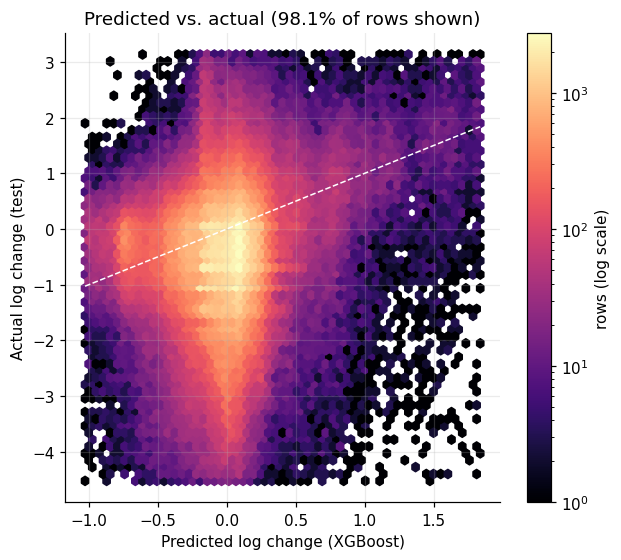

In [ ]:
dt = D["test"]
subsets = {"all test rows": np.ones(len(dt), bool),
           "clients seen in training": dt["seen_client"].to_numpy(),
           "new clients (not in training)": ~dt["seen_client"].to_numpy()}
for m in sorted(dt["month"].astype(str).unique()):
    subsets[f"month {m}"] = (dt["month"].astype(str) == m).to_numpy()

seg_rows = []
for label, mask in subsets.items():
    if mask.sum() < 30 or len(np.unique(XY["test"]["groups"][mask])) < 2:
        continue
    y, g = XY["test"]["y"][mask], XY["test"]["groups"][mask]
    d, lo_, hi_ = paired_diff(preds["test"][SELECTED], preds["test"][PERSIST], mask, split="test")
    seg_rows.append({"segment": label, "rows": int(mask.sum()), "clients": len(np.unique(g)),
                     "MAE_selected": float(np.abs(preds["test"][SELECTED][mask] - y).mean()),
                     "MAE_persistence": float(np.abs(y).mean()), "ΔMAE_vs_persistence [95% CI]": fmt_ci(d, lo_, hi_),
                     "verdict": verdict(lo_, hi_)})
seg_df = pd.DataFrame(seg_rows)
display(seg_df)
RESULTS["segments"] = seg_df.to_dict(orient="records")

# adversarial validation: train (label 0) vs test (label 1)
adv_n = min(60_000, len(D["train"]), len(D["test"]))
adv = pd.concat([D["train"][FEATURES].sample(adv_n, random_state=SEED).assign(_is_test=0),
                 D["test"][FEATURES].sample(adv_n, random_state=SEED).assign(_is_test=1)], ignore_index=True)
cut = np.random.default_rng(SEED).random(len(adv)) < 0.7
adv_clf = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, tree_method="hist", n_jobs=-1, random_state=SEED)
adv_clf.fit(adv.loc[cut, FEATURES], adv.loc[cut, "_is_test"])
auc = float(roc_auc_score(adv.loc[~cut, "_is_test"], adv_clf.predict_proba(adv.loc[~cut, FEATURES])[:, 1]))
adv_imp = pd.Series(adv_clf.feature_importances_, index=FEATURES).sort_values(ascending=False).head(6)
print(f"Adversarial-validation AUC (train vs test rows): {auc:.3f}   (0.5 = indistinguishable)")
display(adv_imp.rename("importance").to_frame())
RESULTS["drift"] = {"adversarial_auc": auc, "top_drift_features": adv_imp.round(4).to_dict()}

# Figure: predicted vs actual change (extreme rows are omitted, not clipped, so no artificial edge pile-ups appear)
sel_pred, y_t = preds["test"][SELECTED], XY["test"]["y"]
xlim, ylim = np.percentile(sel_pred, [0.5, 99.5]), np.percentile(y_t, [0.5, 99.5])
inside = (sel_pred >= xlim[0]) & (sel_pred <= xlim[1]) & (y_t >= ylim[0]) & (y_t <= ylim[1])
fig, ax = plt.subplots(figsize=(5.8, 5.2))
hb = ax.hexbin(sel_pred[inside], y_t[inside], gridsize=55, bins="log", cmap="magma", mincnt=1, extent=(xlim[0], xlim[1], ylim[0], ylim[1]))
dl, dh = max(xlim[0], ylim[0]), min(xlim[1], ylim[1])
ax.plot([dl, dh], [dl, dh], color="white", lw=1, ls="--")
ax.set_xlabel(f"Predicted log change ({SELECTED})"); ax.set_ylabel("Actual log change (test)")
ax.set_title(f"Predicted vs. actual ({inside.mean():.1%} of rows shown)")
fig.colorbar(hb, label="rows (log scale)")
plt.tight_layout()
savefig("fig04_pred_vs_actual")

### 4.6 Signal report: what adds predictive information *beyond persistence*?

This is the **ranking-signal analysis**. Because the label is the change relative to persistence, each feature group is evaluated by how much *out-of-time* error it removes **on top of the previous group**. All steps use XGBoost with the tuned hyperparameters and validation early stopping; the full model (D) is the selected tree model's XGBoost fit.

* **A** — current impression level only (regression to the mean by level)
* **B** — + clicks, CTR, position, active-day share (GSC signals)
* **C** — + month-over-month history (lags, item age)
* **D** — + GA4 / traffic-source / engagement / AI-source features

Differences are **paired** (same rows) with client-clustered 95% intervals. A verdict of *indistinguishable* means the data cannot separate the two — not that the feature group is useless.

,step,n_features,test_MAE [95% CI],ΔMAE vs persistence,verdict vs persistence,ΔMAE vs previous step,incremental verdict
0,A. level only,1,"0.997 [0.894, 1.134]","0.043 [0.032, 0.051]",worse,"0.043 [0.032, 0.051]",worse
1,B. + GSC signals,5,"0.967 [0.862, 1.107]","0.013 [-0.003, 0.024]",indistinguishable,"-0.030 [-0.044, -0.018]",better
2,C. + lag / history,11,"0.958 [0.854, 1.095]","0.004 [-0.010, 0.017]",indistinguishable,"-0.009 [-0.018, 0.004]",indistinguishable
3,D. + GA4 / traffic (full),26,"0.944 [0.839, 1.081]","-0.009 [-0.036, 0.016]",indistinguishable,"-0.014 [-0.033, 0.008]",indistinguishable


GA4-covered test rows only (n=195,208): ΔMAE (D − C) = -0.044 [-0.060, -0.023] → better


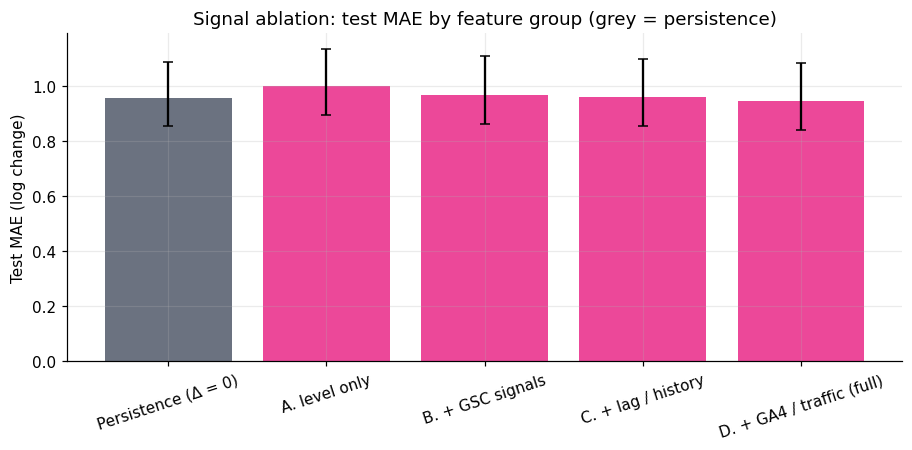

In [ ]:
import xgboost as xgb

ABLATION = [("A. level only", ["log_impr"]), ("B. + GSC signals", G_GSC),
            ("C. + lag / history", G_GSC + G_LAGS), ("D. + GA4 / traffic (full)", FEATURES)]
best_params = XGB_GRID[best_i]
abl_preds = {}
for label, feats in ABLATION:
    if label.startswith("D."):
        abl_preds[label] = xgb_predict(xgb_fits[best_i], D["test"][feats])      # same fit as the tuned model
    else:
        m = fit_xgb(best_params, D["train"][feats], ytr, D["validation"][feats], yva)
        abl_preds[label] = xgb_predict(m, D["test"][feats])
        del m
        gc.collect()

zero = preds["test"][PERSIST]
abl_rows, prev_label = [], PERSIST
prev_pred = zero
for label, feats in ABLATION:
    p = abl_preds[label]
    mae_, lo_, hi_ = cluster_bootstrap(np.abs(p - XY["test"]["y"]), XY["test"]["groups"])
    dv, dlo, dhi = paired_diff(p, zero, "test")
    di, ilo, ihi = paired_diff(p, prev_pred, "test")
    abl_rows.append({"step": label, "n_features": len(feats), "test_MAE [95% CI]": fmt_ci(mae_, lo_, hi_),
                     "ΔMAE vs persistence": fmt_ci(dv, dlo, dhi), "verdict vs persistence": verdict(dlo, dhi),
                     "ΔMAE vs previous step": fmt_ci(di, ilo, ihi), "incremental verdict": verdict(ilo, ihi),
                     "_mae": mae_, "_lo": lo_, "_hi": hi_, "_inc": (di, ilo, ihi)})
    prev_pred = p
abl_df = pd.DataFrame(abl_rows)
display(abl_df.drop(columns=["_mae", "_lo", "_hi", "_inc"]))

# GA4-covered subset: does the GA4 block help where GA4 data actually exists?
ga4_mask = D["test"]["has_ga4"].to_numpy(bool)
if ga4_mask.sum() >= 100 and len(np.unique(XY["test"]["groups"][ga4_mask])) >= 3:
    dd, dlo, dhi = paired_diff(abl_preds["D. + GA4 / traffic (full)"], abl_preds["C. + lag / history"], ga4_mask, split="test")
    ga4_subset = {"rows": int(ga4_mask.sum()), "diff": dd, "lo": dlo, "hi": dhi, "verdict": verdict(dlo, dhi)}
    print(f"GA4-covered test rows only (n={ga4_mask.sum():,}): ΔMAE (D − C) = {fmt_ci(dd, dlo, dhi)} → {verdict(dlo, dhi)}")
else:
    ga4_subset = None
    print("Too few GA4-covered test rows / clients for a subset comparison.")

RESULTS["ablation"] = {"rows": [{k: v for k, v in r.items()} for r in abl_rows], "ga4_subset": ga4_subset,
                       "persistence_mae": persist_mae}

fig, ax = plt.subplots(figsize=(8.4, 4.2))
labels = [PERSIST] + [r["step"] for r in abl_rows]
maes = [persist_mae] + [r["_mae"] for r in abl_rows]
los = [persist_mae - RESULTS["models"][PERSIST]["test"]["MAE_lo"]] + [r["_mae"] - r["_lo"] for r in abl_rows]
his = [RESULTS["models"][PERSIST]["test"]["MAE_hi"] - persist_mae] + [r["_hi"] - r["_mae"] for r in abl_rows]
ax.bar(labels, maes, yerr=[los, his], capsize=3, color=[PALETTE["Persistence"]] + [PALETTE["XGBoost"]] * len(abl_rows))
ax.set_ylabel("Test MAE (log change)"); ax.set_title("Signal ablation: test MAE by feature group (grey = persistence)")
ax.tick_params(axis="x", rotation=18)
plt.tight_layout()
savefig("fig05_signal_ablation")

### 4.7 Explainability: three views of the same model, and whether they agree

1. **Model-native importance** (gain for XGBoost; impurity for Random Forest) — fast but biased toward high-cardinality, correlated features.
2. **Permutation importance** on 30k validation rows — increase in MAE when a feature is shuffled.
3. **SHAP** (TreeSHAP) on a fixed random sample of test rows. For XGBoost, TreeSHAP values are obtained from the booster's native `pred_contribs`, which are exact SHAP values and avoid version-compatibility problems; for Random Forest, `shap.TreeExplainer` is used on a smaller sample.

Clicks, impressions and CTR are mathematically linked and several lag/level features are correlated, so importance is **shared among correlated features**; none of these measures is causal.

,model_native_%,permutation_%,mean_|SHAP|_%,mean_rank
active_day_share,6.5833,37.3536,15.1687,2.3333
avg_position,7.8169,3.8695,13.1144,3.6667
mom_change,6.5320,19.7663,14.1779,3.6667
ctr,6.9759,2.7157,6.8905,5.3333
item_age_months,6.1951,7.2437,11.7988,5.3333
log_impr,3.9618,27.9780,12.0355,5.6667
log_clicks,5.1759,0.5476,3.0554,8.6667
log_scroll_events,12.1288,0.0000,5.8723,9.5000
has_ga4,14.2673,0.0000,1.3034,11.1667
log_sessions,5.9662,0.0000,5.1675,11.8333


Rank agreement between importance methods (Spearman): {'native_vs_permutation': 0.41, 'native_vs_shap': 0.87, 'permutation_vs_shap': 0.63}
Combined share of importance carried by the 15 GA4/traffic features: {'model_native': '47.6%', 'permutation': '0.1%', 'shap': '20.1%'}
Spearman(has_ga4, calendar month) in training = 0.25; Spearman(ga4_day_share, month) = 0.25  → values well above 0 mean GA4 features can act as time indicators rather than as behavioural signals.


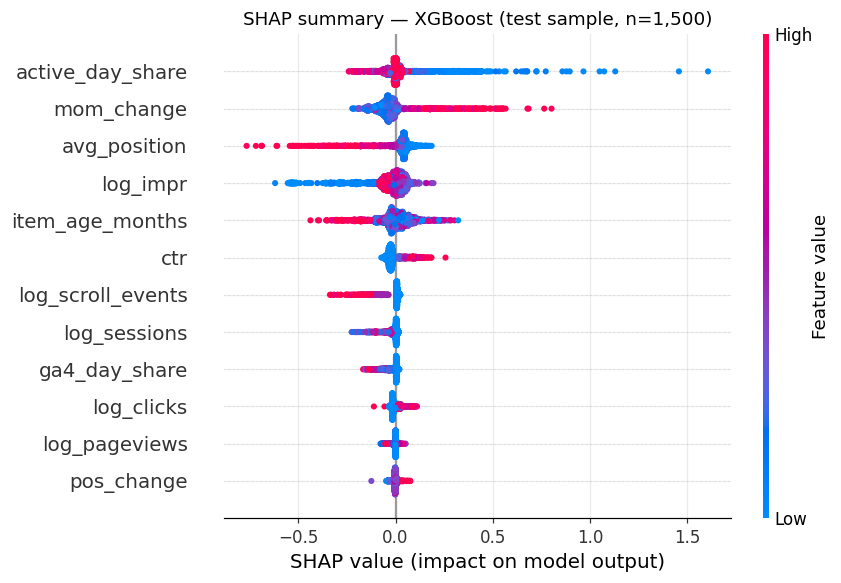

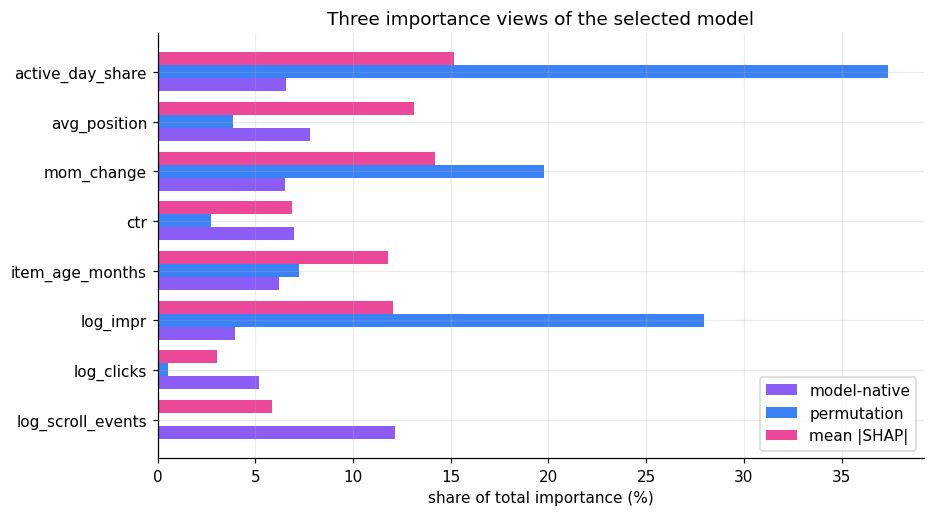

In [ ]:
sel_model = MODELS[SELECTED]
native = pd.Series(sel_model.feature_importances_, index=FEATURES)
native_pct = 100 * native / native.sum()

def perm_importance(name, X, y, n_repeats=3, seed=SEED):
    rs = np.random.default_rng(seed)
    base_mae = float(np.abs(predict_model(name, X) - y).mean())
    out = {}
    for f in FEATURES:
        deltas = []
        for _ in range(n_repeats):
            # Shallow base + one temporary permuted column; avoid an extra full matrix copy.
            Xp = X.assign(**{f: rs.permutation(X[f].to_numpy())})
            deltas.append(float(np.abs(predict_model(name, Xp) - y).mean()) - base_mae)
            del Xp
        out[f] = float(np.mean(deltas))
    return pd.Series(out)

vs = D["validation"].sample(min(30_000, len(D["validation"])), random_state=SEED)
perm = perm_importance(SELECTED, vs[FEATURES], vs["y_delta"].to_numpy())
perm_pct = 100 * perm.clip(lower=0) / max(perm.clip(lower=0).sum(), 1e-12)

n_shap = 1500 if SELECTED == "XGBoost" else 400
Xs = D["test"][FEATURES].sample(min(n_shap, len(D["test"])), random_state=SEED).reset_index(drop=True)
if SELECTED == "XGBoost":
    it = int(sel_model.best_iteration)
    contrib = sel_model.get_booster().predict(xgb.DMatrix(Xs), pred_contribs=True, iteration_range=(0, it + 1))
    shap_vals = contrib[:, :-1]
else:
    import shap as _shap
    shap_vals = _shap.TreeExplainer(sel_model).shap_values(Xs)
shap_abs = pd.Series(np.abs(shap_vals).mean(axis=0), index=FEATURES)
shap_pct = 100 * shap_abs / shap_abs.sum()

imp = pd.DataFrame({"model_native_%": native_pct, "permutation_%": perm_pct, "mean_|SHAP|_%": shap_pct})
imp["mean_rank"] = imp.rank(ascending=False).mean(axis=1)
imp = imp.sort_values("mean_rank")
display(imp.head(12))

agree = {"native_vs_permutation": spearmanr(imp["model_native_%"], imp["permutation_%"]).statistic,
         "native_vs_shap": spearmanr(imp["model_native_%"], imp["mean_|SHAP|_%"]).statistic,
         "permutation_vs_shap": spearmanr(imp["permutation_%"], imp["mean_|SHAP|_%"]).statistic}
print("Rank agreement between importance methods (Spearman):", {k: round(float(v), 2) for k, v in agree.items()})
ga4_share = {"model_native": float(imp.loc[G_GA4, "model_native_%"].sum()), "permutation": float(imp.loc[G_GA4, "permutation_%"].sum()),
             "shap": float(imp.loc[G_GA4, "mean_|SHAP|_%"].sum())}
print("Combined share of importance carried by the 15 GA4/traffic features:", {k: f"{v:.1f}%" for k, v in ga4_share.items()})
# Are the GA4 features acting as a calendar proxy? (GA4 coverage rises over time, so "has GA4" can simply mean "late in training".)
_tr = D["train"]
ga4_time_rho = float(spearmanr(_tr["has_ga4"], _tr["month_idx"]).statistic)
ga4_time_rho_share = float(spearmanr(_tr["ga4_day_share"], _tr["month_idx"]).statistic)
print(f"Spearman(has_ga4, calendar month) in training = {ga4_time_rho:.2f}; Spearman(ga4_day_share, month) = {ga4_time_rho_share:.2f}  "
      "→ values well above 0 mean GA4 features can act as time indicators rather than as behavioural signals.")
RESULTS["importance"] = {"top_features": imp.head(10).round(3).reset_index().rename(columns={"index": "feature"}).to_dict(orient="records"),
                         "rank_agreement": {k: float(v) for k, v in agree.items()}, "ga4_importance_share": ga4_share,
                         "shap_sample_size": int(len(Xs)), "model_explained": SELECTED,
                         "ga4_time_proxy_rho": ga4_time_rho}

try:
    import shap
    plt.figure(figsize=(8, 5.4))
    shap.summary_plot(shap_vals, Xs, max_display=12, show=False, plot_size=None)
    plt.title(f"SHAP summary — {SELECTED} (test sample, n={len(Xs):,})")
    plt.tight_layout()
    savefig("fig06_shap_beeswarm")
except Exception as exc:                                          # plotting must never break the run
    print(f"[note] SHAP beeswarm skipped ({type(exc).__name__}); falling back to a bar chart.")
    top = shap_abs.sort_values().tail(12)
    plt.figure(figsize=(8, 5)); plt.barh(top.index, top.values, color=PALETTE["accent"])
    plt.xlabel("mean |SHAP|"); plt.title(f"Mean |SHAP| — {SELECTED}"); plt.tight_layout()
    savefig("fig06_shap_beeswarm")

top8 = imp.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.6, 4.8))
h = 0.26
yy = np.arange(len(top8))
ax.barh(yy - h, top8["model_native_%"], h, label="model-native", color=PALETTE["Random Forest"])
ax.barh(yy, top8["permutation_%"], h, label="permutation", color=PALETTE["Ridge"])
ax.barh(yy + h, top8["mean_|SHAP|_%"], h, label="mean |SHAP|", color=PALETTE["XGBoost"])
ax.set_yticks(yy); ax.set_yticklabels(top8.index); ax.set_xlabel("share of total importance (%)")
ax.set_title("Three importance views of the selected model"); ax.legend()
plt.tight_layout()
savefig("fig07_importance_agreement")

### 4.8 Error analysis — where is the model unreliable?

Error is broken down by current-impression quartile, **with the signed bias** (does it systematically over- or under-predict?) and the comparison against persistence in each band. The largest errors are then inspected to see whether they are zero-impression labels (an absent next-month row *or* a present row with zero impressions).

,current_impressions,rows,median_impressions,MAE_selected,MAE_persistence,bias (mean signed err),ΔMAE vs persistence [95% CI],verdict
0,"(0.999, 23.0]",99098,6.0000,1.1378,1.1422,0.5186,"-0.004 [-0.024, 0.009]",indistinguishable
1,"(23.0, 140.0]",95854,61.0000,1.1645,1.1739,0.7393,"-0.009 [-0.042, 0.022]",indistinguishable
2,"(140.0, 756.0]",97021,315.0000,0.8506,0.8570,0.5358,"-0.006 [-0.037, 0.027]",indistinguishable
3,"(756.0, 799358.0]",97280,"2,280.0000",0.6232,0.6406,0.3331,"-0.017 [-0.064, 0.030]",indistinguishable


Absolute error distribution: {'MAE': 0.944, 'median': 0.695, 'p90': 2.105, 'p95': 2.745, 'max': 9.157, 'mean_signed_error': 0.531}
Worst 1% of errors: 64.4% have zero next-month impressions (vs 9.6% of all test rows); 91.0% are over-predictions.


,impressions,next_impressions,pred_next_impr,avg_position,next_zero,next_missing,cur_cov,next_cov,abs_err
26919,"3,867.0000",0.0000,"9,476.0624",5.8477,True,False,1.0000,1.0000,9.1566
302047,"16,527.0000",2.0000,"9,911.5231",77.2702,False,False,1.0000,1.0000,8.1029
87319,"3,329.0000",0.0000,"3,003.3852",9.2691,True,False,1.0000,1.0000,8.0078
113477,"4,971.0000",0.0000,"2,928.2273",77.0760,True,False,1.0000,1.0000,7.9825
340140,"2,738.0000",0.0000,"2,922.8061",2.2075,True,False,1.0000,1.0000,7.9806
1066,"5,380.0000",1.0000,"4,904.6336",7.3810,False,False,1.0000,1.0000,7.8050
21480,"2,655.0000",0.0000,"2,396.8170",2.1608,True,False,1.0000,1.0000,7.7823
219897,"8,932.0000",3.0000,"9,113.2904",6.8071,False,False,1.0000,1.0000,7.7313
171917,471.0000,0.0000,"1,975.4257",30.4607,True,False,1.0000,1.0000,7.5890
237449,"2,360.0000",0.0000,"1,930.8960",6.3661,True,False,1.0000,1.0000,7.5663


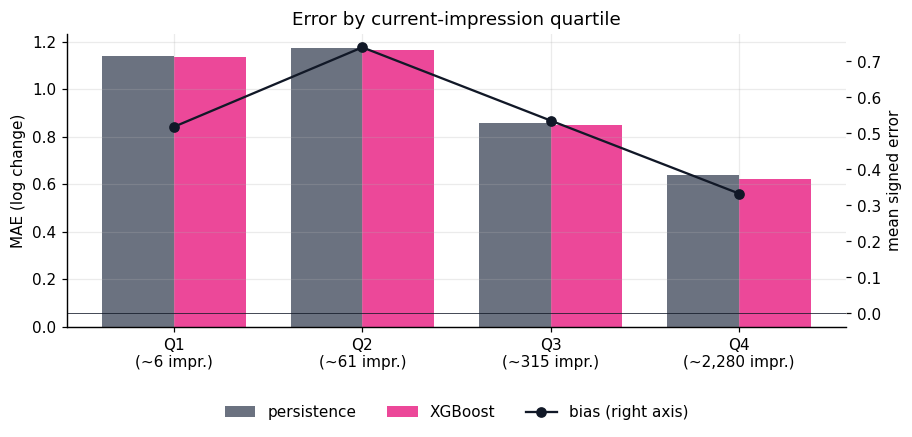

In [ ]:
d_t = D["test"].copy()
d_t["pred_delta"] = preds["test"][SELECTED]
d_t["err"] = d_t["pred_delta"] - d_t["y_delta"]
d_t["abs_err"] = d_t["err"].abs()
d_t["abs_err_persist"] = d_t["y_delta"].abs()
d_t["pred_next_impr"] = np.expm1(d_t["log_impr"] + d_t["pred_delta"]).clip(lower=0)
d_t["band"] = pd.qcut(d_t["impressions"], 4, duplicates="drop")

band_rows = []
for b, g in d_t.groupby("band", observed=True):
    mask = (d_t["band"] == b).to_numpy()
    dd, lo_, hi_ = paired_diff(preds["test"][SELECTED], zero, mask, split="test")
    band_rows.append({"current_impressions": str(b), "rows": len(g), "median_impressions": g["impressions"].median(),
                      "MAE_selected": g["abs_err"].mean(), "MAE_persistence": g["abs_err_persist"].mean(),
                      "bias (mean signed err)": g["err"].mean(), "ΔMAE vs persistence [95% CI]": fmt_ci(dd, lo_, hi_),
                      "verdict": verdict(lo_, hi_)})
band_df = pd.DataFrame(band_rows)
display(band_df)

ae = d_t["abs_err"]
overall_err = {"MAE": float(ae.mean()), "median": float(ae.median()), "p90": float(ae.quantile(.9)),
               "p95": float(ae.quantile(.95)), "max": float(ae.max()), "mean_signed_error": float(d_t["err"].mean())}
print("Absolute error distribution:", {k: round(v, 3) for k, v in overall_err.items()})

top_cut = ae.quantile(0.99)
worst = d_t[ae >= top_cut]
tz_all, tz_worst = float(d_t["next_zero"].mean()), float(worst["next_zero"].mean())
over_worst = float((worst["err"] > 0).mean())
print(f"Worst 1% of errors: {tz_worst:.1%} have zero next-month impressions (vs {tz_all:.1%} of all test rows); "
      f"{over_worst:.1%} are over-predictions.")
show(worst.sort_values("abs_err", ascending=False)[["impressions", "next_impressions", "pred_next_impr", "avg_position",
                                                    "next_zero", "next_missing", "cur_cov", "next_cov", "abs_err"]], n=10)
RESULTS["error_analysis"] = {"bands": band_df.to_dict(orient="records"), "overall": overall_err,
                             "worst1pct_zero_label_share": tz_worst, "all_zero_label_share": tz_all,
                             "worst1pct_overprediction_share": over_worst}

fig, ax = plt.subplots(figsize=(8.4, 4.2))
xx = np.arange(len(band_df)); w = 0.38
ax.bar(xx - w / 2, band_df["MAE_persistence"], w, color=PALETTE["Persistence"], label="persistence")
ax.bar(xx + w / 2, band_df["MAE_selected"], w, color=PALETTE["XGBoost"], label=SELECTED)
ax2 = ax.twinx(); ax2.plot(xx, band_df["bias (mean signed err)"], color=PALETTE["ink"], marker="o", label="bias (right axis)")
ax2.axhline(0, color=PALETTE["ink"], lw=0.5); ax2.grid(False)
ax.set_xticks(xx); ax.set_xticklabels([f"Q{i + 1}\n(~{int(m):,} impr.)" for i, m in enumerate(band_df["median_impressions"])])
ax.set_ylabel("MAE (log change)"); ax2.set_ylabel("mean signed error"); ax.set_title("Error by current-impression quartile")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
plt.tight_layout()
savefig("fig08_error_by_band")

### 4.9 Robustness checks (no refitting — same predictions, stricter evaluation sets)

In [ ]:
rob_rows = []
checks = {"all test rows": np.ones(len(d_t), bool),
          f"strict feed health (≥{ROBUSTNESS_COVERAGE:.0%} in current and next month)": ((d_t["cur_cov"] >= ROBUSTNESS_COVERAGE) & (d_t["next_cov"] >= ROBUSTNESS_COVERAGE)).to_numpy(),
          "excluding zero-impression labels (absent or present-but-zero)": (~d_t["next_zero"]).to_numpy(),
          "excluding the largest client": (d_t["client_hash_id"] != d_t["client_hash_id"].value_counts().index[0]).to_numpy(),
          "items with ≥ 2 prior months of history": (d_t["item_age_months"] >= 2).to_numpy(),
          "items with ≥ 100 impressions": (d_t["impressions"] >= 100).to_numpy()}
trend_t = preds["test"][TREND]
for label, mask in checks.items():
    if mask.sum() < 100 or len(np.unique(XY["test"]["groups"][mask])) < 2:
        continue
    dd, lo_, hi_ = paired_diff(preds["test"][SELECTED], zero, mask, split="test")
    dt_, tlo_, thi_ = paired_diff(preds["test"][SELECTED], trend_t, mask, split="test")
    rob_rows.append({"evaluation set": label, "rows": int(mask.sum()),
                     "MAE_selected": float(d_t.loc[mask, "abs_err"].mean()), "MAE_persistence": float(d_t.loc[mask, "abs_err_persist"].mean()),
                     "MAE_trend": float(np.abs(trend_t[mask] - XY["test"]["y"][mask]).mean()),
                     "ΔMAE vs persistence [95% CI]": fmt_ci(dd, lo_, hi_), "verdict vs persistence": verdict(lo_, hi_),
                     "ΔMAE vs trend [95% CI]": fmt_ci(dt_, tlo_, thi_), "verdict vs trend": verdict(tlo_, thi_)})
rob_df = pd.DataFrame(rob_rows)
display(rob_df)
RESULTS["robustness"] = rob_df.to_dict(orient="records")

,evaluation set,rows,MAE_selected,MAE_persistence,MAE_trend,ΔMAE vs persistence [95% CI],verdict vs persistence,ΔMAE vs trend [95% CI],verdict vs trend
0,all test rows,389253,0.9442,0.9536,0.8836,"-0.009 [-0.036, 0.016]",indistinguishable,"0.061 [0.027, 0.090]",worse
1,strict feed health (≥95% in current and next m...,389247,0.9442,0.9536,0.8836,"-0.009 [-0.035, 0.016]",indistinguishable,"0.061 [0.029, 0.089]",worse
2,excluding zero-impression labels (absent or pr...,351990,0.8250,0.8329,0.7819,"-0.008 [-0.036, 0.018]",indistinguishable,"0.043 [0.009, 0.071]",worse
3,excluding the largest client,329765,0.9924,0.9969,0.9214,"-0.005 [-0.035, 0.022]",indistinguishable,"0.071 [0.035, 0.095]",worse
4,items with ≥ 2 prior months of history,284129,0.8732,0.8720,0.7888,"0.001 [-0.034, 0.033]",indistinguishable,"0.084 [0.053, 0.116]",worse
5,items with ≥ 100 impressions,214738,0.7670,0.7781,0.7013,"-0.011 [-0.046, 0.025]",indistinguishable,"0.066 [0.032, 0.104]",worse


### 4.10 Walk-forward retraining — the deployment protocol *(added after the first test evaluation)*

The single train/validation/test split asks a model trained once on 2025 to forecast 2026 — which cannot adapt when the market changes direction (§2.7). In deployment a forecast made at the end of month *t* would be produced by a model retrained on **every label already resolved by then**. This section evaluates exactly that, month by month across the validation **and** test months:

* **Walk-forward XGBoost:** for each forecast month *t*, fit on all labeled rows with feature month ≤ *t* − 1 (their labels are resolved by the end of *t*), predict month *t*.
* **Walk-forward XGBoost on the trend residual:** the same, but the model learns `y − trailing market change` and the prediction is `trend + model`. It asks whether **item-level signals add anything on top of the trend**.

**Honest labelling.** This protocol was added *after* the single-split test results were seen, so it is a **post-hoc design**: hyperparameters are exactly those tuned on the validation months (no new tuning), it is reported *alongside* — never instead of — the pre-registered single-split results of §4.3, and it should be read as a hypothesis for the next data window, not as a replacement verdict. Comparators are the same persistence and trend baselines.

Walk-forward retraining: 5 forecast months, 57 boosting rounds, hyperparameters from §4.2 (no new tuning).

Test months only:


,window,method,MAE [95% CI],weighted MAE,Δ vs persistence [95% CI],verdict vs persistence,Δ vs trend [95% CI],verdict vs trend
0,test months,Persistence (Δ = 0),"0.954 [0.852, 1.088]",0.5819,–,–,"0.070 [0.050, 0.092]",worse
1,test months,Trailing market Δ (previous month's median cha...,"0.884 [0.795, 1.008]",0.5126,"-0.070 [-0.092, -0.050]",better,–,–
2,test months,Static XGBoost (trained once on 2025),"0.944 [0.839, 1.081]",0.5787,"-0.009 [-0.036, 0.016]",indistinguishable,"0.061 [0.027, 0.090]",worse
3,test months,Walk-forward XGBoost,"0.906 [0.805, 1.040]",0.5484,"-0.048 [-0.064, -0.033]",better,"0.022 [-0.002, 0.042]",indistinguishable
4,test months,Walk-forward XGBoost on trend residual,"0.855 [0.781, 0.961]",0.5427,"-0.098 [-0.144, -0.058]",better,"-0.028 [-0.058, -0.003]",better



All out-of-sample months (validation + test):


,window,method,MAE [95% CI],weighted MAE,Δ vs persistence [95% CI],verdict vs persistence,Δ vs trend [95% CI],verdict vs trend
0,validation + test months,Persistence (Δ = 0),"0.862 [0.765, 1.001]",0.5106,–,–,"0.021 [0.003, 0.037]",worse
1,validation + test months,Trailing market Δ (previous month's median cha...,"0.841 [0.748, 0.981]",0.5012,"-0.021 [-0.037, -0.003]",better,–,–
2,validation + test months,Static XGBoost (trained once on 2025),"0.845 [0.744, 0.994]",0.5170,"-0.016 [-0.036, 0.005]",indistinguishable,"0.005 [-0.016, 0.024]",indistinguishable
3,validation + test months,Walk-forward XGBoost,"0.829 [0.728, 0.977]",0.5020,"-0.032 [-0.047, -0.017]",better,"-0.012 [-0.028, 0.005]",indistinguishable
4,validation + test months,Walk-forward XGBoost on trend residual,"0.812 [0.726, 0.944]",0.5122,"-0.049 [-0.074, -0.029]",better,"-0.028 [-0.044, -0.016]",better



Best walk-forward variant on the test months: Walk-forward XGBoost on trend residual (vs persistence: better; vs trend: better).


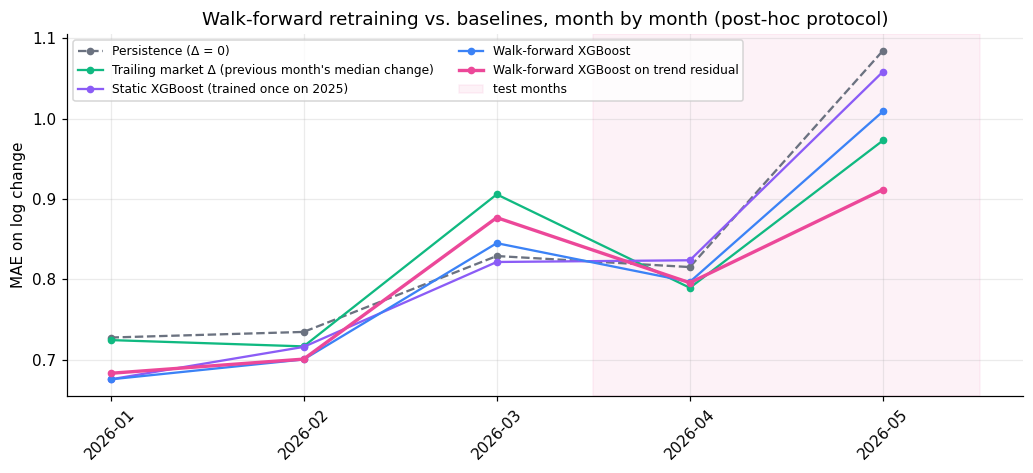

In [ ]:
oos = pd.concat([D["validation"], D["test"]], ignore_index=True)
oos_months = sorted(oos["month_idx"].unique())
y_o, g_o, m_o = oos["y_delta"].to_numpy(float), oos["client_hash_id"].to_numpy(), oos["month_idx"].to_numpy()
w_o = oos["impressions"].to_numpy(float)
trend_o = trail_by_month.reindex(m_o - 1).fillna(med_delta).to_numpy()
WF_ROUNDS = max(int(RESULTS["selection"]["xgb_best_round"]), 50)

wf_level, wf_resid = np.zeros(len(oos)), np.zeros(len(oos))
for m in oos_months:
    tr_m = lab[lab["month_idx"] <= m - 1]                       # labels of these rows are resolved by the end of month m
    assert tr_m["month_idx"].max() <= m - 1, "walk-forward training set contains an unresolved label"
    te = m_o == m
    X_te = oos.loc[te, FEATURES]
    mdl = fit_xgb(XGB_GRID[best_i], tr_m[FEATURES], tr_m["y_delta"].to_numpy(float), n_estimators=WF_ROUNDS, early=False)
    wf_level[te] = xgb_predict(mdl, X_te)
    del mdl
    tr_trend = trail_by_month.reindex(tr_m["month_idx"] - 1).fillna(med_delta).to_numpy()
    mdl_r = fit_xgb(XGB_GRID[best_i], tr_m[FEATURES], tr_m["y_delta"].to_numpy(float) - tr_trend, n_estimators=WF_ROUNDS, early=False)
    wf_resid[te] = trend_o[te] + xgb_predict(mdl_r, X_te)
    del mdl_r, tr_m, X_te
    gc.collect()

STATIC = f"Static {SELECTED} (trained once on 2025)"
WF_LEVEL, WF_RESID = "Walk-forward XGBoost", "Walk-forward XGBoost on trend residual"          # always XGBoost (tuned hyperparameters), whichever model was selected
methods = {PERSIST: np.zeros(len(oos)), TREND: trend_o,
           STATIC: np.concatenate([preds["validation"][SELECTED], preds["test"][SELECTED]]),
           WF_LEVEL: wf_level, WF_RESID: wf_resid}
ae_o = {n: np.abs(p_ - y_o) for n, p_ in methods.items()}
test_idx = {month_idx(m) for m in SPLITS["test"]}
is_test_o = np.isin(m_o, list(test_idx))


def wf_table(mask, label):
    rows = []
    for n in methods:
        mae_, lo_, hi_ = cluster_bootstrap(ae_o[n][mask], g_o[mask])
        wm, wlo, whi = cluster_bootstrap_ratio(ae_o[n][mask] * w_o[mask], w_o[mask], g_o[mask])
        row = {"window": label, "method": n, "MAE [95% CI]": fmt_ci(mae_, lo_, hi_), "weighted MAE": wm, "_mae": mae_}
        for tag, ref in (("persistence", PERSIST), ("trend", TREND)):
            if n == ref:
                row[f"Δ vs {tag} [95% CI]"], row[f"verdict vs {tag}"] = "–", "–"
                continue
            d_, dlo, dhi = cluster_bootstrap((ae_o[n] - ae_o[ref])[mask], g_o[mask])
            row[f"Δ vs {tag} [95% CI]"], row[f"verdict vs {tag}"], row[f"_d_{tag}"] = fmt_ci(d_, dlo, dhi), verdict(dlo, dhi), (d_, dlo, dhi)
        rows.append(row)
    return pd.DataFrame(rows)


wf_test, wf_all = wf_table(is_test_o, "test months"), wf_table(np.ones(len(oos), bool), "validation + test months")
show_cols = lambda d: d[[c for c in d.columns if not c.startswith("_")]]
print(f"Walk-forward retraining: {len(oos_months)} forecast months, {WF_ROUNDS} boosting rounds, hyperparameters from §4.2 (no new tuning).")
print("\nTest months only:"); display(show_cols(wf_test))
print("\nAll out-of-sample months (validation + test):"); display(show_cols(wf_all))

by_month = (pd.DataFrame({"month_idx": m_o, **{n: a for n, a in ae_o.items()}}).groupby("month_idx").mean().reset_index())
by_month["month"] = [str(pd.Period(year=(i - 1) // 12, month=(i - 1) % 12 + 1, freq="M")) for i in by_month["month_idx"]]
wf_best = wf_test.loc[wf_test["method"].isin([WF_LEVEL, WF_RESID])].sort_values("_mae").iloc[0]
RESULTS["walk_forward"] = {"rounds": WF_ROUNDS, "months": [str(m) for m in by_month["month"]],
                           "test_table": wf_test.to_dict(orient="records"), "all_table": wf_all.to_dict(orient="records"),
                           "best_walk_forward_on_test": wf_best["method"], "post_hoc": True,
                           "by_month_mae": by_month.drop(columns="month_idx").to_dict(orient="records")}
print(f"\nBest walk-forward variant on the test months: {wf_best['method']} (vs persistence: {wf_best['verdict vs persistence']}; vs trend: {wf_best['verdict vs trend']}).")

fig, ax = plt.subplots(figsize=(9.5, 4.4))
styl = {PERSIST: (PALETTE["Persistence"], "--"), TREND: ("#10B981", "-"), STATIC: (PALETTE["Random Forest"], "-"),
        WF_LEVEL: (PALETTE["Ridge"], "-"), WF_RESID: (PALETTE["accent"], "-")}
for n, (c_, ls_) in styl.items():
    ax.plot(by_month["month"], by_month[n], color=c_, ls=ls_, marker="o", ms=4, lw=2.2 if n == WF_RESID else 1.5, label=n)
first_test = min(test_idx)
ax.axvspan(by_month.index[by_month["month_idx"] == first_test][0] - 0.5, len(by_month) - 0.5, color="#EC4899", alpha=0.07, label="test months")
ax.set_ylabel("MAE on log change"); ax.set_title("Walk-forward retraining vs. baselines, month by month (post-hoc protocol)")
ax.tick_params(axis="x", rotation=45); ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
savefig("fig14_walk_forward")

## 5. Performance archetypes → actions (and a test of whether they mean anything)

**Design.** Archetypes group content items by *how they currently perform*, using five transformed signals: `log1p(impressions)`, `log1p(clicks)`, `sqrt(CTR)`, `log(position)` and clipped month-over-month change. (Raw counts are heavy-tailed; log/sqrt transforms stop a handful of outliers from defining the clusters. GA4 features are excluded because they are mostly zeros in training — see §2.8.)

**Micro-volume items are not clustered.** Items with fewer than `CLUSTER_MIN_IMPR` impressions have a CTR and a month-over-month change that are counting noise (one click on 20 impressions is a 5% "CTR"), and in earlier runs they formed spurious "performer" clusters. They form an explicit micro-volume bucket mapped to *Monitor*.

**How *k* is chosen (rule fixed in advance).** Candidates k = 3…8. A candidate is *eligible* if (i) its smallest cluster holds ≥ 3% of rows and (ii) clustering is **stable** — two models fit on disjoint halves of the training data agree on a hold-out sample (adjusted Rand index ≥ 0.60). Among eligible candidates the best silhouette wins; if none is eligible the notebook says so and falls back to the most stable candidate.

**Names are behavioural, not semantic.** Each cluster is named by rules applied to its **training-set medians** (volume, momentum, position, CTR relative to the client's *peer expectation* from §2.6) — never by page type, which the release does not contain. Each name maps to a playbook action. *Merge* needs query- or text-level overlap the release does not contain, so consolidation appears only as a monitored "review" note.

**Validation gate (fixed in advance).** Archetypes are only used as *evidence* if, on the **held-out test months**, (a) the archetype label explains at least 2% of the variance of next-month change (η²) beyond a permutation null (p < 0.01), **and** (b) predicting each item's change by its archetype's training-median change **beats persistence** (paired, client-clustered). Otherwise they are reported as **descriptive only** and the action map is presented as a review heuristic, not a validated policy.

In [ ]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

for s_ in SPLITS:
    exp_ = D[s_]["expected_ctr"].to_numpy()
    D[s_]["ctr_ratio"] = np.where(exp_ > 0, D[s_]["ctr"].to_numpy() / np.where(exp_ > 0, exp_, 1.0), np.nan)

CLUSTER_FEATS = ["log impressions", "log clicks", "sqrt CTR", "log position", "momentum (clipped)"]

def cluster_matrix(df):
    return np.column_stack([df["log_impr"], df["log_clicks"], np.sqrt(df["ctr"].clip(0, 1)),
                            np.log(df["avg_position"].clip(lower=1)), df["mom_change"].clip(-3, 3)])

fit_tr = (D["train"]["impressions"] >= CLUSTER_MIN_IMPR).to_numpy()          # micro-volume items are NOT clustered (counting noise)
scaler_c = StandardScaler().fit(cluster_matrix(D["train"])[fit_tr])
Z = {s: scaler_c.transform(cluster_matrix(D[s])) for s in SPLITS}
Z_tr = Z["train"][fit_tr]

rs = np.random.default_rng(SEED)
n_tr = len(Z_tr)
idx_fit  = rs.choice(n_tr, size=min(100_000, n_tr), replace=False)
idx_sil  = rs.choice(n_tr, size=min(15_000, n_tr), replace=False)
idx_hold = rs.choice(n_tr, size=min(30_000, n_tr), replace=False)
perm_idx = rs.permutation(n_tr)
half_a, half_b = perm_idx[: n_tr // 2][:50_000], perm_idx[n_tr // 2:][:50_000]

sel_rows = []
for k in range(3, 9):
    km = MiniBatchKMeans(n_clusters=k, random_state=SEED, batch_size=4096, n_init=5).fit(Z_tr[idx_fit])
    sil = float(silhouette_score(Z_tr[idx_sil], km.predict(Z_tr[idx_sil])))
    ka = MiniBatchKMeans(n_clusters=k, random_state=SEED, batch_size=4096, n_init=5).fit(Z_tr[half_a])
    kb = MiniBatchKMeans(n_clusters=k, random_state=SEED + 1, batch_size=4096, n_init=5).fit(Z_tr[half_b])
    ari = float(adjusted_rand_score(ka.predict(Z_tr[idx_hold]), kb.predict(Z_tr[idx_hold])))
    min_share = float(np.bincount(km.predict(Z_tr[idx_hold]), minlength=k).min() / len(idx_hold))
    sel_rows.append({"k": k, "silhouette": sil, "stability_ARI": ari, "smallest_cluster_share": min_share,
                     "eligible": (min_share >= 0.03) and (ari >= 0.60)})
sel_df = pd.DataFrame(sel_rows)
elig = sel_df[sel_df["eligible"]]
if len(elig):
    K = int(elig.loc[elig["silhouette"].idxmax(), "k"]); caveat = None
else:
    K = int(sel_df.loc[sel_df["stability_ARI"].idxmax(), "k"])
    caveat = "No candidate met the stability / minimum-size rule; the most stable k was used and archetypes should be read as indicative."
display(sel_df.assign(chosen=lambda d: np.where(d["k"] == K, "◄ chosen", "")))
print(f"Selected k = {K}" + (f"   ⚠ {caveat}" if caveat else ""))

archetype_model = MiniBatchKMeans(n_clusters=K, random_state=SEED, batch_size=4096, n_init=10).fit(Z_tr)
MICRO_NAME = f"Micro-volume (< {CLUSTER_MIN_IMPR} impressions)"


def assign_archetypes(df):
    """Cluster id 0..K-1 for items with enough volume; id K (the micro-volume bucket) for the rest."""
    ids = archetype_model.predict(scaler_c.transform(cluster_matrix(df)))
    return np.where(df["impressions"].to_numpy() >= CLUSTER_MIN_IMPR, ids, K)


for s_ in SPLITS:
    D[s_]["arch_id"] = assign_archetypes(D[s_])
print(f"Micro-volume bucket (< {CLUSTER_MIN_IMPR} impressions, not clustered): "
      + ", ".join(f"{s}: {(D[s]['arch_id'] == K).mean():.1%} of rows" for s in SPLITS))

,k,silhouette,stability_ARI,smallest_cluster_share,eligible,chosen
0,3,0.3095,0.5607,0.1733,False,
1,4,0.2874,0.4838,0.1684,False,
2,5,0.2802,0.8033,0.0942,True,
3,6,0.2814,0.4762,0.0862,False,
4,7,0.2926,0.8278,0.0680,True,◄ chosen
5,8,0.2727,0.7640,0.0643,True,


Selected k = 7
Micro-volume bucket (< 30 impressions, not clustered): train: 35.3% of rows, validation: 30.4% of rows, test: 28.1% of rows


### 5.1 Name and profile the archetypes (names come from training-set medians)

In [ ]:
ACTION_MAP = {
    "Page-one performer":           ("Protect",           "Keep stable; monitor for decline; avoid unnecessary rewrites."),
    "Visible but under-clicked":    ("Improve",           "Review title / meta description and snippet fit for the dominant queries."),
    "Low-volume, under-clicked":    ("Monitor",           "Low volume: monitor before investing; consider consolidation if it stays flat."),
    "Mid-pack / striking distance": ("Improve",           "Review content depth, internal links and intent match to move toward page one."),
    "Buried (deep positions)":      ("Rewrite",           "Review intent match; consider re-targeting or a substantive rewrite."),
    "Declining":                    ("Refresh / rewrite", "Review for staleness, intent drift or competitor changes."),
    "Growing":                      ("Protect",           "Protect momentum: avoid disruptive edits; review internal linking to reinforce."),
    "New / re-emerging":            ("Monitor",           "Monitor early performance; confirm the gain is durable before investing."),
    "Long-tail / low-signal":       ("Monitor",           "Monitor; if no recovery over several months, review for consolidation or pruning."),
    MICRO_NAME:                     ("Monitor",           "Too few impressions for a reliable monthly change: monitor, do not edit; consolidate if it stays flat."),
}
impr_p25 = float(D["train"].loc[fit_tr, "impressions"].quantile(0.25))      # reference = the clustered (non-micro) population
impr_p50 = float(D["train"].loc[fit_tr, "impressions"].quantile(0.50))

def name_cluster(st):
    if st["median_impressions"] <= impr_p25:        return "Long-tail / low-signal"
    if st["median_mom_change"] <= -0.30:            return "Declining"
    if st["median_mom_change"] >= 1.00:             return "New / re-emerging"
    if st["median_mom_change"] >= 0.30:             return "Growing"
    if st["median_position"] > 30:                  return "Buried (deep positions)"
    if st["median_ctr_ratio"] < 0.5:                return "Visible but under-clicked" if st["median_impressions"] >= impr_p50 else "Low-volume, under-clicked"
    if st["median_position"] <= 10 and st["median_ctr_ratio"] >= 1.0: return "Page-one performer"
    return "Mid-pack / striking distance"

tr_stats = (D["train"][D["train"]["arch_id"] < K].groupby("arch_id")
            .agg(median_impressions=("impressions", "median"), median_position=("avg_position", "median"),
                 median_ctr_ratio=("ctr_ratio", "median"), median_mom_change=("mom_change", "median")))
raw_names = {cid: name_cluster(row) for cid, row in tr_stats.iterrows()}
name_counts = pd.Series(raw_names).value_counts()
names, running = {}, {}
for cid, base in raw_names.items():
    if name_counts[base] > 1:                      # several clusters share a behavioural name -> (A), (B), ...
        running[base] = running.get(base, 0) + 1
        names[cid] = f"{base} ({chr(64 + running[base])})"
    else:
        names[cid] = base
names[K] = MICRO_NAME

def base_of(name):
    return re.sub(r" \([A-Z]\)$", "", name)

for s_ in SPLITS:
    D[s_]["archetype"] = D[s_]["arch_id"].map(names)

tr_med = D["train"].groupby("archetype").agg(median_impressions_train=("impressions", "median"), median_position_train=("avg_position", "median"))
prof = (D["test"].groupby("archetype")
        .agg(rows=("log_impr", "size"), median_impressions=("impressions", "median"), median_ctr=("ctr", "median"),
             median_position=("avg_position", "median"), median_ctr_vs_peers=("ctr_ratio", "median"),
             median_mom_change=("mom_change", "median"), median_actual_change=("y_delta", "median"),
             share_fell_40pct=("y_delta", lambda s: float((s <= np.log(0.6)).mean())),
             share_zero_label=("next_zero", "mean")).reset_index()
        .merge(tr_med.reset_index(), on="archetype", how="left"))
prof["share_of_test_rows"] = prof["rows"] / prof["rows"].sum()
prof["action"] = prof["archetype"].map(lambda n: ACTION_MAP[base_of(n)][0])
prof["what_to_review"] = prof["archetype"].map(lambda n: ACTION_MAP[base_of(n)][1])
prof = prof.sort_values("share_of_test_rows", ascending=False).reset_index(drop=True)
display(prof.drop(columns=["what_to_review"]))

te_fit = (D["test"]["arch_id"] < K).to_numpy()
sil_test = float(silhouette_score(Z["test"][te_fit][:15_000], D["test"]["arch_id"].to_numpy()[te_fit][:15_000])) if K > 1 else float("nan")
print(f"Silhouette on held-out test rows (first 15k): {sil_test:.3f}")

,archetype,rows,median_impressions,median_ctr,median_position,median_ctr_vs_peers,median_mom_change,median_actual_change,share_fell_40pct,share_zero_label,median_impressions_train,median_position_train,share_of_test_rows,action
0,Micro-volume (< 30 impressions),109563,7.0000,0.0000,10.3333,0.0000,0.0000,-0.6931,0.5381,0.2918,5.0000,10.0000,0.2815,Monitor
1,Buried (deep positions),90970,123.0000,0.0000,26.8108,0.0000,-0.2552,-0.5267,0.5065,0.0291,121.0000,34.0100,0.2337,Rewrite
2,Mid-pack / striking distance,67016,827.0000,0.0027,12.9255,1.2038,-0.2026,-0.4321,0.4530,0.0014,657.0000,10.2491,0.1722,Improve
3,Page-one performer,43427,"4,945.0000",0.0037,6.5982,1.1449,0.0084,-0.2509,0.3235,0.0000,"3,412.0000",5.3912,0.1116,Protect
4,"Low-volume, under-clicked",34048,275.0000,0.0000,6.5333,0.0000,-0.1500,-0.6701,0.5738,0.0322,240.0000,5.1122,0.0875,Monitor
5,Long-tail / low-signal (B),19721,94.0000,0.0000,25.8684,0.0000,3.8501,-0.3790,0.4627,0.0542,100.0000,33.4510,0.0507,Monitor
6,New / re-emerging,13052,474.0000,0.0036,7.3016,1.1924,5.3423,0.0259,0.3255,0.0080,343.0000,5.1023,0.0335,Monitor
7,Long-tail / low-signal (A),11456,88.0000,0.0178,9.9353,6.6108,0.0000,-0.1797,0.3634,0.0240,99.0000,8.5200,0.0294,Monitor


Silhouette on held-out test rows (first 15k): 0.258


### 5.2 Do archetypes separate next-month outcomes? (validation gate)

,test,value,requirement,pass
0,η² of next-month change explained by archetype...,0.0230,≥ 0.02,True
1,permutation p-value for η² (200 shuffles),0.0050,< 0.01,True
2,archetype-median Δ vs persistence (paired ΔMAE),"0.037 [0.027, 0.043]",CI entirely below 0,False


Archetype-median forecast MAE = 0.990; vs trailing-market baseline: ΔMAE 0.107 [0.080, 0.132] (worse).

VALIDATION GATE: NOT PASSED — archetypes are DESCRIPTIVE ONLY; the action map is a review heuristic, not a validated policy.


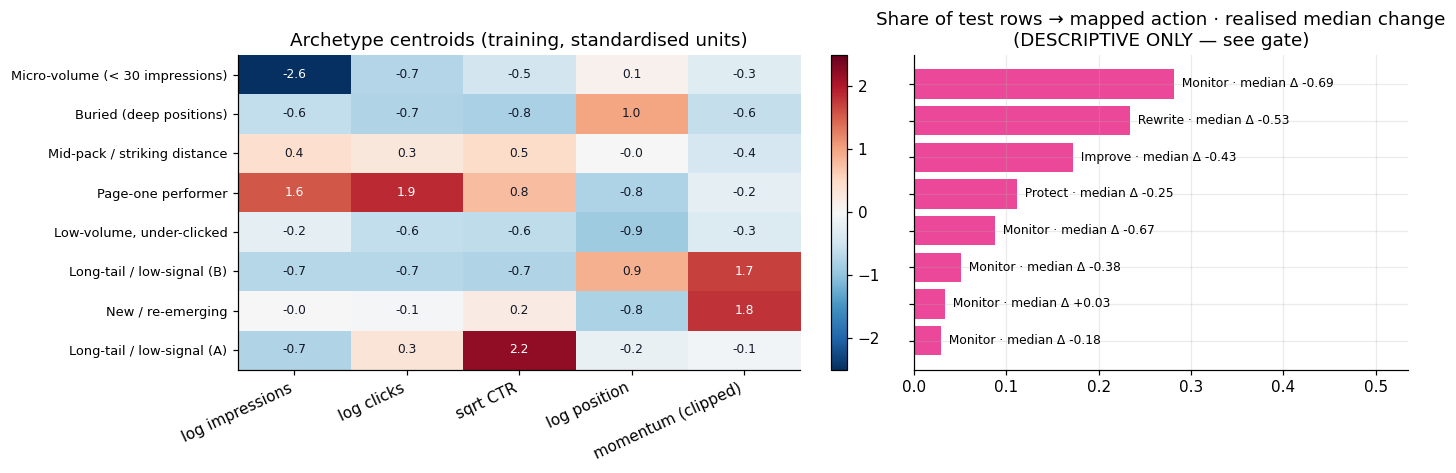

In [ ]:
def eta_squared(y, codes, n_groups):
    n_k = np.bincount(codes, minlength=n_groups).astype(float)
    mean_k = np.bincount(codes, weights=y, minlength=n_groups) / np.maximum(n_k, 1)
    ss_between = float((n_k * (mean_k - y.mean()) ** 2).sum())
    return ss_between / float(((y - y.mean()) ** 2).sum())

y_te, codes_te = XY["test"]["y"], D["test"]["arch_id"].to_numpy()
eta_obs = eta_squared(y_te, codes_te, K + 1)
rs2 = np.random.default_rng(SEED)
null = np.array([eta_squared(y_te, rs2.permutation(codes_te), K + 1) for _ in range(200)])
p_perm = float((1 + (null >= eta_obs).sum()) / (1 + len(null)))

arch_med = D["train"].groupby("arch_id")["y_delta"].median()
pred_arch = arch_med.reindex(codes_te).fillna(med_delta).to_numpy()
d_ap, lo_ap, hi_ap = paired_diff(pred_arch, preds["test"][PERSIST], "test")
d_at, lo_at, hi_at = paired_diff(pred_arch, preds["test"][TREND], "test")
mae_arch = float(np.abs(pred_arch - y_te).mean())

gate = pd.DataFrame([
    {"test": "η² of next-month change explained by archetype (test)", "value": f"{eta_obs:.4f}", "requirement": "≥ 0.02", "pass": eta_obs >= 0.02},
    {"test": "permutation p-value for η² (200 shuffles)", "value": f"{p_perm:.4f}", "requirement": "< 0.01", "pass": p_perm < 0.01},
    {"test": "archetype-median Δ vs persistence (paired ΔMAE)", "value": fmt_ci(d_ap, lo_ap, hi_ap), "requirement": "CI entirely below 0", "pass": verdict(lo_ap, hi_ap) == "better"},
])
display(gate)
print(f"Archetype-median forecast MAE = {mae_arch:.3f}; vs trailing-market baseline: ΔMAE {fmt_ci(d_at, lo_at, hi_at)} ({verdict(lo_at, hi_at)}).")
ARCHETYPES_VALIDATED = bool(gate["pass"].all())
print("\nVALIDATION GATE:", "PASSED — archetypes separate next-month outcomes." if ARCHETYPES_VALIDATED else
      "NOT PASSED — archetypes are DESCRIPTIVE ONLY; the action map is a review heuristic, not a validated policy.")

RESULTS["archetypes"] = {"k": K, "selection": sel_df.to_dict(orient="records"), "caveat": caveat,
                         "profiles_test": prof.to_dict(orient="records"), "test_silhouette": sil_test,
                         "naming_rules": "rule-based on training medians (volume, momentum, position, CTR vs peer expectation)",
                         "validation": {"eta_squared": eta_obs, "permutation_p": p_perm, "archetype_median_mae": mae_arch,
                                        "vs_persistence": {"diff": d_ap, "lo": lo_ap, "hi": hi_ap, "verdict": verdict(lo_ap, hi_ap)},
                                        "vs_trend": {"diff": d_at, "lo": lo_at, "hi": hi_at, "verdict": verdict(lo_at, hi_at)},
                                        "gate": gate.to_dict(orient="records"), "validated": ARCHETYPES_VALIDATED}}

# Figure: standardised centroids (what defines each archetype) + share of rows, mapped action and realised change
cent = pd.DataFrame(Z["train"], columns=CLUSTER_FEATS).groupby(D["train"]["arch_id"].to_numpy()).mean()
cent.index = [names[i] for i in cent.index]
cent = cent.reindex(prof["archetype"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.25, 1]})
im = ax[0].imshow(cent.values, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
ax[0].set_xticks(range(len(CLUSTER_FEATS))); ax[0].set_xticklabels(CLUSTER_FEATS, rotation=25, ha="right")
ax[0].set_yticks(range(len(cent))); ax[0].set_yticklabels(cent.index, fontsize=8.5)
for i_ in range(cent.shape[0]):
    for j_ in range(cent.shape[1]):
        ax[0].text(j_, i_, f"{cent.values[i_, j_]:.1f}", ha="center", va="center", fontsize=8,
                   color="white" if abs(cent.values[i_, j_]) > 1.5 else PALETTE["ink"])
ax[0].set_title("Archetype centroids (training, standardised units)"); ax[0].grid(False)
fig.colorbar(im, ax=ax[0], fraction=0.04)
ax[1].barh(prof["archetype"], prof["share_of_test_rows"], color=PALETTE["accent"])
for i_, r_ in prof.iterrows():
    ax[1].text(r_["share_of_test_rows"], i_, f"  {r_['action']} · median Δ {r_['median_actual_change']:+.2f}", va="center", fontsize=8)
ax[1].set_title("Share of test rows → mapped action · realised median change" + ("" if ARCHETYPES_VALIDATED else "\n(DESCRIPTIVE ONLY — see gate)"))
ax[1].invert_yaxis(); ax[1].set_xlim(0, prof["share_of_test_rows"].max() * 1.9); ax[1].set_yticklabels([])
plt.tight_layout()
savefig("fig09_archetypes")

### 5.3 Research pillar 02 — PCA and archetype radar profiles

The PCA view projects held-out test items into two dimensions using a PCA transformation fitted **only on the training, clusterable population**. The micro-volume bucket is shown for context, but it remains a separate monitoring bucket and was not fitted as a K-means cluster. To keep the figure legible, the scatter uses a capped sample per archetype; the legend reports each archetype's full held-out test count.

The radar small multiples compare each archetype's held-out test medians across the five clustering features. Every spoke uses the same 5th–95th percentile reference range estimated from the training non-micro population. Higher log position means a numerically worse search position. These are descriptive profile plots; the outcome-validation gate in §5.2 still determines whether archetypes may be treated as outcome evidence.


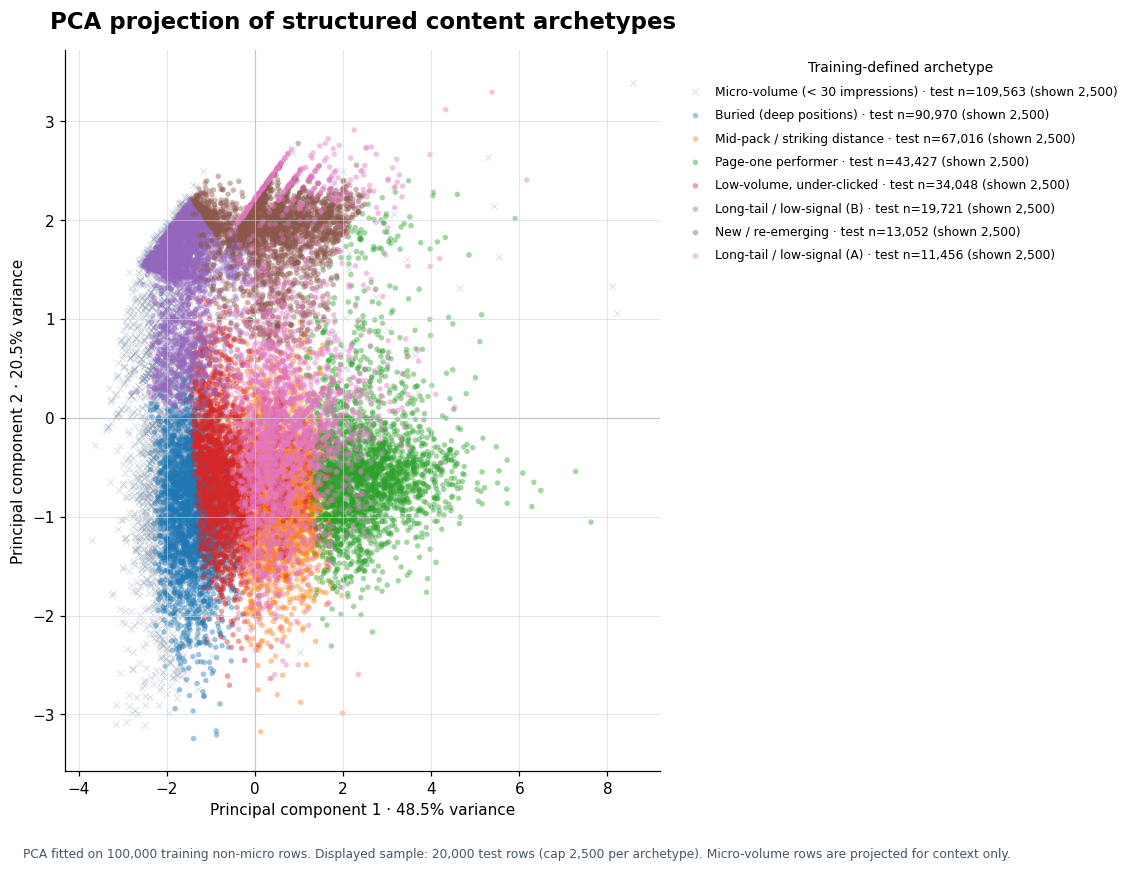

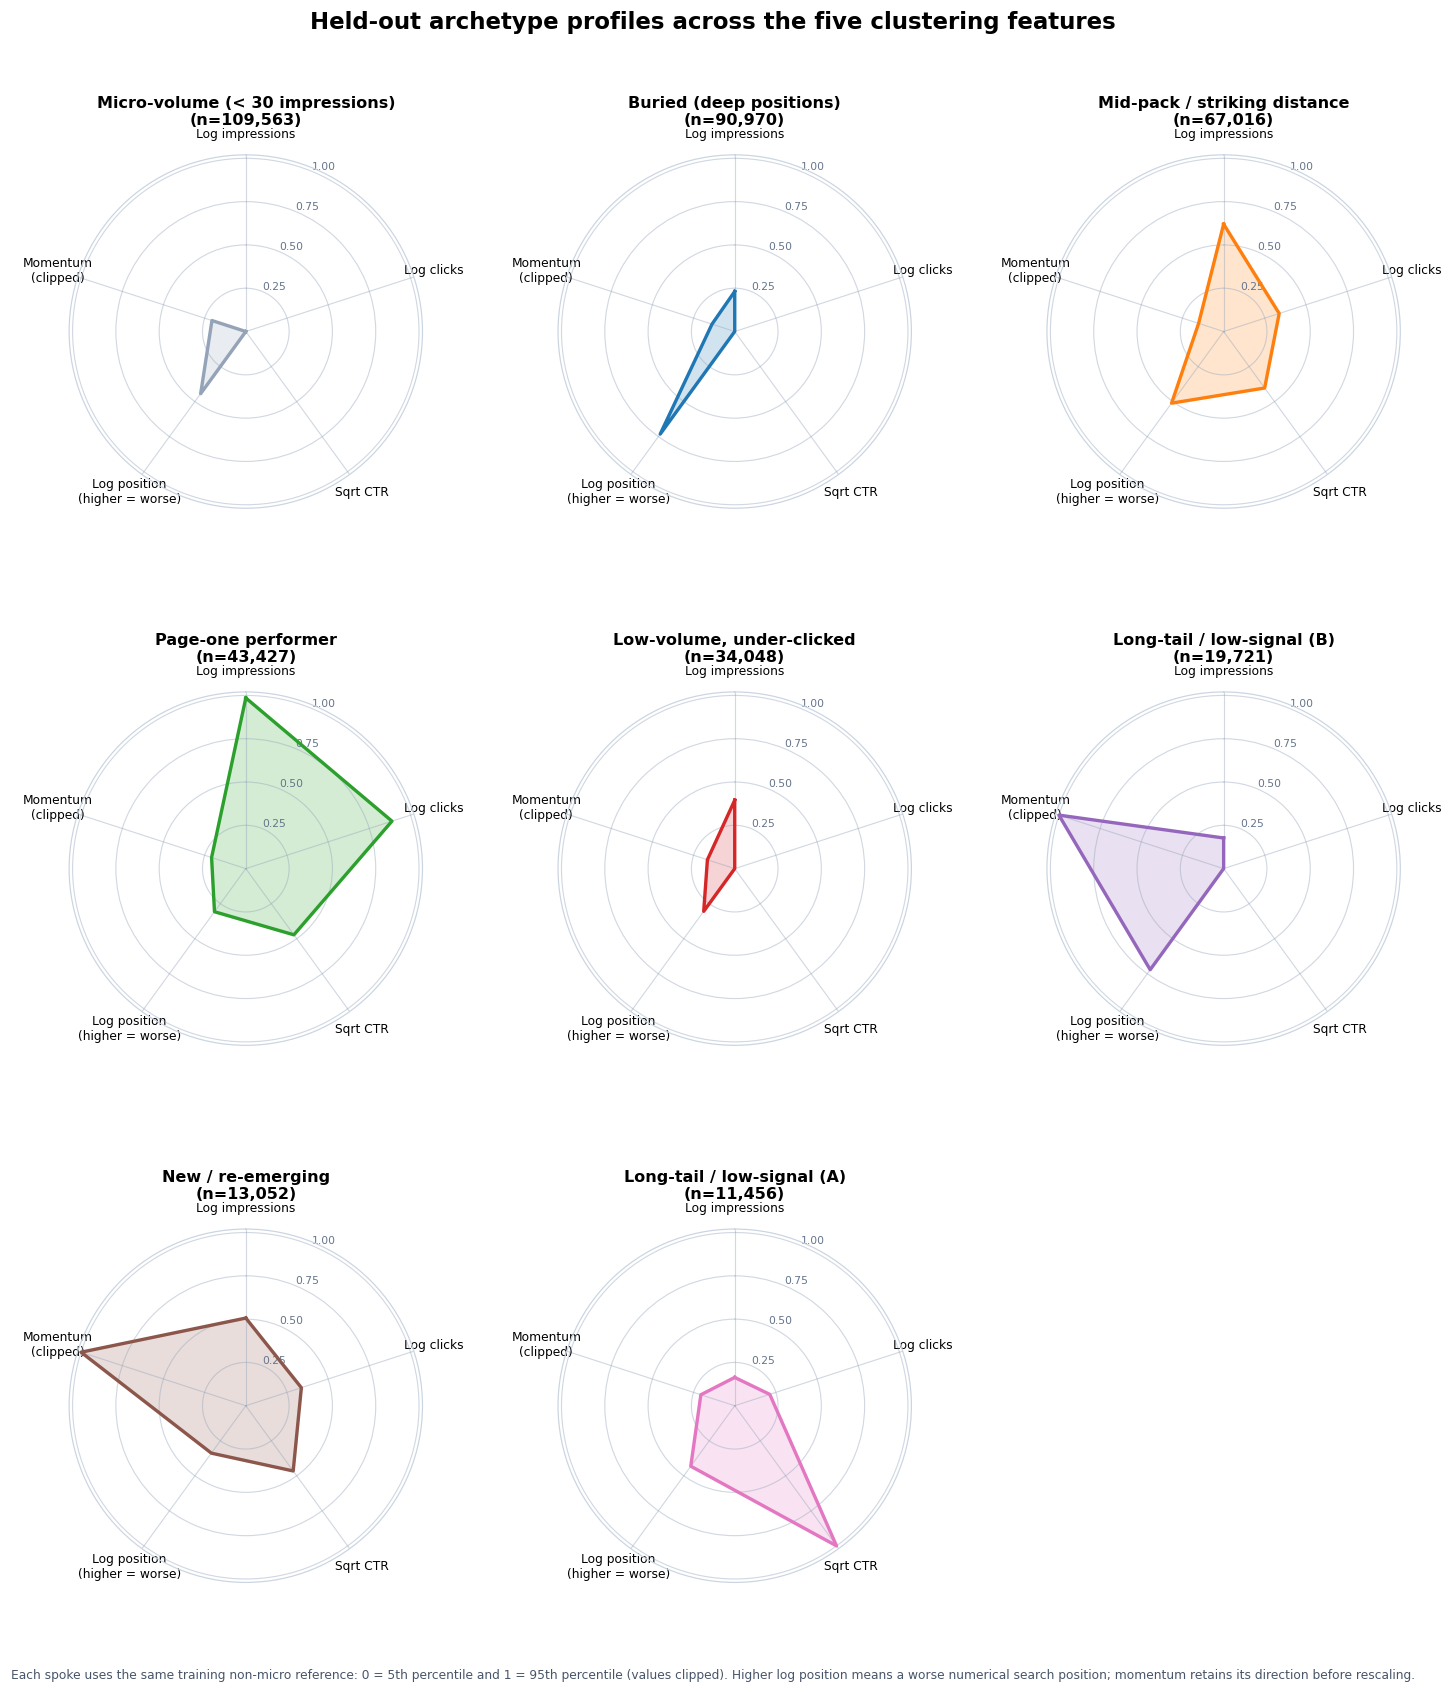

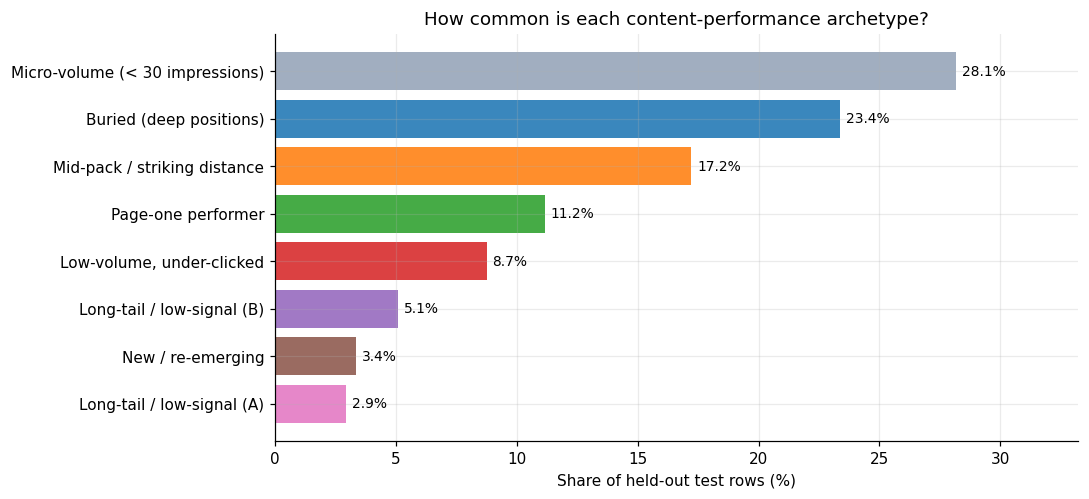

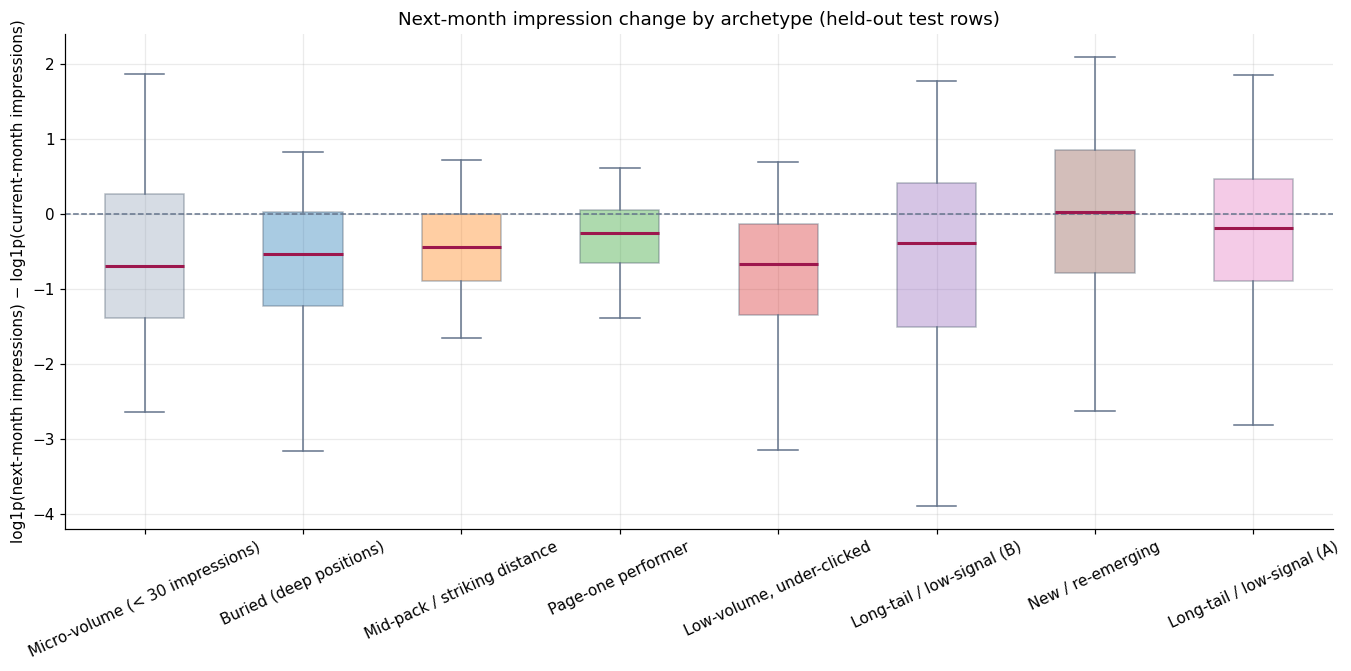

Research pillar 02 visuals saved:
  ✓ /content/docs/figures/fig15_archetype_pca.png
  ✓ /content/docs/figures/fig16_archetype_radar.png
  ✓ /content/docs/figures/fig17_archetype_prevalence.png
  ✓ /content/docs/figures/fig18_archetype_outcomes.png


In [ ]:
# Research pillar 02 — PCA scatter + archetype radar profiles
# All visuals use aggregate feature values; no client/content identifiers are displayed.
from sklearn.decomposition import PCA

FIG_DIR.mkdir(parents=True, exist_ok=True)

# One deterministic color per training-defined archetype. The micro-volume
# bucket is visually neutral because it is not a fitted K-means cluster.
arch_order = list(prof.sort_values("share_of_test_rows", ascending=False)["archetype"])
cluster_palette = list(plt.cm.tab10.colors)
arch_colors = {}
cluster_color_idx = 0
for label in arch_order:
    if label == MICRO_NAME:
        arch_colors[label] = "#94A3B8"
    else:
        arch_colors[label] = cluster_palette[cluster_color_idx % len(cluster_palette)]
        cluster_color_idx += 1

# Figure 15 — PCA scatter of held-out test items.
# Fit PCA on the same training-only, non-micro representation used to fit K-means;
# then project test rows without refitting. Micro-volume items are projected for
# context only and are not treated as members of a fitted cluster.
pca_arch = PCA(n_components=2, random_state=SEED)
pca_arch.fit(Z_tr[idx_fit])

# Cap each archetype at 2,500 displayed test rows to keep dense populations from
# hiding smaller groups. Legend counts still refer to the full test population.
PCA_MAX_PER_ARCHETYPE = 2_500
rng_pca = np.random.default_rng(SEED + 15)
test_archetype_labels = D["test"]["archetype"].astype(str).to_numpy()
plot_parts = []
for label in arch_order:
    members = np.flatnonzero(test_archetype_labels == label)
    if members.size:
        take = min(PCA_MAX_PER_ARCHETYPE, members.size)
        plot_parts.append(rng_pca.choice(members, size=take, replace=False))
plot_idx = np.concatenate(plot_parts) if plot_parts else np.array([], dtype=int)

if len(plot_idx):
    coords = pca_arch.transform(Z["test"][plot_idx])
    labels_plot = test_archetype_labels[plot_idx]

    fig, ax = plt.subplots(figsize=(12.8, 8.0))
    # Draw the micro-volume bucket first so fitted archetype points remain visible.
    for label in [x for x in arch_order if x == MICRO_NAME] + [x for x in arch_order if x != MICRO_NAME]:
        mask = labels_plot == label
        if not mask.any():
            continue
        n_total = int((test_archetype_labels == label).sum())
        n_shown = int(mask.sum())
        is_micro = label == MICRO_NAME
        ax.scatter(
            coords[mask, 0], coords[mask, 1],
            s=18 if is_micro else 13,
            alpha=0.34 if is_micro else 0.43,
            marker="x" if is_micro else "o",
            linewidths=0.65 if is_micro else 0,
            label=f"{label} · test n={n_total:,} (shown {n_shown:,})",
            color=arch_colors[label],
            rasterized=True,
            edgecolors="none" if not is_micro else None,
        )

    ax.axhline(0, color="#64748B", lw=0.75, alpha=0.55, zorder=0)
    ax.axvline(0, color="#64748B", lw=0.75, alpha=0.55, zorder=0)
    ax.grid(True, color="#CBD5E1", lw=0.65, alpha=0.60)
    ax.set_title("PCA projection of structured content archetypes", fontsize=15, weight="bold", pad=14)
    ax.set_xlabel(f"Principal component 1 · {pca_arch.explained_variance_ratio_[0]:.1%} variance")
    ax.set_ylabel(f"Principal component 2 · {pca_arch.explained_variance_ratio_[1]:.1%} variance")
    ax.legend(
        title="Training-defined archetype",
        bbox_to_anchor=(1.02, 1), loc="upper left",
        frameon=False, fontsize=8, title_fontsize=9,
        labelspacing=0.85, handletextpad=0.6,
    )
    fig.text(
        0.02, 0.015,
        f"PCA fitted on {len(idx_fit):,} training non-micro rows. "
        f"Displayed sample: {len(plot_idx):,} test rows (cap {PCA_MAX_PER_ARCHETYPE:,} per archetype). "
        "Micro-volume rows are projected for context only.",
        ha="left", va="bottom", fontsize=8, color="#475569",
    )
    fig.tight_layout(rect=(0, 0.045, 0.82, 1))
    fig.savefig(FIG_DIR / "fig15_archetype_pca.png", dpi=210, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
else:
    print("PCA scatter skipped: no held-out test archetypes were available.")

# Figure 16 — radar small multiples, one panel per archetype.
# Medians come from the held-out test period; the common scale is learned from
# the training non-micro population only (5th–95th percentiles, clipped to 0–1).
radar_feature_labels = [
    "Log impressions", "Log clicks", "Sqrt CTR",
    "Log position\n(higher = worse)", "Momentum\n(clipped)",
]
train_cluster_reference = cluster_matrix(D["train"].loc[fit_tr])
radar_low = np.nanquantile(train_cluster_reference, 0.05, axis=0)
radar_high = np.nanquantile(train_cluster_reference, 0.95, axis=0)
radar_span = np.where((radar_high - radar_low) > 1e-9, radar_high - radar_low, 1.0)

radar_rows = []
for label in arch_order:
    sub = D["test"].loc[D["test"]["archetype"] == label]
    if sub.empty:
        continue
    medians = np.nanmedian(cluster_matrix(sub), axis=0)
    scaled = np.clip((medians - radar_low) / radar_span, 0, 1)
    radar_rows.append({
        "label": label,
        "n": int(len(sub)),
        "values": scaled,
        "color": arch_colors[label],
    })

if radar_rows:
    ncols = min(3, len(radar_rows))
    nrows = int(np.ceil(len(radar_rows) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(5.25 * ncols, 5.15 * nrows),
        subplot_kw={"projection": "polar"},
        squeeze=False,
    )
    angles = np.linspace(0, 2 * np.pi, len(radar_feature_labels), endpoint=False)
    closed_angles = np.r_[angles, angles[0]]

    for ax in axes.flat:
        ax.set_visible(False)

    for ax, item in zip(axes.flat, radar_rows):
        ax.set_visible(True)
        values = np.asarray(item["values"], dtype=float)
        closed_values = np.r_[values, values[0]]
        ax.plot(closed_angles, closed_values, color=item["color"], linewidth=2.2)
        ax.fill(closed_angles, closed_values, color=item["color"], alpha=0.20)
        ax.set_theta_offset(np.pi / 2)
        ax.set_theta_direction(-1)
        ax.set_xticks(angles)
        ax.set_xticklabels(radar_feature_labels, fontsize=8)
        ax.set_ylim(0, 1.02)
        ax.set_yticks([0.25, 0.50, 0.75, 1.00])
        ax.set_yticklabels(["0.25", "0.50", "0.75", "1.00"], fontsize=7, color="#64748B")
        ax.grid(color="#94A3B8", alpha=0.42, linewidth=0.75)
        ax.spines["polar"].set_color("#CBD5E1")
        ax.spines["polar"].set_linewidth(0.8)
        ax.set_title(f"{item['label']}\n(n={item['n']:,})", fontsize=10.5, fontweight="bold", pad=20)

    fig.suptitle(
        "Held-out archetype profiles across the five clustering features",
        fontsize=15, fontweight="bold", y=0.995,
    )
    fig.text(
        0.5, 0.012,
        "Each spoke uses the same training non-micro reference: 0 = 5th percentile and 1 = 95th percentile (values clipped). "
        "Higher log position means a worse numerical search position; momentum retains its direction before rescaling.",
        ha="center", va="bottom", fontsize=8, color="#475569", wrap=True,
    )
    fig.subplots_adjust(hspace=0.52, wspace=0.34, top=0.91, bottom=0.07)
    fig.savefig(FIG_DIR / "fig16_archetype_radar.png", dpi=210, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
else:
    print("Radar profiles skipped: no non-empty held-out test archetypes were available.")

# Figure 17 — archetype prevalence in the held-out test population.
arch_share = (
    D["test"]["archetype"].value_counts(normalize=True)
    .reindex(arch_order).dropna().sort_values()
)
fig, ax = plt.subplots(figsize=(10, max(4.5, 0.58 * len(arch_share))))
bar_colors = [arch_colors[label] for label in arch_share.index]
ax.barh(arch_share.index, arch_share.values * 100, color=bar_colors, alpha=0.88)
for y, value in enumerate(arch_share.values * 100):
    ax.text(value + 0.25, y, f"{value:.1f}%", va="center", fontsize=9)
ax.set(xlabel="Share of held-out test rows (%)", title="How common is each content-performance archetype?")
ax.set_xlim(0, max(arch_share.values * 100) * 1.18 if len(arch_share) else 1)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig17_archetype_prevalence.png", dpi=190, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

# Figure 18 — realized next-month change distribution by archetype.
# This is descriptive and does not establish a causal effect of archetype membership.
box_data, box_labels = [], []
for label in arch_order:
    values = D["test"].loc[D["test"]["archetype"] == label, "y_delta"].dropna().to_numpy()
    if len(values):
        box_data.append(values)
        box_labels.append(label)
if box_data:
    fig, ax = plt.subplots(figsize=(12.5, 6.2))
    bp = ax.boxplot(
        box_data, tick_labels=box_labels, showfliers=False, whis=(5, 95), patch_artist=True,
        medianprops={"color": "#9D174D", "linewidth": 2},
        whiskerprops={"color": "#64748B"}, capprops={"color": "#64748B"},
    )
    for patch, label in zip(bp["boxes"], box_labels):
        patch.set_facecolor(arch_colors[label])
        patch.set_alpha(0.38)
        patch.set_edgecolor("#475569")
    ax.axhline(0, color="#64748B", linestyle="--", linewidth=1)
    ax.set(
        title="Next-month impression change by archetype (held-out test rows)",
        ylabel="log1p(next-month impressions) − log1p(current-month impressions)",
    )
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "fig18_archetype_outcomes.png", dpi=190, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
else:
    print("Outcome distribution skipped: no non-empty held-out test labels were available.")

RESULTS.setdefault("archetypes", {})["visuals"] = [
    "fig15_archetype_pca.png", "fig16_archetype_radar.png",
    "fig17_archetype_prevalence.png", "fig18_archetype_outcomes.png",
]
RESULTS["archetypes"]["visual_details"] = {
    "pca_fit_rows": int(len(idx_fit)),
    "pca_test_rows_displayed": int(len(plot_idx)),
    "pca_max_per_archetype": int(PCA_MAX_PER_ARCHETYPE),
    "pca_explained_variance_pc1": float(pca_arch.explained_variance_ratio_[0]),
    "pca_explained_variance_pc2": float(pca_arch.explained_variance_ratio_[1]),
    "radar_reference": "training non-micro population; 5th–95th percentile per feature; clipped to [0, 1]",
}
print("Research pillar 02 visuals saved:")
for filename in RESULTS["archetypes"]["visuals"]:
    path = FIG_DIR / filename
    print(f"  {'✓' if path.exists() else '⚠'} {path}")


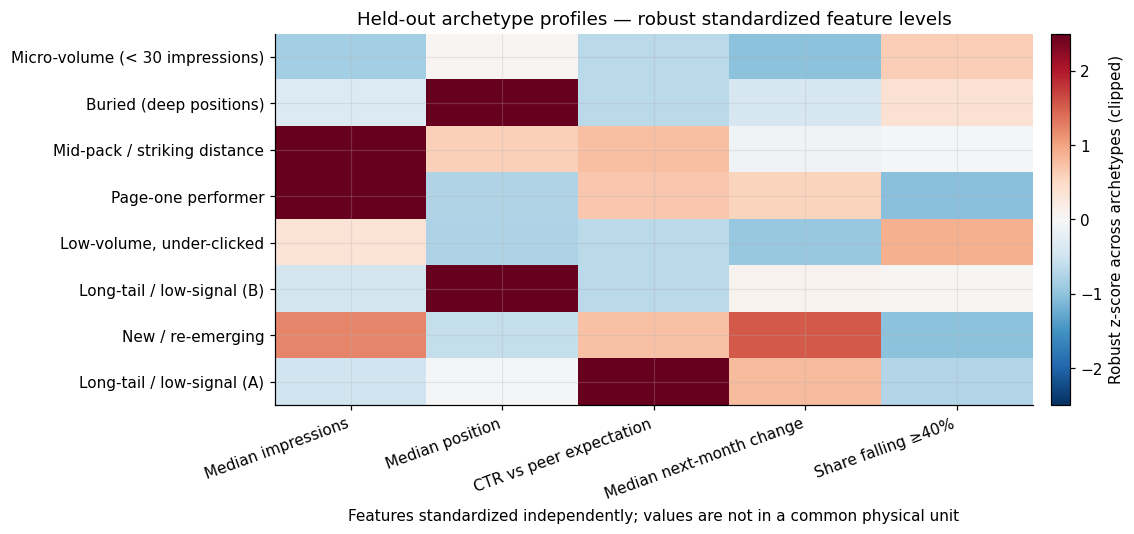

In [ ]:

# Figure 21 — robust-standardized archetype profile heatmap.
# Primary comparison view; radar profiles remain supplementary.
heat_cols = [("median_impressions","Median impressions"),("median_position","Median position"),
             ("median_ctr_vs_peers","CTR vs peer expectation"),("median_actual_change","Median next-month change"),
             ("share_fell_40pct","Share falling ≥40%")]
available = [(c,label) for c,label in heat_cols if c in prof.columns]
if available and len(prof):
    H = prof.set_index("archetype")[[c for c,_ in available]].astype(float)
    HZ = H.copy()
    for c in HZ.columns:
        med = HZ[c].median()
        mad = (HZ[c]-med).abs().median()
        scale = 1.4826*mad if mad > 1e-9 else (HZ[c].std() if HZ[c].std() > 1e-9 else 1.0)
        HZ[c] = ((HZ[c]-med)/scale).clip(-2.5,2.5)
    fig, ax = plt.subplots(figsize=(11,max(4.5,.62*len(HZ))))
    im=ax.imshow(HZ.to_numpy(),aspect="auto",cmap="RdBu_r",vmin=-2.5,vmax=2.5)
    ax.set_yticks(np.arange(len(HZ))); ax.set_yticklabels(HZ.index)
    ax.set_xticks(np.arange(len(available))); ax.set_xticklabels([label for _,label in available],rotation=20,ha="right")
    ax.set_title("Held-out archetype profiles — robust standardized feature levels")
    cb=fig.colorbar(im,ax=ax,pad=.02); cb.set_label("Robust z-score across archetypes (clipped)")
    ax.set_xlabel("Features standardized independently; values are not in a common physical unit")
    fig.tight_layout()
    fig.savefig(FIG_DIR/"fig21_archetype_profile_heatmap.png",dpi=190,bbox_inches="tight",facecolor="white")
    plt.show(); plt.close(fig)
else:
    print("Heatmap skipped: expected archetype profile columns are unavailable.")


## 6. Ranked recommendations — per-client review queues

### 6.1 Scoring design

The score is in **estimated clicks per month at stake**, so volume is preserved (a rank-percentile blend discards magnitude and cannot beat "sort by impressions"). Every term uses only information available at the end of month *t*.

| Quantity | Definition |
|---|---|
| Peer-expected CTR | CTR of the **same client's other items** at the same position bucket in the same month, shrunk to the pooled prior (§2.6) |
| CTR gap | `max(peer-expected CTR − CTR, 0)` |
| **Predicted missed clicks** | `CTR gap × predicted next-month impressions` |
| **Decline exposure** | `max(impressions − predicted next-month impressions, 0) × peer-expected CTR` |
| **At-stake clicks** | `predicted missed clicks + λ × decline exposure`, λ = 1 |
| Position headroom | 0 for positions ≤ 3; 0.8 for 4–10; **1.0 for 11–20** (striking distance); 0.5 for 21–30; 0.2 for 31–50; 0 beyond |
| **Score** | `at-stake clicks × (1 + β × headroom)`, β = 0.5 |

λ and β are judgement calls, stress-tested in §6.5. These are **screening estimates**, not forecasts of clicks gained from any action. The peer benchmark makes "under-capture" a statement *within* a client ("fewer clicks than this site's other pages at the same rank"), not against a universal CTR curve.

**Per-client queues are the primary output.** A content team works one client's inventory, so tiers are fixed shares of *each client's* items each month: top 5% *Immediate review*, next 15% *High priority*, next 30% *Review*, the rest *Monitor*. A global rank (`priority_rank`, `global_tier`) is kept only to compare across clients — and §6.4 shows how concentrated it is.

**Reason codes** are multi-valued flags and are kept **selective**: change codes need at least `MIN_IMPR_CODES` impressions (a ±50% move on 3 impressions is counting noise), and `LOW_CTR_FOR_POSITION` needs at least `MIN_EXPECTED_CLICKS` *expected* clicks so a CTR gap can exceed Poisson noise. Predicted-change codes are *relative* (bottom / top decile of the preceding period's out-of-time predictions) and are paired with **observed** counterparts (`OBSERVED_DECLINE` / `OBSERVED_GROWTH`: a month-over-month log change beyond ±0.5, about −39% / +65%). The share of items each code flags is printed, and codes flagging more than 35% of items are called out as non-selective.

**Evidence-gated routing (rolling, not one-window).** A *predicted* decline or growth code may drive the primary action only if it (i) identified the realized change at ≥ 1.15× the unflagged rate on the pooled validation months, (ii) did so (lift > 1.05) in at least two thirds of the months that count (a month counts only when ≥ `GATE_MIN_FLAGGED` items were flagged — a lift computed from a handful of items is noise), **and** (iii) had lift > 1 in the *most recent* counted month, the regime closest to the test period. A one-window gate can pass on a regime that then reverses. Otherwise the action is routed on the observed counterpart. The backtest uses the validation-only gate; for the **live** queue the same rule is re-applied to the last three labeled months (validation + test), all of which are out-of-time.

In [ ]:
from functools import reduce

LAMBDA, BETA = 1.0, 0.5
ACTIONS = ["Refresh review (decline risk)", "Metadata / snippet review", "Content improvement review (page-1 push)",
           "Rewrite / re-target review", "Protect & amplify (monitor growth)", "Monitor"]
TIERS = ["Monitor", "Review", "High priority", "Immediate review"]
TIER_BINS = [0, 0.5, 0.8, 0.95, 1.0]


def position_headroom(pos):
    pos = np.asarray(pos, float)
    return np.select([pos <= 3, pos <= 10, pos <= 20, pos <= 30, pos <= 50], [0.0, 0.8, 1.0, 0.5, 0.2], default=0.0)


def make_context(df_ref, ref_pred, route_pred_decline=True, route_pred_growth=True):
    """Volume thresholds from df_ref; relative prediction thresholds from out-of-time predictions; routing switches."""
    ref_pred = np.asarray(ref_pred, float)
    return {"impr_p50": float(df_ref["impressions"].quantile(.50)), "impr_p75": float(df_ref["impressions"].quantile(.75)),
            "impr_p90": float(df_ref["impressions"].quantile(.90)),
            "pd_lo": float(np.quantile(ref_pred, 0.10)), "pd_hi": float(np.quantile(ref_pred, 0.90)),
            "pd_rebound": float(np.quantile(ref_pred, 0.75)),
            "route_pred_decline": bool(route_pred_decline), "route_pred_growth": bool(route_pred_growth)}


def score_queue(df, pred_delta, ctx, lam=LAMBDA, beta=BETA):
    """Score rows of `df` (must contain expected_ctr). Output rows are in the SAME ORDER as `df`."""
    keep = ID_COLS + ["month", "impressions", "clicks", "ctr", "avg_position", "mom_change", "log_impr", "expected_ctr"]
    q = df[keep + (["archetype"] if "archetype" in df.columns else [])].copy().reset_index(drop=True)
    q["month"] = q["month"].astype(str)
    q["pred_delta"] = np.asarray(pred_delta, float)
    q["pred_next_impr"] = np.expm1(q["log_impr"] + q["pred_delta"]).clip(lower=0)
    gap = np.maximum(q["expected_ctr"] - q["ctr"], 0)
    q["missed_clicks_est"] = gap * q["impressions"]
    q["pred_missed_clicks"] = gap * q["pred_next_impr"]
    q["decline_exposure"] = np.maximum(q["impressions"] - q["pred_next_impr"], 0) * q["expected_ctr"]
    q["at_stake_clicks"] = q["pred_missed_clicks"] + lam * q["decline_exposure"]
    q["headroom"] = position_headroom(q["avg_position"])
    q["score"] = q["at_stake_clicks"] * (1 + beta * q["headroom"])

    pos, impr, pdl, mom = q["avg_position"].to_numpy(), q["impressions"].to_numpy(), q["pred_delta"].to_numpy(), q["mom_change"].to_numpy()
    ratio = np.where(q["expected_ctr"] > 0, q["ctr"] / np.where(q["expected_ctr"] > 0, q["expected_ctr"], 1.0), np.nan)
    exp_clicks = q["expected_ctr"].to_numpy() * impr
    vol = impr >= MIN_IMPR_CODES
    flags = {"LOW_CTR_FOR_POSITION": (((ratio < 0.5) & (impr >= ctx["impr_p50"])) | ((ratio < 0.8) & (impr >= ctx["impr_p90"]))) & (exp_clicks >= MIN_EXPECTED_CLICKS),
             "STRIKING_DISTANCE": (pos > 3) & (pos <= 20),
             "BURIED_BUT_VISIBLE": (pos > 20) & (impr >= ctx["impr_p75"]),
             "OBSERVED_DECLINE": (mom <= -OBS_CHANGE) & vol, "OBSERVED_GROWTH": (mom >= OBS_CHANGE) & vol,
             "PREDICTED_DECLINE": (pdl <= ctx["pd_lo"]) & (pdl < 0) & vol, "PREDICTED_GROWTH": (pdl >= ctx["pd_hi"]) & (pdl > 0) & vol,
             "RECOVERY_SIGNAL": (mom <= -0.25) & (pdl >= ctx["pd_rebound"]) & vol,
             "HIGH_VISIBILITY": impr >= ctx["impr_p90"]}
    joined = reduce(np.char.add, [np.where(f, code + ";", "") for code, f in flags.items()])
    q["reason_codes"] = pd.Series(joined).str.rstrip(";").replace("", "NONE").to_numpy()

    decline = flags["OBSERVED_DECLINE"] | (flags["PREDICTED_DECLINE"] if ctx["route_pred_decline"] else False)
    growth = flags["OBSERVED_GROWTH"] | (flags["PREDICTED_GROWTH"] if ctx["route_pred_growth"] else False)
    q["recommended_action"] = np.select(
        [decline & (impr >= ctx["impr_p75"]), flags["LOW_CTR_FOR_POSITION"], flags["STRIKING_DISTANCE"],
         flags["BURIED_BUT_VISIBLE"], growth], ACTIONS[:5], default=ACTIONS[5])

    grp = q.groupby(["month", "client_hash_id"])["score"]
    q["tier"] = pd.cut(grp.rank(pct=True, method="first"), bins=TIER_BINS, labels=TIERS, include_lowest=True)          # per client (primary)
    q["priority_rank_in_client"] = grp.rank(ascending=False, method="first").astype(int)
    q["global_tier"] = pd.cut(q.groupby("month")["score"].rank(pct=True, method="first"), bins=TIER_BINS, labels=TIERS, include_lowest=True)
    q["priority_rank"] = q.groupby("month")["score"].rank(ascending=False, method="first").astype(int)
    return q


def code_validation(q, d):
    """For each reason code: realised next-month outcome among flagged items vs. unflagged items (rows of q and d aligned)."""
    y = d["y_delta"].to_numpy(float)
    fell, grew = y <= np.log(0.6), y >= np.log(1.25)
    n_imp, n_clk = d["next_impressions"].to_numpy(float), d["next_clicks"].to_numpy(float)
    still_low = (n_imp > 0) & (n_clk < 0.5 * q["expected_ctr"].to_numpy() * n_imp)
    spec = {"PREDICTED_DECLINE": ("impressions fell ≥ 40% next month", fell, np.ones(len(y), bool)),
            "OBSERVED_DECLINE": ("impressions fell ≥ 40% next month", fell, np.ones(len(y), bool)),
            "PREDICTED_GROWTH": ("impressions grew ≥ 25% next month", grew, np.ones(len(y), bool)),
            "OBSERVED_GROWTH": ("impressions grew ≥ 25% next month", grew, np.ones(len(y), bool)),
            "RECOVERY_SIGNAL": ("impressions grew ≥ 25% next month", grew, np.ones(len(y), bool)),
            "LOW_CTR_FOR_POSITION": ("CTR still < 0.5× peer expectation next month", still_low, n_imp > 0)}
    rows = []
    for code, (what, outcome, universe) in spec.items():
        fl = q["reason_codes"].str.contains(code).to_numpy() & universe
        un = ~q["reason_codes"].str.contains(code).to_numpy() & universe
        r_f, r_u = (float(outcome[fl].mean()) if fl.any() else np.nan), float(outcome[un].mean())
        rows.append({"reason_code": code, "items_flagged": int(fl.sum()), "share_flagged": float(fl.mean()), "outcome": what,
                     "rate_flagged": r_f, "rate_unflagged": r_u, "lift": r_f / r_u if r_u > 0 else np.nan})
    return pd.DataFrame(rows)


def code_validation_by_month(q, d):
    """Per-month lift of every reason code (q and d are row-aligned)."""
    parts = []
    months = q["month"].astype(str).to_numpy()
    for m in sorted(set(months)):
        mk = months == m
        cv_m = code_validation(q[mk].reset_index(drop=True), d[mk].reset_index(drop=True))
        parts.append(cv_m.assign(month=m))
    return pd.concat(parts, ignore_index=True)


def routing_gate(cv_pooled, cv_month, code):
    """Rolling evidence gate. Only months with >= GATE_MIN_FLAGGED flagged items count. Passes when the pooled lift >= GATE_MIN_LIFT,
    the lift exceeds 1.05 in at least two thirds of the counted months (and at least two), and the latest counted month's lift exceeds 1."""
    sub = cv_month[(cv_month["reason_code"] == code) & (cv_month["items_flagged"] >= GATE_MIN_FLAGGED)].sort_values("month")
    lifts = sub["lift"].to_numpy(float)
    pooled = float(cv_pooled.set_index("reason_code")["lift"].get(code, np.nan))
    need = max(2, int(np.ceil(2 * len(lifts) / 3)))
    n_ok = int((lifts > 1.05).sum())
    last = float(lifts[-1]) if len(lifts) else float("nan")
    passed = bool(len(lifts) >= 2 and pooled >= GATE_MIN_LIFT and last > 1.0 and n_ok >= need)
    return passed, {"pooled_lift": pooled, "monthly_lifts": [float(x) for x in lifts], "months_counted": int(len(lifts)),
                    "last_month_lift": last, "months_above_1.05": n_ok, "needed": need}


# ---- validation-period backtest decides the routing (label-free thresholds; outcomes only used to evaluate the codes)
CTX_VAL = make_context(D["train"], preds["validation"][SELECTED])
Q_VAL = score_queue(D["validation"], preds["validation"][SELECTED], CTX_VAL)
cv_val = code_validation(Q_VAL, D["validation"])
cv_val_m = code_validation_by_month(Q_VAL, D["validation"])
ROUTE_DECLINE, gate_dec = routing_gate(cv_val, cv_val_m, "PREDICTED_DECLINE")
ROUTE_GROWTH, gate_gro = routing_gate(cv_val, cv_val_m, "PREDICTED_GROWTH")
display(cv_val)
broad = cv_val.loc[cv_val["share_flagged"] > 0.35, "reason_code"].tolist()
print("Selectivity: " + ", ".join(f"{r.reason_code} {r.share_flagged:.0%}" for r in cv_val.itertuples())
      + (f"   ⚠ non-selective (>35% of items): {broad}" if broad else "   → all codes selective (≤ 35% of items)."))
for tag, ok, g in (("PREDICTED_DECLINE", ROUTE_DECLINE, gate_dec), ("PREDICTED_GROWTH", ROUTE_GROWTH, gate_gro)):
    print(f"Rolling gate (validation months) — {tag}: pooled lift {g['pooled_lift']:.2f}×; monthly lifts "
          f"{[round(x, 2) for x in g['monthly_lifts']]} ({g['months_counted']} month(s) with ≥ {GATE_MIN_FLAGGED} flagged items); latest {g['last_month_lift']:.2f}×; "
          f"months > 1.05: {g['months_above_1.05']}/{g['months_counted']} (need {g['needed']}) → "
          f"{'ROUTES actions' if ok else 'flag only; actions use the OBSERVED counterpart (or too little evidence)'}.")

# ---- backtest queue on the held-out test months (model, prior and thresholds from earlier periods only)
CTX_BT = make_context(D["train"], preds["validation"][SELECTED], ROUTE_DECLINE, ROUTE_GROWTH)
dq = D["test"].reset_index(drop=True)
Q_BT = score_queue(dq, preds["test"][SELECTED], CTX_BT)
assert len(Q_BT) == len(dq) and (Q_BT["client_hash_id"].to_numpy() == dq["client_hash_id"].to_numpy()).all()
action_counts = Q_BT["recommended_action"].value_counts()
dead = [a for a in ACTIONS if action_counts.get(a, 0) == 0]
print("\nPrimary-action counts (backtest):"); display(action_counts.rename("items").to_frame())
print("Unreachable (dead) action branches:", dead if dead else "none")
RESULTS["queue"] = {"lambda": LAMBDA, "beta": BETA, "dead_action_branches": dead, "action_counts_backtest": action_counts.to_dict(),
                    "prediction_thresholds": {k: CTX_BT[k] for k in ("pd_lo", "pd_rebound", "pd_hi")},
                    "route_pred_decline": ROUTE_DECLINE, "route_pred_growth": ROUTE_GROWTH,
                    "gate_validation": {"PREDICTED_DECLINE": gate_dec, "PREDICTED_GROWTH": gate_gro},
                    "non_selective_codes": broad, "code_share_flagged": dict(zip(cv_val["reason_code"], cv_val["share_flagged"])),
                    "code_validation_validation": cv_val.to_dict(orient="records")}

,reason_code,items_flagged,share_flagged,outcome,rate_flagged,rate_unflagged,lift
0,PREDICTED_DECLINE,28091,0.0697,impressions fell ≥ 40% next month,0.2908,0.2814,1.0334
1,OBSERVED_DECLINE,12531,0.0311,impressions fell ≥ 40% next month,0.2478,0.2832,0.8751
2,PREDICTED_GROWTH,21664,0.0538,impressions grew ≥ 25% next month,0.6332,0.3562,1.7776
3,OBSERVED_GROWTH,89636,0.2226,impressions grew ≥ 25% next month,0.4042,0.3616,1.1179
4,RECOVERY_SIGNAL,2722,0.0068,impressions grew ≥ 25% next month,0.3971,0.3709,1.0707
5,LOW_CTR_FOR_POSITION,35672,0.0886,CTR still < 0.5× peer expectation next month,0.6575,0.7026,0.9359


Selectivity: PREDICTED_DECLINE 7%, OBSERVED_DECLINE 3%, PREDICTED_GROWTH 5%, OBSERVED_GROWTH 22%, RECOVERY_SIGNAL 1%, LOW_CTR_FOR_POSITION 9%   → all codes selective (≤ 35% of items).
Rolling gate (validation months) — PREDICTED_DECLINE: pooled lift 1.03×; monthly lifts [1.32, 0.49, 0.82] (3 month(s) with ≥ 200 flagged items); latest 0.82×; months > 1.05: 1/3 (need 2) → flag only; actions use the OBSERVED counterpart (or too little evidence).
Rolling gate (validation months) — PREDICTED_GROWTH: pooled lift 1.78×; monthly lifts [1.76, 1.52, 2.24] (3 month(s) with ≥ 200 flagged items); latest 2.24×; months > 1.05: 3/3 (need 2) → ROUTES actions.

Primary-action counts (backtest):


,items
recommended_action,
Content improvement review (page-1 push),205823
Monitor,108569
Refresh review (decline risk),23562
Metadata / snippet review,21338
Rewrite / re-target review,17935
Protect & amplify (monitor growth),12026


Unreachable (dead) action branches: none


### 6.2 Reason codes: do they identify what they claim?

On the held-out test months each code is checked against what *actually* happened next month: flagged vs. unflagged items, and the lift. A code with lift ≈ 1 is a **label**, not evidence.

In [ ]:
cv_test = code_validation(Q_BT, dq)
display(cv_test)
RESULTS["queue"]["code_validation_test"] = cv_test.to_dict(orient="records")

,reason_code,items_flagged,share_flagged,outcome,rate_flagged,rate_unflagged,lift
0,PREDICTED_DECLINE,56571,0.1453,impressions fell ≥ 40% next month,0.4406,0.4857,0.9072
1,OBSERVED_DECLINE,51611,0.1326,impressions fell ≥ 40% next month,0.4959,0.4766,1.0405
2,PREDICTED_GROWTH,15960,0.0410,impressions grew ≥ 25% next month,0.5279,0.1948,2.7105
3,OBSERVED_GROWTH,50865,0.1307,impressions grew ≥ 25% next month,0.2657,0.1998,1.3301
4,RECOVERY_SIGNAL,4886,0.0126,impressions grew ≥ 25% next month,0.1660,0.2090,0.7944
5,LOW_CTR_FOR_POSITION,25468,0.0654,CTR still < 0.5× peer expectation next month,0.4416,0.6683,0.6608


### 6.3 Backtest: does the queue concentrate what happened *next* — and does the model add anything?

On the held-out test months, items are ranked at month *t* and judged on **realized month *t+1*** quantities the score never saw. Realized outcomes use the *same* peer expectation fixed at month *t* (so no information from *t+1* enters the benchmark):

* **Realized at-stake clicks** (primary): `max(expected CTR × impressions_{t+1} − clicks_{t+1}, 0) + λ × max(impressions_t − impressions_{t+1}, 0) × expected CTR`.
* **Realized decline exposure** alone, **realized missed clicks** alone, and **realized clicks** (volume context).

**Fair controls.** The model's value cannot be judged against a rule that lacks the score's decline term, so the *same* score is also computed with (i) **no model** (predicted change = 0, i.e. persistence), (ii) a **market-trend-only** forecast (every item moves by last month's median change), and (iii) the **other** model's predictions. Control (i) is the *easy* test — persistence predicts no decline at all, so it forfeits a whole component of the score whenever the market is moving; control (ii) is the *decisive* one: it asks whether **item-level** predictions add anything to a market-wide trend. Naive triage rules (sort by impressions, by clicks, by worst position — the logic of the first iteration) complete the field.

Metrics: **capture@10%** — the share of the realized outcome inside the top 10% of each month's *global* ranking (0.10 = random) — plus the **per-client macro capture** (the same statistic computed inside each client-month's own top 10%, averaged over client-months with ≥ 100 items), which is what a client team experiences. Intervals are client-clustered; differences are paired. The table reports whatever the data say — including orderings that beat the score.

,ordering,next_at_stake capture@10% [95% CI],next_at_stake lift×,next_decline_exposure capture@10% [95% CI],next_decline_exposure lift×,next_missed_clicks capture@10% [95% CI],next_missed_clicks lift×,next_clicks capture@10% [95% CI],next_clicks lift×,per-client macro capture@10% (at-stake)
0,Opportunity score,"0.750 [0.675, 0.795]",7.5045,"0.724 [0.636, 0.776]",7.2426,"0.781 [0.709, 0.821]",7.8124,"0.530 [0.370, 0.629]",5.3010,0.6329
1,Score using Random Forest predictions,"0.762 [0.678, 0.813]",7.6176,"0.740 [0.637, 0.799]",7.3970,"0.788 [0.708, 0.834]",7.8769,"0.577 [0.405, 0.683]",5.7730,0.6386
2,"Score, no model (persistence: Δ = 0)","0.676 [0.646, 0.693]",6.7563,"0.602 [0.579, 0.619]",6.0231,"0.762 [0.718, 0.788]",7.6181,"0.261 [0.242, 0.274]",2.6130,0.6010
3,"Score, market trend only (no item model)","0.786 [0.733, 0.814]",7.8629,"0.771 [0.715, 0.806]",7.7062,"0.805 [0.749, 0.834]",8.0471,"0.650 [0.587, 0.699]",6.4972,0.6625
4,Predicted missed clicks only,"0.673 [0.646, 0.693]",6.7251,"0.596 [0.573, 0.620]",5.9642,"0.762 [0.723, 0.790]",7.6195,"0.261 [0.248, 0.269]",2.6081,0.5990
5,Naive: current impressions,"0.751 [0.676, 0.791]",7.5089,"0.750 [0.682, 0.784]",7.4955,"0.752 [0.661, 0.803]",7.5247,"0.699 [0.620, 0.752]",6.9934,0.6363
6,Naive: current clicks,"0.650 [0.575, 0.693]",6.4972,"0.649 [0.578, 0.689]",6.4942,"0.650 [0.562, 0.707]",6.5008,"0.780 [0.734, 0.812]",7.7966,0.4720
7,Naive: worst position first (earlier logic),"0.004 [0.002, 0.006]",0.0392,"0.004 [0.002, 0.007]",0.0381,"0.004 [0.003, 0.007]",0.0406,"0.004 [0.002, 0.007]",0.0371,0.0242


,ordering,next_at_stake: verdict (score vs this),next_decline_exposure: verdict (score vs this),next_missed_clicks: verdict (score vs this),next_clicks: verdict (score vs this)
0,Opportunity score,NaN,NaN,NaN,NaN
1,Score using Random Forest predictions,indistinguishable,indistinguishable,indistinguishable,score worse
2,"Score, no model (persistence: Δ = 0)",score better,score better,indistinguishable,score better
3,"Score, market trend only (no item model)",score worse,score worse,score worse,score worse
4,Predicted missed clicks only,score better,score better,indistinguishable,score better
5,Naive: current impressions,indistinguishable,indistinguishable,indistinguishable,score worse
6,Naive: current clicks,score better,score better,score better,score worse
7,Naive: worst position first (earlier logic),score better,score better,score better,score better


Per-client macro capture computed over 75 client-months with ≥ 100 items (0.10 = random).


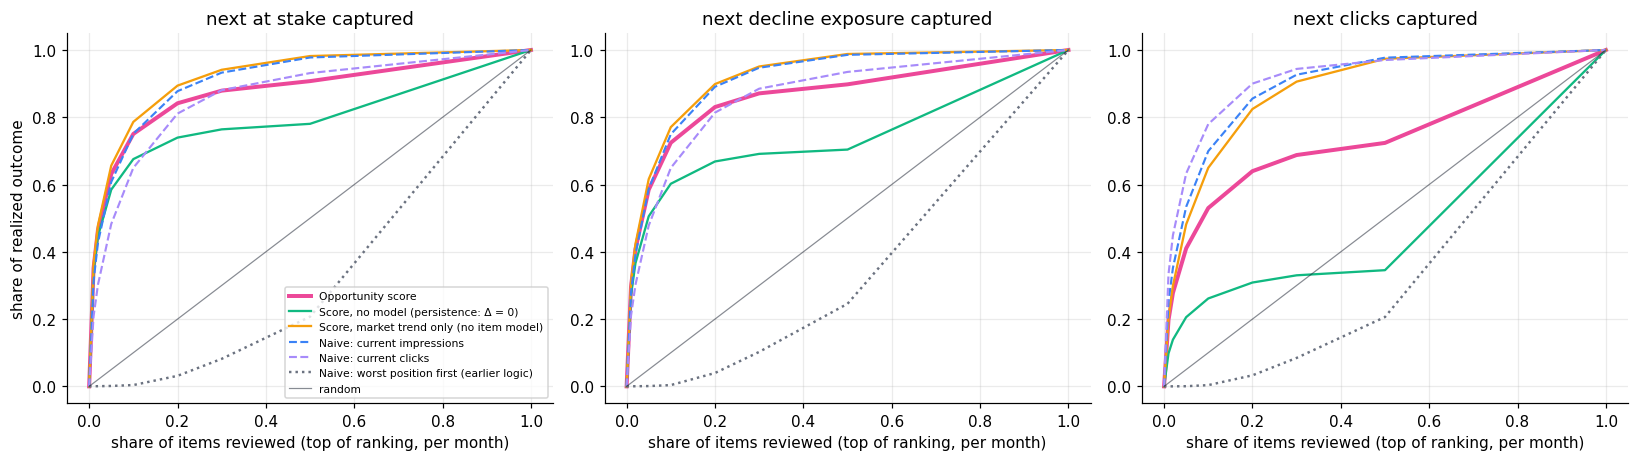

In [ ]:
other = RESULTS["selection"]["other_model"]
Q_PERS = score_queue(dq, np.zeros(len(dq)), CTX_BT)
Q_TREND = score_queue(dq, preds["test"][TREND], CTX_BT)
Q_OTHER = score_queue(dq, preds["test"][other], CTX_BT)

bt = Q_BT.copy()
for c in ["next_impressions", "next_clicks", "next_sum_position", "y_delta"]:
    bt[c] = dq[c].to_numpy()
bt["next_missed_clicks"] = np.maximum(bt["expected_ctr"] * bt["next_impressions"] - bt["next_clicks"], 0)
bt["next_decline_exposure"] = np.maximum(bt["impressions"] - bt["next_impressions"], 0) * bt["expected_ctr"]
bt["next_at_stake"] = bt["next_missed_clicks"] + LAMBDA * bt["next_decline_exposure"]

SCORE = "Opportunity score"
ORDERINGS = {SCORE: bt["score"].to_numpy(),
             f"Score using {other} predictions": Q_OTHER["score"].to_numpy(),
             "Score, no model (persistence: Δ = 0)": Q_PERS["score"].to_numpy(),
             "Score, market trend only (no item model)": Q_TREND["score"].to_numpy(),
             "Predicted missed clicks only": bt["pred_missed_clicks"].to_numpy(),
             "Naive: current impressions": bt["impressions"].to_numpy(),
             "Naive: current clicks": bt["clicks"].to_numpy(),
             "Naive: worst position first (earlier logic)": bt["avg_position"].to_numpy()}
OUTCOMES = {"next_at_stake": bt["next_at_stake"].to_numpy(float), "next_decline_exposure": bt["next_decline_exposure"].to_numpy(float),
            "next_missed_clicks": bt["next_missed_clicks"].to_numpy(float), "next_clicks": bt["next_clicks"].to_numpy(float)}
months_arr, groups_arr = bt["month"].to_numpy(), bt["client_hash_id"].to_numpy()


def month_rank(values):
    return pd.Series(values).groupby(months_arr).rank(pct=True, method="first").to_numpy()


def top_mask(values, frac):
    return month_rank(values) > 1 - frac


def capture_boot(top, outcome, top_b=None, B=1000):
    """Capture (share of outcome inside `top`) with client-clustered CI; with top_b, the paired difference."""
    codes, uniq = pd.factorize(pd.Series(groups_arr))
    g = len(uniq)
    tot = np.bincount(codes, weights=outcome, minlength=g)
    a = np.bincount(codes, weights=outcome * top, minlength=g)
    draws = np.random.default_rng(SEED).integers(0, g, size=(B, g))
    cap_a = a[draws].sum(1) / tot[draws].sum(1)
    if top_b is None:
        return float(a.sum() / tot.sum()), *np.percentile(cap_a, [2.5, 97.5])
    b = np.bincount(codes, weights=outcome * top_b, minlength=g)
    diff = cap_a - b[draws].sum(1) / tot[draws].sum(1)
    return float(a.sum() / tot.sum() - b.sum() / tot.sum()), *np.percentile(diff, [2.5, 97.5])


def client_macro_capture(values, outcome, frac=0.10, min_items=100):
    """Mean over client-months of: share of that client-month's realized outcome inside ITS OWN top `frac` by `values`."""
    r = pd.Series(values).groupby([months_arr, groups_arr]).rank(pct=True, method="first").to_numpy()
    df = pd.DataFrame({"g": groups_arr, "m": months_arr, "out": outcome, "top_out": outcome * (r > 1 - frac)})
    a = df.groupby(["m", "g"]).agg(n=("out", "size"), tot=("out", "sum"), top=("top_out", "sum"))
    a = a[(a["n"] >= min_items) & (a["tot"] > 0)]
    return float((a["top"] / a["tot"]).mean()), int(len(a))


TOP10 = {n: top_mask(v, 0.10) for n, v in ORDERINGS.items()}
bt_rows, bt_store, macro_store = [], {}, {}
for name, top in TOP10.items():
    row = {"ordering": name}
    for oname, out in OUTCOMES.items():
        cap, lo_, hi_ = capture_boot(top, out)
        row[f"{oname} capture@10% [95% CI]"] = fmt_ci(cap, lo_, hi_, 3)
        row[f"{oname} lift×"] = cap / 0.10
        bt_store[(name, oname)] = cap
        if name != SCORE:
            d_, dlo, dhi = capture_boot(TOP10[SCORE], out, top_b=top)
            row[f"{oname}: score − this [CI]"] = fmt_ci(d_, dlo, dhi, 3)
            row[f"{oname}: verdict (score vs this)"] = "score better" if dlo > 0 else ("score worse" if dhi < 0 else "indistinguishable")
    mc, n_cm = client_macro_capture(ORDERINGS[name], OUTCOMES["next_at_stake"])
    row["per-client macro capture@10% (at-stake)"] = mc
    macro_store[name] = mc
    bt_rows.append(row)
bt_df = pd.DataFrame(bt_rows)
display(bt_df[["ordering"] + [c for c in bt_df.columns if "capture@10%" in c or c.endswith("lift×")]])
display(bt_df[["ordering"] + [c for c in bt_df.columns if "verdict" in c]])
print(f"Per-client macro capture computed over {n_cm} client-months with ≥ 100 items (0.10 = random).")
RESULTS["queue"]["backtest"] = bt_df.to_dict(orient="records")
RESULTS["queue"]["backtest_capture"] = {f"{n}|{o}": v for (n, o), v in bt_store.items()}
RESULTS["queue"]["per_client_macro_capture"] = macro_store
RESULTS["queue"]["per_client_macro_client_months"] = n_cm

fracs = [0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.50, 1.0]
rank_cache = {n: month_rank(v) for n, v in ORDERINGS.items()}
shown_orders = [SCORE, "Score, no model (persistence: Δ = 0)", "Score, market trend only (no item model)", "Naive: current impressions",
                "Naive: current clicks", "Naive: worst position first (earlier logic)"]
styles = {SCORE: (PALETTE["accent"], "-", 2.6), "Score, no model (persistence: Δ = 0)": ("#10B981", "-", 1.5),
          "Score, market trend only (no item model)": ("#F59E0B", "-", 1.5), "Naive: current impressions": (PALETTE["Ridge"], "--", 1.4),
          "Naive: current clicks": (PALETTE["Decile"], "--", 1.4), "Naive: worst position first (earlier logic)": (PALETTE["Persistence"], ":", 1.6)}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for k, oname in enumerate(["next_at_stake", "next_decline_exposure", "next_clicks"]):
    out = OUTCOMES[oname]
    for name in shown_orders:
        curve = [out[rank_cache[name] > 1 - f].sum() / out.sum() for f in fracs]
        c, ls, lw = styles[name]
        ax[k].plot([0] + fracs, [0] + curve, color=c, ls=ls, lw=lw, label=name)
    ax[k].plot([0, 1], [0, 1], color=PALETTE["ink"], lw=0.8, alpha=0.5, label="random")
    ax[k].set_xlabel("share of items reviewed (top of ranking, per month)")
    ax[k].set_title(oname.replace("_", " ") + " captured")
ax[0].set_ylabel("share of realized outcome"); ax[0].legend(fontsize=7, loc="lower right")
plt.tight_layout()
savefig("fig10_backtest_gain")

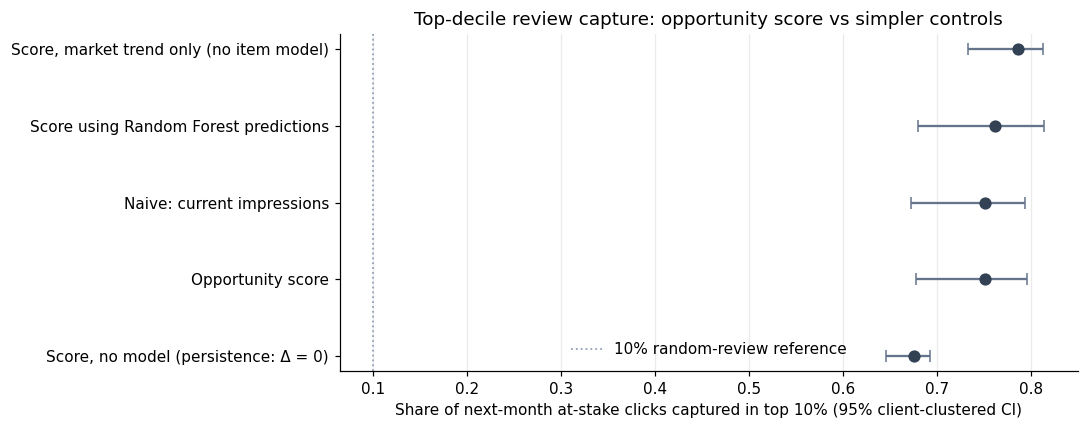

In [ ]:

# Figure 20 — top-decile capture dot plot for the opportunity score and controls.
plot_order=["Opportunity score","Score, no model (persistence: Δ = 0)",
            "Score, market trend only (no item model)","Naive: current impressions",
            "Score using "+RESULTS["selection"]["other_model"]+" predictions"]
plot_order=[x for x in plot_order if x in ORDERINGS]
dot_rows=[]
for name in plot_order:
    val,lo,hi=capture_boot(TOP10[name],OUTCOMES["next_at_stake"],B=500)
    dot_rows.append({"ordering":name,"capture":val,"lo":lo,"hi":hi})
dot_df=pd.DataFrame(dot_rows).sort_values("capture")
fig,ax=plt.subplots(figsize=(10,max(4,.65*len(dot_df))))
yy=np.arange(len(dot_df))
ax.errorbar(dot_df["capture"],yy,xerr=[dot_df["capture"]-dot_df["lo"],dot_df["hi"]-dot_df["capture"]],
            fmt="o",capsize=4,color="#334155",ecolor="#64748B",markersize=7)
ax.axvline(.10,color="#94A3B8",linestyle=":",linewidth=1.2,label="10% random-review reference")
ax.set_yticks(yy); ax.set_yticklabels(dot_df["ordering"])
ax.set_xlabel("Share of next-month at-stake clicks captured in top 10% (95% client-clustered CI)")
ax.set_title("Top-decile review capture: opportunity score vs simpler controls")
ax.legend(frameon=False); ax.grid(axis="y",visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR/"fig20_queue_capture_dotplot.png",dpi=190,bbox_inches="tight",facecolor="white")
plt.show(); plt.close(fig)


### 6.4 Tier calibration and concentration

Do higher (per-client) tiers carry more realized next-month at-stake clicks — and more *declines*? How concentrated is the **global** ranking? (Client labels are anonymised; `Client 1` is the client with the most rows.)

In [ ]:
tier_rows = (bt.groupby("tier", observed=True)
             .agg(items=("score", "size"), median_impressions=("impressions", "median"), median_position=("avg_position", "median"),
                  mean_score=("score", "mean"), mean_realized_next_at_stake=("next_at_stake", "mean"),
                  mean_realized_next_clicks=("next_clicks", "mean")).reset_index())
fell = (bt["y_delta"] <= np.log(0.6)).groupby(bt["tier"], observed=True).mean().rename("share_fell_40pct_next_month")
tier_df = tier_rows.merge(fell.reset_index(), on="tier").set_index("tier").loc[TIERS[::-1]].reset_index()
display(tier_df)
RESULTS["queue"]["tier_backtest"] = tier_df.to_dict(orient="records")

imm = bt[bt["global_tier"] == "Immediate review"]
share_imm = imm["client_hash_id"].value_counts(normalize=True)
share_all = bt["client_hash_id"].value_counts(normalize=True)
anon = {cid: f"Client {i + 1}" for i, cid in enumerate(share_all.index)}
conc_tbl = pd.DataFrame({"share_of_all_items": share_all, "share_of_global_immediate_tier": share_imm}).fillna(0)
conc_tbl["over_representation"] = conc_tbl["share_of_global_immediate_tier"] / conc_tbl["share_of_all_items"]
conc_tbl.index = conc_tbl.index.map(anon)
display(conc_tbl.sort_values("share_of_global_immediate_tier", ascending=False).head(8))
RESULTS["queue"]["concentration"] = {"clients_in_immediate_tier": int(len(share_imm)), "top1_share_immediate": float(share_imm.iloc[0]),
                                     "top3_share_immediate": float(share_imm.iloc[:3].sum()), "hhi_immediate": float((share_imm ** 2).sum()),
                                     "top1_share_all_items": float(share_all.iloc[0]), "ranking": "global"}
print(RESULTS["queue"]["concentration"])
print("→ The GLOBAL ranking is concentrated in a few clients; per-client tiers (the primary output) are balanced by construction.")

,tier,items,median_impressions,median_position,mean_score,mean_realized_next_at_stake,mean_realized_next_clicks,share_fell_40pct_next_month
0,Immediate review,19506,"5,806.0000",6.5312,34.3197,25.8137,26.7914,0.4315
1,High priority,58380,858.0000,8.8362,4.4790,3.6206,6.1023,0.5175
2,Review,116762,145.0000,12.7919,0.8243,0.7932,1.8038,0.5251
3,Monitor,194605,55.0000,16.3226,0.0830,0.5181,2.5193,0.4449


,share_of_all_items,share_of_global_immediate_tier,over_representation
client_hash_id,,,
Client 1,0.1528,0.3148,2.0601
Client 4,0.0812,0.1699,2.0923
Client 6,0.0477,0.0891,1.8662
Client 2,0.1375,0.0867,0.6304
Client 12,0.0264,0.0812,3.0736
Client 13,0.0245,0.0519,2.1186
Client 3,0.1175,0.0387,0.3298
Client 5,0.0519,0.0341,0.6575


{'clients_in_immediate_tier': 40, 'top1_share_immediate': 0.31483764899301275, 'top3_share_immediate': 0.5737772297575011, 'hhi_immediate': 0.15728981737274958, 'top1_share_all_items': 0.15282605400600638, 'ranking': 'global'}
→ The GLOBAL ranking is concentrated in a few clients; per-client tiers (the primary output) are balanced by construction.


### 6.5 Sensitivity — is the ranking an artifact of λ and β?

Twelve (λ, β) combinations (λ ∈ {0, 0.5, 1, 2}, β ∈ {0, 0.5, 1}) plus 100 random draws. For each: the **top-5% overlap with the default queue** (Jaccard) and capture@10% of every realized outcome (the "at-stake" outcome keeps λ = 1 so outcomes are comparable across schemes).

In [ ]:
base_top5 = top_mask(bt["score"].to_numpy(), 0.05)

def eval_scheme(lam, beta):
    s = (bt["pred_missed_clicks"].to_numpy() + lam * bt["decline_exposure"].to_numpy()) * (1 + beta * bt["headroom"].to_numpy())
    r = month_rank(s)
    t5, t10 = r > 0.95, r > 0.90
    return {"top5_overlap_with_default": float((base_top5 & t5).sum() / max((base_top5 | t5).sum(), 1)),
            **{f"capture@10% {o}": float(v[t10].sum() / v.sum()) for o, v in OUTCOMES.items()}}

grid = pd.DataFrame([{"lambda": l, "beta": b, **eval_scheme(l, b)} for l in (0, 0.5, 1, 2) for b in (0, 0.5, 1)])
rng_s = np.random.default_rng(SEED)
rand_eval = pd.DataFrame([eval_scheme(l, b) for l, b in zip(rng_s.uniform(0, 2, 100), rng_s.uniform(0, 1, 100))])
display(grid)
rand_summary = rand_eval.describe().loc[["mean", "min", "max"]]
print("100 random (λ, β) draws:"); display(rand_summary)
RESULTS["queue"]["sensitivity"] = {"grid": grid.to_dict(orient="records"), "random_summary": rand_summary.to_dict()}

,lambda,beta,top5_overlap_with_default,capture@10% next_at_stake,capture@10% next_decline_exposure,capture@10% next_missed_clicks,capture@10% next_clicks
0,0.0000,0.0000,0.6005,0.6725,0.5964,0.7619,0.2608
1,0.0000,0.5000,0.6017,0.6724,0.5951,0.7632,0.2609
2,0.0000,1.0000,0.6001,0.6715,0.5933,0.7635,0.2605
3,0.5000,0.0000,0.8246,0.7452,0.7132,0.7828,0.4964
4,0.5000,0.5000,0.8298,0.7450,0.7112,0.7847,0.4971
5,0.5000,1.0000,0.8228,0.7442,0.7089,0.7856,0.4965
6,1.0000,0.0000,0.9410,0.7507,0.7259,0.7799,0.5297
7,1.0000,0.5000,1.0000,0.7505,0.7243,0.7812,0.5301
8,1.0000,1.0000,0.9616,0.7494,0.7220,0.7817,0.5302
9,2.0000,0.0000,0.8028,0.7486,0.7286,0.7721,0.5525


100 random (λ, β) draws:


,top5_overlap_with_default,capture@10% next_at_stake,capture@10% next_decline_exposure,capture@10% next_missed_clicks,capture@10% next_clicks
mean,0.8557,0.7444,0.7139,0.7803,0.5104
min,0.6053,0.6795,0.6051,0.7670,0.2840
max,0.9852,0.7513,0.7288,0.7856,0.5523


### 6.6 The current queue — scoring the release's final month

The backtest queue is for months whose "next month" has already happened. The **actionable** queue scores the release's **final month**, which has features but no label. For this step only, the selected model is refit on *all* labeled months with the already-chosen hyperparameters; volume thresholds are re-estimated on the same rows; relative prediction thresholds come from the evaluated model's **test-period** out-of-time predictions; the routing gate of §6.1 is **re-applied to the last three labeled months** (validation + test, all out-of-time). ID-level output goes to `outputs_private/` (git-ignored); only anonymous aggregates and an ID-free sample go to `outputs_public/`.

Rolling gate for the LIVE queue (months 2026-03 … 2026-05) — PREDICTED_DECLINE: pooled lift 0.92×; monthly lifts [0.88, 0.67, 0.97]; latest 0.97× → flag only; actions use the OBSERVED counterpart.
Rolling gate for the LIVE queue (months 2026-03 … 2026-05) — PREDICTED_GROWTH: pooled lift 2.48×; monthly lifts [2.2, 2.21, 3.3]; latest 3.30× → ROUTES actions.
Scored 194,174 items for 2026-06 across 46 clients.  Unreachable actions: none


,tier,items,median_impressions,median_position,at_stake_clicks,observed_decline_share
0,Immediate review,9733,"5,342.0000",6.9755,"221,892.0201",0.2233
1,High priority,29122,867.0000,8.9652,"77,706.6600",0.3089
2,Review,58243,172.0000,12.7519,"31,863.9727",0.2694
3,Monitor,97076,27.0000,16.5616,"6,375.1683",0.0955


,recommended_action,items,clients,at_stake_clicks,median_position,median_impressions,median_predicted_change,share_of_tier_items
0,Refresh review (decline risk),7373,31,"55,522.2093",9.6899,"2,269.0000",-0.3850,0.1898
1,Metadata / snippet review,7488,39,"180,616.5718",6.8792,"4,715.5000",-0.2157,0.1927
2,Content improvement review (page-1 push),19418,45,"54,825.0421",7.6955,556.0000,-0.2276,0.4998
3,Rewrite / re-target review,690,31,"1,775.6991",29.0508,"1,222.5000",-0.3036,0.0178
4,Protect & amplify (monitor growth),739,31,"2,173.9149",2.7238,464.0000,-0.0818,0.0190
5,Monitor,3147,41,"4,685.2429",27.1575,209.0000,-0.2851,0.0810



Top of three clients' queues (identifiers withheld; ranks are within each client):


,client_label,priority_rank_in_client,tier,archetype,recommended_action,reason_codes,impressions,clicks,ctr,avg_position,pred_next_impr,at_stake_clicks,score
0,Client 1,1,Immediate review,Page-one performer,Metadata / snippet review,LOW_CTR_FOR_POSITION;HIGH_VISIBILITY,"116,908.0000",550.0000,0.0047,1.9000,"95,885.0000",534.9000,534.9000
1,Client 1,2,Immediate review,Page-one performer,Metadata / snippet review,LOW_CTR_FOR_POSITION;STRIKING_DISTANCE;PREDICT...,"111,728.0000",104.0000,0.0009,4.1000,"73,730.0000",379.8000,531.7000
2,Client 1,3,Immediate review,Page-one performer,Metadata / snippet review,LOW_CTR_FOR_POSITION;STRIKING_DISTANCE;HIGH_VI...,"152,742.0000",557.0000,0.0036,3.7000,"117,130.0000",325.0000,455.0000
29814,Client 2,1,Immediate review,Page-one performer,Metadata / snippet review,LOW_CTR_FOR_POSITION;STRIKING_DISTANCE;HIGH_VI...,"212,758.0000",252.0000,0.0012,4.8000,"185,763.0000",559.1000,782.8000
29815,Client 2,2,Immediate review,Page-one performer,Metadata / snippet review,LOW_CTR_FOR_POSITION;STRIKING_DISTANCE;HIGH_VI...,"147,015.0000",148.0000,0.0010,4.7000,"120,608.0000",410.7000,575.0000
29816,Client 2,3,Immediate review,Page-one performer,Metadata / snippet review,LOW_CTR_FOR_POSITION;STRIKING_DISTANCE;HIGH_VI...,"172,226.0000",348.0000,0.0020,5.5000,"164,151.0000",218.2000,305.5000
54905,Client 3,1,Immediate review,Page-one performer,Metadata / snippet review,LOW_CTR_FOR_POSITION;HIGH_VISIBILITY,"4,831.0000",29.0000,0.0060,2.9000,"4,456.0000",228.3000,228.3000
54906,Client 3,2,Immediate review,"Low-volume, under-clicked",Metadata / snippet review,LOW_CTR_FOR_POSITION;OBSERVED_GROWTH;HIGH_VISI...,"3,667.0000",0.0000,0.0000,2.3000,"3,269.0000",193.2000,193.2000
54907,Client 3,3,Immediate review,Mid-pack / striking distance,Refresh review (decline risk),LOW_CTR_FOR_POSITION;OBSERVED_DECLINE;PREDICTE...,"2,872.0000",3.0000,0.0010,2.7000,"1,933.0000",148.8000,148.8000



ID-level queue written to outputs_private/ (git-ignored). Public sample (top 3 items for each of the 25 largest clients): outputs_public/ranked_queue_sample_public.csv


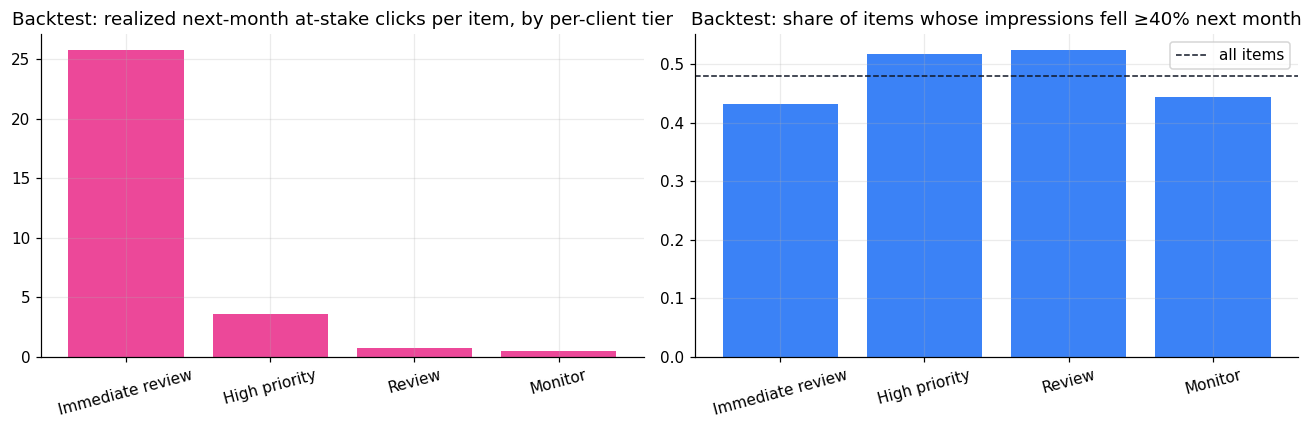

In [ ]:
FIT_COLS = list(dict.fromkeys(FEATURES + ["y_delta", "impressions", "client_hash_id", "month_idx"]))
lab_all = pd.concat([D[s][FIT_COLS] for s in SPLITS], ignore_index=True)
if SELECTED == "XGBoost":
    final_model = fit_xgb(XGB_GRID[best_i], lab_all[FEATURES], lab_all["y_delta"], n_estimators=RESULTS["selection"]["xgb_best_round"], early=False)
else:
    final_model = RandomForestRegressor(**RF_PARAMS).fit(lab_all[FEATURES], lab_all["y_delta"])

live = panel[panel["is_last_month"] & panel["cur_ok"]].reset_index(drop=True)
live["arch_id"] = assign_archetypes(live)
live["archetype"] = live["arch_id"].map(names)
d_vt = pd.concat([D["validation"], D["test"]], ignore_index=True)
pred_vt = np.concatenate([preds["validation"][SELECTED], preds["test"][SELECTED]])
last3 = sorted(d_vt["month"].astype(str).unique())[-3:]
sel3 = d_vt["month"].astype(str).isin(last3).to_numpy()
CTX_VT = make_context(D["train"], pred_vt)
Q_VT = score_queue(d_vt[sel3].reset_index(drop=True), pred_vt[sel3], CTX_VT)
cv_vt = code_validation(Q_VT, d_vt[sel3].reset_index(drop=True))
cv_vt_m = code_validation_by_month(Q_VT, d_vt[sel3].reset_index(drop=True))
ROUTE_DECLINE_LIVE, gate_dec_live = routing_gate(cv_vt, cv_vt_m, "PREDICTED_DECLINE")
ROUTE_GROWTH_LIVE, gate_gro_live = routing_gate(cv_vt, cv_vt_m, "PREDICTED_GROWTH")
for tag, ok, g in (("PREDICTED_DECLINE", ROUTE_DECLINE_LIVE, gate_dec_live), ("PREDICTED_GROWTH", ROUTE_GROWTH_LIVE, gate_gro_live)):
    print(f"Rolling gate for the LIVE queue (months {last3[0]} … {last3[-1]}) — {tag}: pooled lift {g['pooled_lift']:.2f}×; monthly lifts "
          f"{[round(x, 2) for x in g['monthly_lifts']]}; latest {g['last_month_lift']:.2f}× → {'ROUTES actions' if ok else 'flag only; actions use the OBSERVED counterpart'}.")
RESULTS["queue"]["route_pred_decline_live"], RESULTS["queue"]["route_pred_growth_live"] = ROUTE_DECLINE_LIVE, ROUTE_GROWTH_LIVE
RESULTS["queue"]["gate_live"] = {"months": last3, "PREDICTED_DECLINE": gate_dec_live, "PREDICTED_GROWTH": gate_gro_live}
CTX_LIVE = make_context(lab_all, preds["test"][SELECTED], ROUTE_DECLINE_LIVE, ROUTE_GROWTH_LIVE)
del lab_all
gc.collect()
live_pred = xgb_predict(final_model, live[FEATURES]) if SELECTED == "XGBoost" else final_model.predict(live[FEATURES])
Q_LIVE = score_queue(live, live_pred, CTX_LIVE)
live_actions = Q_LIVE["recommended_action"].value_counts()
RESULTS["queue"]["dead_action_branches_live"] = [a for a in ACTIONS if live_actions.get(a, 0) == 0]
print(f"Scored {len(Q_LIVE):,} items for {LAST_MONTH} across {Q_LIVE['client_hash_id'].nunique()} clients.  "
      f"Unreachable actions: {RESULTS['queue']['dead_action_branches_live'] or 'none'}")

client_size = Q_LIVE["client_hash_id"].value_counts()
client_no = {cid: i + 1 for i, cid in enumerate(client_size.index)}            # 1 = client with the most items; anonymous labels
Q_LIVE["client_no"] = Q_LIVE["client_hash_id"].map(client_no)
Q_LIVE["client_label"] = "Client " + Q_LIVE["client_no"].astype(str)
Q_LIVE = Q_LIVE.sort_values(["client_no", "priority_rank_in_client"]).reset_index(drop=True)
Q_LIVE.to_parquet(PRIVATE_DIR / f"ranked_queue_{LAST_MONTH}_INTERNAL.parquet", index=False)
Q_LIVE[Q_LIVE["priority_rank_in_client"] <= 50].to_csv(PRIVATE_DIR / f"ranked_queue_{LAST_MONTH}_top50_per_client_INTERNAL.csv", index=False)
PUBLIC_COLS = ["client_label", "priority_rank_in_client", "tier", "archetype", "recommended_action", "reason_codes", "impressions", "clicks",
               "ctr", "avg_position", "pred_next_impr", "at_stake_clicks", "score"]
top_clients = list(client_size.index[:25])
pub = (Q_LIVE[Q_LIVE["client_hash_id"].isin(top_clients) & (Q_LIVE["priority_rank_in_client"] <= 3)][PUBLIC_COLS]
       .round({"ctr": 4, "avg_position": 1, "pred_next_impr": 0, "at_stake_clicks": 1, "score": 1}))
pub.to_csv(PUBLIC_DIR / "ranked_queue_sample_public.csv", index=False)

live_tier = (Q_LIVE.groupby("tier", observed=True)
             .agg(items=("score", "size"), median_impressions=("impressions", "median"), median_position=("avg_position", "median"),
                  at_stake_clicks=("at_stake_clicks", "sum"),
                  observed_decline_share=("reason_codes", lambda s: s.str.contains("OBSERVED_DECLINE").mean()))
             .loc[TIERS[::-1]].reset_index())
live_tier.to_csv(PUBLIC_DIR / "tier_summary_public.csv", index=False)
display(live_tier)

top_tiers = Q_LIVE[Q_LIVE["tier"].isin(["Immediate review", "High priority"])]
playbook = (top_tiers.groupby("recommended_action")
            .agg(items=("score", "size"), clients=("client_hash_id", "nunique"), at_stake_clicks=("at_stake_clicks", "sum"),
                 median_position=("avg_position", "median"), median_impressions=("impressions", "median"),
                 median_predicted_change=("pred_delta", "median"))
            .reindex(ACTIONS).dropna(how="all").reset_index())
playbook["share_of_tier_items"] = playbook["items"] / playbook["items"].sum()
display(playbook)
print("\nTop of three clients' queues (identifiers withheld; ranks are within each client):")
show(pub.head(9))
print(f"\nID-level queue written to {PRIVATE_DIR.name}/ (git-ignored). Public sample (top 3 items for each of the 25 largest clients): "
      f"{PUBLIC_DIR.name}/ranked_queue_sample_public.csv")

tot_stake = float(Q_LIVE["at_stake_clicks"].sum())
RESULTS["queue"]["live"] = {"month": LAST_MONTH, "items": int(len(Q_LIVE)), "clients": int(Q_LIVE["client_hash_id"].nunique()),
                            "tiers": live_tier.to_dict(orient="records"), "playbook": playbook.to_dict(orient="records"),
                            "total_at_stake_clicks": tot_stake,
                            "immediate_share_of_at_stake": float(Q_LIVE.loc[Q_LIVE["tier"] == "Immediate review", "at_stake_clicks"].sum() / max(tot_stake, 1e-9)),
                            "refit_on": "all labeled months (train+validation+test), hyperparameters fixed from §4.2",
                            "public_sample_rows": int(len(pub)), "queue_unit": "per-client tiers"}

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(tier_df["tier"], tier_df["mean_realized_next_at_stake"], color=PALETTE["accent"])
ax[0].set_title("Backtest: realized next-month at-stake clicks per item, by per-client tier"); ax[0].tick_params(axis="x", rotation=15)
ax[1].bar(tier_df["tier"], tier_df["share_fell_40pct_next_month"], color=PALETTE["Ridge"])
ax[1].axhline(float((bt["y_delta"] <= np.log(0.6)).mean()), color=PALETTE["ink"], ls="--", lw=1, label="all items")
ax[1].set_title("Backtest: share of items whose impressions fell ≥40% next month"); ax[1].tick_params(axis="x", rotation=15); ax[1].legend()
plt.tight_layout()
savefig("fig11_tier_calibration")

## 7. Limitations and honest framing

**Language used throughout.** *Observed* = a descriptive fact about this panel. *Directional* = an association or out-of-time pattern that may not transfer. *Decision-support* = a ranking meant to focus human review; it is not a forecast guarantee.

**Standing limitations** (true regardless of results):

* Observational data only. Nothing here establishes how Google ranks pages, and nothing estimates the effect of changing a page.
* Average position is an impression-weighted mean over many queries. Expected CTR is **peer-relative** (same client, same month, same position bucket), so "missed clicks" is a **screening estimate within a client**, not a forecast of clicks gained and not a statement about a typical results page.
* Monthly granularity; no page-text, query-level, backlink or competitor features are available, so the playbook produces *review prompts*, not prescriptions. Merge/prune decisions need data this release does not contain.
* One release, one panel of clients: results describe this panel and period.
* Validation months were used for early stopping, model selection and the routing gate, so validation scores are mildly optimistic; test months are the honest estimate and were used once.

The next cell adds the **data-driven** caveats computed from this run — including every validity finding from §2.

In [ ]:
VERB_EARLY = {"better": "lower error than", "worse": "higher error than", "indistinguishable": "error statistically indistinguishable from"}

def pct(x, nd=1):
    return "n/a" if (x is None or not np.isfinite(x)) else f"{x:.{nd}%}"

def num(x, nd=2):
    return "n/a" if (x is None or not np.isfinite(x)) else f"{x:.{nd}f}"

lim = []
L_ = RESULTS["ledger"]
# --- position field
pa = RESULTS["position_audit"]
if pa["code"] == "disagree":
    lim.append(f"The sum-based position disagreed with the warehouse's own average position (only {pct(pa['share_within_1_position'])} of rows within one position), so the impression-weighted "
               "warehouse average was used; position-based findings depend on that choice.")
elif pa["code"] == "sparse":
    lim.append(f"The warehouse's own average-position field covers only {pct(pa['weighted_field_coverage'])} of rows, so the two position fields could not be fully cross-checked; the sum-based field was used.")
else:
    lim.append(f"The sum-based position and the warehouse's own average position agree ({pct(pa['share_within_1_position'])} of rows within one position), so the sum-based field was used.")
ib = L_["invalid_breakdown"]
cand = L_["observations"] + ib["any_reason"]
if ib["any_reason"] == 0:
    lim.append("No rows were dropped as implausible (clicks > impressions, missing or impossible position, non-finite values).")
else:
    lim.append(f"{ib['any_reason']:,} candidate rows ({ib['any_reason'] / max(cand, 1):.1%}) were dropped as implausible — no position reported: {ib['position_missing']:,}; impossible position between 0 and 1: "
               f"{ib['position_between_0_and_1']:,}; clicks > impressions: {ib['clicks_gt_impressions']:,}. Median impressions are {ib['median_impressions_dropped']:,.0f} for dropped rows versus "
               f"{ib['median_impressions_kept']:,.0f} for kept rows, so the filter removes {'smaller' if ib['median_impressions_dropped'] < ib['median_impressions_kept'] else 'larger'}-volume items.")
# --- benchmark
bm = RESULTS["benchmark"]
if bm["plausible"]:
    lim.append(f"The pooled CTR-by-position prior falls steeply with position (CTR@1 {bm['prior_at_positions'][1]:.1%}, {bm['ctr1_over_ctr10']:.1f}× CTR@10), as expected for web-search metrics; "
               "expected CTR is nevertheless peer-relative, so missed-click estimates remain screening estimates within a client.")
else:
    lim.append(f"The pooled CTR-by-position prior is NOT plausible for standard web-search metrics (CTR@1 {bm['prior_at_positions'][1]:.2%}; CTR@1 is {bm['ctr1_over_ctr10']:.1f}× CTR@10). "
               "Position or click fields may not behave like organic web-search data, so 'missed clicks' are peer-relative only and must not be read as clicks relative to a typical results page.")
# --- duplicates
du = RESULTS["duplicates"]
if du["flagged_rows"]:
    lim.append(f"{du['flagged_rows']:,} observations ({du['share_of_observations']:.2%}) sit in duplicated metric blocks across {du['clients_affected']} client(s) (exact rule {du['exact_rows']:,}; caught only by the "
               f"near-duplicate rule {du['near_only_rows']:,}; largest block {du['largest_block_items']} items) and were {'excluded' if du['excluded'] else 'kept'}; zero next-month labels occur in "
               f"{pct(du['zero_label_share_in_blocks'])} of those rows versus {pct(du['zero_label_share_elsewhere'])} elsewhere. Replicated blocks outside both rules, if any, would remain.")
# --- zero labels
zt = {r["split"]: r for r in RESULTS["zero_targets"]}
lim.append(f"Zero next-month impressions are {pct(zt['train']['zero_label_share'])} of training labels, {pct(zt['validation']['zero_label_share'])} of validation and {pct(zt['test']['zero_label_share'])} of test "
           f"labels (present-but-zero share in test: {pct(zt['test']['of_which_present_but_zero'])}). A zero can reflect lost demand or an item-level data gap, which this release cannot separate; results excluding zeros are in §4.9.")
# --- regime
rg = {r["split"]: r for r in RESULTS["regime"]["by_split"]}
bias = RESULTS["error_analysis"]["overall"]["mean_signed_error"]
lim.append(f"The market moved differently across periods: on average {pct(rg['train']['mean_share_fell'], 0)} of items fell month-over-month in training months versus {pct(rg['test']['mean_share_fell'], 0)} in test months"
           f"{' (a regime shift)' if RESULTS['regime']['shift_flag'] else ''}; the mean signed error of {SELECTED} on test is {bias:+.2f} log units. A model trained in one regime carries a bias into the next.")
# --- GA4 coverage and time proxy
tc = RESULTS["train_composition"]
lim.append(f"GA4 coverage differs sharply across time: {tc['share_train_rows_with_ga4']:.1%} of training rows carry any GA4 data versus {tc['share_test_rows_with_ga4']:.1%} of test rows, and "
           f"Spearman(has_ga4, calendar month) in training is {RESULTS['importance']['ga4_time_proxy_rho']:.2f}; GA4 features can therefore act partly as time indicators, and GA4 findings describe this release, not GA4.")
# --- models vs persistence + disclosure
pv = RESULTS["paired_vs_persistence"]
better = [r["model"] for r in pv if r["verdict vs persistence"] == "better"]
worse = [r["model"] for r in pv if r["verdict vs persistence"] == "worse"]
lim.append("Paired with persistence on the test months: " + (f"lower error — {', '.join(better)}. " if better else "no model or baseline shows reliably lower error. ")
           + (f"Higher error — {', '.join(worse)}. " if worse else "") + "All other comparisons are statistically indistinguishable.")
pt = RESULTS["paired_vs_trend"]
better_t = [r["model"] for r in pt if r["verdict vs trend baseline"] == "better"]
worse_t = [r["model"] for r in pt if r["verdict vs trend baseline"] == "worse"]
lim.append("Paired with the model-free trailing-market baseline on the test months: " + (f"lower error — {', '.join(better_t)}. " if better_t else "no model or baseline shows reliably lower error. ")
           + (f"Higher error — {', '.join(worse_t)}. " if worse_t else "") + "All other comparisons are statistically indistinguishable.")
lim.append(RESULTS["selection"]["disclosure"])
_w = {r["model"]: r for r in RESULTS["weighted"]["rows"]}[SELECTED]
lim.append(f"Volume view for {SELECTED}: {RESULTS['weighted']['share_rows_ge_100']:.0%} of test rows (carrying {RESULTS['weighted']['share_impressions_ge_100']:.0%} of impressions) have at least 100 impressions; "
           f"impression-weighted ΔMAE versus persistence {_w['weighted Δ vs persistence']} and versus the trend baseline {_w['weighted Δ vs trend']}; on items with ≥ 100 impressions "
           f"{_w['≥100 Δ vs persistence']} and {_w['≥100 Δ vs trend']}, respectively. Row-weighted MAE alone is dominated by very small items.")
_wf = {r["method"]: r for r in RESULTS["walk_forward"]["test_table"]}
_vw = {"better": "better than", "worse": "worse than", "indistinguishable": "indistinguishable from"}
lim.append("Walk-forward retraining (a post-hoc protocol added after the first test evaluation; hyperparameters not re-tuned) on the test months: "
           f"{WF_LEVEL} is {_vw[_wf[WF_LEVEL]['verdict vs persistence']]} persistence and {_vw[_wf[WF_LEVEL]['verdict vs trend']]} the trend baseline; "
           f"{WF_RESID} is {_vw[_wf[WF_RESID]['verdict vs persistence']]} persistence and {_vw[_wf[WF_RESID]['verdict vs trend']]} the trend baseline. It is reported alongside, not instead of, the pre-registered single-split result.")
auc = RESULTS["drift"]["adversarial_auc"]
lim.append(f"Training and test rows are {'clearly' if auc > 0.7 else 'only modestly'} distinguishable (adversarial AUC {auc:.2f}); validation→test MAE grew "
           f"{RESULTS['val_to_test_mae_ratio'][SELECTED]:.2f}× for {SELECTED} versus {RESULTS['val_to_test_mae_ratio'][PERSIST]:.2f}× for persistence, so accuracy should be read as period-specific.")
new_cl = [r for r in RESULTS["segments"] if r["segment"].startswith("new clients")]
if new_cl:
    lim.append(f"For clients not seen in training ({new_cl[0]['rows']:,} test rows) the paired ΔMAE versus persistence is {new_cl[0]['ΔMAE_vs_persistence [95% CI]']} ({new_cl[0]['verdict']}).")
# --- archetypes
av = RESULTS["archetypes"]["validation"]
if not av["validated"]:
    lim.append(f"Archetypes did not pass the outcome-separation gate (η² = {av['eta_squared']:.3f}; permutation p = {av['permutation_p']:.3f}; archetype-median forecast versus persistence: "
               f"{av['vs_persistence']['verdict']}), so they are descriptive only and the action map is a review heuristic, not a validated policy.")
if RESULTS["archetypes"]["caveat"]:
    lim.append(RESULTS["archetypes"]["caveat"])
# --- queue versus controls and reason codes
_bt = {r["ordering"]: r for r in RESULTS["queue"]["backtest"]}
other_m = RESULTS["selection"]["other_model"]
for oname, why in [("Naive: current impressions", "ranking by current impressions"),
                   ("Score, no model (persistence: Δ = 0)", "the same score computed with no model"),
                   ("Score, market trend only (no item model)", "the same score driven by a market-wide trend only"),
                   (f"Score using {other_m} predictions", f"the same score using {other_m} predictions")]:
    v = _bt[oname]["next_at_stake: verdict (score vs this)"]
    if v != "score better":
        lim.append(f"On realized next-month at-stake clicks the opportunity score is not demonstrably better than {why} (paired verdict: {v})"
                   + ("; the item-level forecast therefore adds no demonstrated value to the queue." if "no model" in oname or "trend" in oname else "."))
cvt = {r["reason_code"]: r for r in RESULTS["queue"]["code_validation_test"]}
_rq = RESULTS["queue"]
_r = lambda x: "routes" if x else "does not route"
lim.append("Reason-code lifts on the test months (flagged ÷ unflagged realized rate): "
           + ", ".join(f"{k} {num(cvt[k]['lift'])}×" for k in ("PREDICTED_DECLINE", "OBSERVED_DECLINE", "PREDICTED_GROWTH", "OBSERVED_GROWTH", "LOW_CTR_FOR_POSITION") if k in cvt)
           + ". A lift near 1 means the code is a label, not evidence; a lift below 1 means the opposite of the code's implication happened more often among flagged items (mean reversion). "
           f"Rolling-gate routing — backtest (validation months): predicted decline {_r(_rq['route_pred_decline'])} actions, predicted growth {_r(_rq['route_pred_growth'])} actions; "
           f"live queue (last three labeled months): predicted decline {_r(_rq['route_pred_decline_live'])} actions, predicted growth {_r(_rq['route_pred_growth_live'])} actions.")
if _rq["non_selective_codes"]:
    lim.append(f"Reason codes flagging more than 35% of items on validation (non-selective, so weak as triage signals): {', '.join(_rq['non_selective_codes'])}.")
cc = RESULTS["queue"]["concentration"]
lim.append(f"The GLOBAL ranking is concentrated (largest client holds {cc['top1_share_immediate']:.1%} of the global Immediate tier; {cc['clients_in_immediate_tier']} clients appear), "
           "which is why the queue is built per client.")
if RESULTS["queue"]["dead_action_branches"] or RESULTS["queue"]["dead_action_branches_live"]:
    lim.append(f"Unreachable action labels — backtest: {RESULTS['queue']['dead_action_branches']}; current queue: {RESULTS['queue']['dead_action_branches_live']}.")
RESULTS["limitations_dynamic"] = lim
for i, t in enumerate(lim, 1):
    print(f"{i}. {t}\n")

1. The sum-based position and the warehouse's own average position agree (100.0% of rows within one position), so the sum-based field was used.

2. 57,253 candidate rows (3.7%) were dropped as implausible — no position reported: 45,431; impossible position between 0 and 1: 11,822; clicks > impressions: 0. Median impressions are 1 for dropped rows versus 118 for kept rows, so the filter removes smaller-volume items.

3. The pooled CTR-by-position prior is NOT plausible for standard web-search metrics (CTR@1 0.58%; CTR@1 is 1.7× CTR@10). Position or click fields may not behave like organic web-search data, so 'missed clicks' are peer-relative only and must not be read as clicks relative to a typical results page.

4. 6,122 observations (0.41%) sit in duplicated metric blocks across 8 client(s) (exact rule 5,424; caught only by the near-duplicate rule 698; largest block 833 items) and were excluded; zero next-month labels occur in 4.0% of those rows versus 9.2% elsewhere. Replicated block

## 8. Reproducibility

* **Data:** gated Hugging Face release (read token in `HF_TOKEN` / Colab Secrets); never committed. ID-level artifacts live in `outputs_private/` (git-ignored).
* **Determinism:** global seed 42; bootstrap resamples use fixed seeds; model seeds fixed. XGBoost/Random Forest multithreading can introduce last-digit differences across machines, which is why every paper number is generated from this run rather than typed in.
* **Environment:** exact package versions are written to `outputs_public/requirements-lock.txt`; a run record (timestamps, config, git commit) goes to `outputs_public/run_record.json`.
* **Order:** run top to bottom, then **save the notebook** so outputs and execution counts are stored with it.

In [ ]:
import subprocess
from datetime import datetime, timezone

def git_commit():
    try:
        return subprocess.run(["git", "rev-parse", "HEAD"], cwd=REPO_ROOT, capture_output=True, text=True, timeout=5).stdout.strip() or None
    except Exception:
        return None

KEY_PKGS = ["duckdb", "pandas", "numpy", "scikit-learn", "xgboost", "shap", "pyarrow", "matplotlib", "scipy"]
versions = {p: metadata.version(p) for p in KEY_PKGS}
RUN_RECORD = {"finished_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "python": platform.python_version(),
              "packages": versions, "seed": SEED, "release": RESULTS["data"]["release"],
              "min_client_coverage": MIN_CLIENT_COVERAGE, "position_source": POS_CHOICE, "exclude_duplicate_blocks": EXCLUDE_DUPLICATE_BLOCKS,
              "splits": SPLITS, "selected_model": SELECTED, "git_commit": git_commit()}
(PUBLIC_DIR / "requirements-lock.txt").write_text("\n".join(f"{p}=={v}" for p, v in versions.items()) + "\n")
(PUBLIC_DIR / "run_record.json").write_text(json.dumps(to_jsonable(RUN_RECORD), indent=2))
print(json.dumps(to_jsonable(RUN_RECORD), indent=2))

{
  "finished_utc": "2026-11-12T16:27:07+00:00",
  "python": "3.13.18",
  "packages": {
    "duckdb": "1.3.2",
    "pandas": "2.2.3",
    "numpy": "2.4.6",
    "scikit-learn": "1.6.1",
    "xgboost": "3.4.1",
    "shap": "0.54.1",
    "pyarrow": "23.0.1",
    "matplotlib": "3.10.0",
    "scipy": "1.16.3"
  },
  "seed": 42,
  "release": "FlyRank ML Internship warehouse (Hugging Face: FlyRank/internship-warehouse)",
  "min_client_coverage": 0.85,
  "position_source": "sum",
  "exclude_duplicate_blocks": true,
  "splits": {
    "train": [
      "2025-01",
      "2025-02",
      "2025-03",
      "2025-04",
      "2025-05",
      "2025-06",
      "2025-07",
      "2025-08",
      "2025-09",
      "2025-10",
      "2025-11",
      "2025-12"
    ],
    "validation": [
      "2026-01",
      "2026-02",
      "2026-03"
    ],
    "test": [
      "2026-04",
      "2026-05"
    ]
  },
  "selected_model": "XGBoost",
  "git_commit": null
}


## 9. Paper assets

Everything below is generated from `RESULTS`; nothing is typed by hand.

### 9.1 Results file and the abstract (exactly five sentences: question → method → result)

In [ ]:
(PUBLIC_DIR / "results_summary.json").write_text(json.dumps(to_jsonable(RESULTS), indent=2))

VERB = {"better": "lower error than", "worse": "higher error than", "indistinguishable": "error statistically indistinguishable from"}

def sentences(text):
    return [s for s in re.split(r"(?<=[.!?])\s+(?=[A-Z])", text.strip()) if s]

def join_and(items):
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " and " + items[-1]

def build_abstract():
    L, M = RESULTS["ledger"], RESULTS["models"]
    sel, oth = RESULTS["selection"]["selected"], RESULTS["selection"]["other_model"]
    pv = {r["model"]: r for r in RESULTS["paired_vs_persistence"]}
    t_sel, t_per, t_oth = M[sel]["test"], M[PERSIST]["test"], M[oth]["test"]
    test_span = f"{min(SPLITS['test'])} to {max(SPLITS['test'])}"
    abl = {r["step"]: r for r in RESULTS["ablation"]["rows"]}
    label = {"A. level only": "level-only features", "B. + GSC signals": "adding GSC click, CTR and position features",
             "C. + lag / history": "adding month-over-month history", "D. + GA4 / traffic (full)": "the full feature set"}
    better = [label[k] for k in label if abl[k]["verdict vs persistence"] == "better"]
    worse = [label[k] for k in label if abl[k]["verdict vs persistence"] == "worse"]
    ga4s = RESULTS["ablation"]["ga4_subset"]
    q = {r["ordering"]: r for r in RESULTS["queue"]["backtest"]}
    cap = RESULTS["queue"]["backtest_capture"]
    cap_s, cap_n = cap["Opportunity score|next_at_stake"], cap["Naive: current impressions|next_at_stake"]
    v_n = q["Naive: current impressions"]["next_at_stake: verdict (score vs this)"]
    key_v = "next_at_stake: verdict (score vs this)"
    v_pers, v_trend = q["Score, no model (persistence: Δ = 0)"][key_v], q["Score, market trend only (no item model)"][key_v]
    # the model only "adds value" if it beats BOTH no-model controls; the market-trend control is the harder one
    v_c = "score better" if (v_pers == "score better" and v_trend == "score better") else ("score worse" if "score worse" in (v_pers, v_trend) else "indistinguishable")
    referent = ("the same score driven by a market-wide trend alone" if v_trend == "score worse" else
                "the same score computed with no model" if v_pers == "score worse" else
                "the same score computed with no item-level model (persistence or a market-wide trend)")
    v_phrase = {"score better": "favours the score", "score worse": "favours ranking by current impressions", "indistinguishable": "is statistically indistinguishable"}[v_n]
    c_phrase = {"score better": "the item-level forecast improves on", "score worse": "the item-level forecast is worse than",
                "indistinguishable": "the item-level forecast adds nothing distinguishable to"}[v_c]

    s1 = ("This study asks which observable Google Search Console and GA4 signals are associated with search-performance movement, "
          "and whether structured content-performance archetypes can be discovered, validated and used to guide human review.")
    s2 = (f"Daily FlyRank warehouse records from {RESULTS['data']['first_date']} to {RESULTS['data']['last_date']} are audited for feed health, position consistency, duplicated blocks "
          f"and market-wide regime shifts and aggregated to {L['labeled_rows']:,} labeled item-month observations; ranking-signal feature groups are evaluated against baselines, and training-defined archetypes are clustered and tested "
          "alongside Random Forest and XGBoost comparisons with persistence, trailing-market, constant, decile and ridge baselines under a chronological split with client-clustered bootstrap intervals and a post-hoc walk-forward retraining check.")
    pvt = {r["model"]: r for r in RESULTS["paired_vs_trend"]}
    t_trd = M[TREND]["test"]
    s3 = (f"On the held-out test months {test_span}, the pre-selected {sel} reaches an MAE of {t_sel['MAE']:.3f} (95% CI {t_sel['MAE_lo']:.3f} to {t_sel['MAE_hi']:.3f}) against {t_per['MAE']:.3f} "
          f"for persistence and {t_trd['MAE']:.3f} for a model-free trailing-market baseline (which itself shows {VERB[pv[TREND]['verdict vs persistence']]} persistence), with {sel} showing "
          f"{VERB[pv[sel]['verdict vs persistence']]} persistence and {VERB[pvt[sel]['verdict vs trend baseline']]} the trend baseline, while {oth} reaches {t_oth['MAE']:.3f} "
          f"({VERB[pv[oth]['verdict vs persistence']]} persistence; {VERB[pvt[oth]['verdict vs trend baseline']]} the trend baseline).")
    head = (f"Directionally, {join_and(better)} give a distinguishable out-of-time improvement over persistence" if better
            else "Directionally, no feature group gives a distinguishable out-of-time improvement over persistence")
    tail = (f" ({join_and(worse)} {'is' if len(worse) == 1 else 'are'} worse)" if worse else "")
    ga4 = (", although GA4 features reduce error on the rows where GA4 data exist" if ga4s and ga4s["verdict"] == "better" else "")
    reg = ", in a test period whose market-wide direction differs sharply from training" if RESULTS["regime"]["shift_flag"] else ""
    wf_rows = {r["method"]: r for r in RESULTS["walk_forward"]["test_table"]}
    wf_name = RESULTS["walk_forward"]["best_walk_forward_on_test"]
    wf_clause = (f"; with monthly walk-forward retraining (a post-hoc protocol) the better variant, {wf_name}, shows {VERB[wf_rows[wf_name]['verdict vs trend']]} the trend baseline "
                 f"and {VERB[wf_rows[wf_name]['verdict vs persistence']]} persistence")
    s4 = head + tail + ga4 + reg + wf_clause + "."
    s5 = (f"The resulting reason-coded per-client review queue captures {cap_s:.0%} of realized next-month at-stake clicks in its top decile ({cap_s / 0.10:.1f} times a random ordering) "
          f"versus {cap_n:.0%} when ranking by current impressions (a paired comparison that {v_phrase}), and {c_phrase} {referent}, "
          "so it is offered as observational decision support, not as a claim about Google's algorithm or the effect of refreshing pages.")
    text = " ".join([s1, s2, s3, s4, s5])
    assert len(sentences(text)) == 5, f"abstract has {len(sentences(text))} sentences"
    return text

ABSTRACT = build_abstract()
RESULTS["abstract"] = ABSTRACT
print(textwrap.fill(ABSTRACT, 110))
print(f"\nSentences: {len(sentences(ABSTRACT))}")

This study asks which observable Google Search Console and GA4 signals are associated with search-performance
movement, and whether structured content-performance archetypes can be discovered, validated and used to guide
human review. Daily FlyRank warehouse records from 2025-01-27 to 2026-06-30 are audited for feed health,
position consistency, duplicated blocks and market-wide regime shifts and aggregated to 1,208,682 labeled
item-month observations; ranking-signal feature groups are evaluated against baselines, and training-defined
archetypes are clustered and tested alongside Random Forest and XGBoost comparisons with persistence,
trailing-market, constant, decile and ridge baselines under a chronological split with client-clustered
bootstrap intervals and a post-hoc walk-forward retraining check. On the held-out test months 2026-04 to
2026-05, the pre-selected XGBoost reaches an MAE of 0.944 (95% CI 0.839 to 1.081) against 0.954 for
persistence and 0.884 for a model-free trailing-

### 9.2 Build the deployed paper (`docs/index.html`)

A single self-contained HTML page (figures embedded) with the nine required sections. Enable **GitHub Pages → Deploy from branch → `/docs`**, or copy `docs/index.html` to your own site.

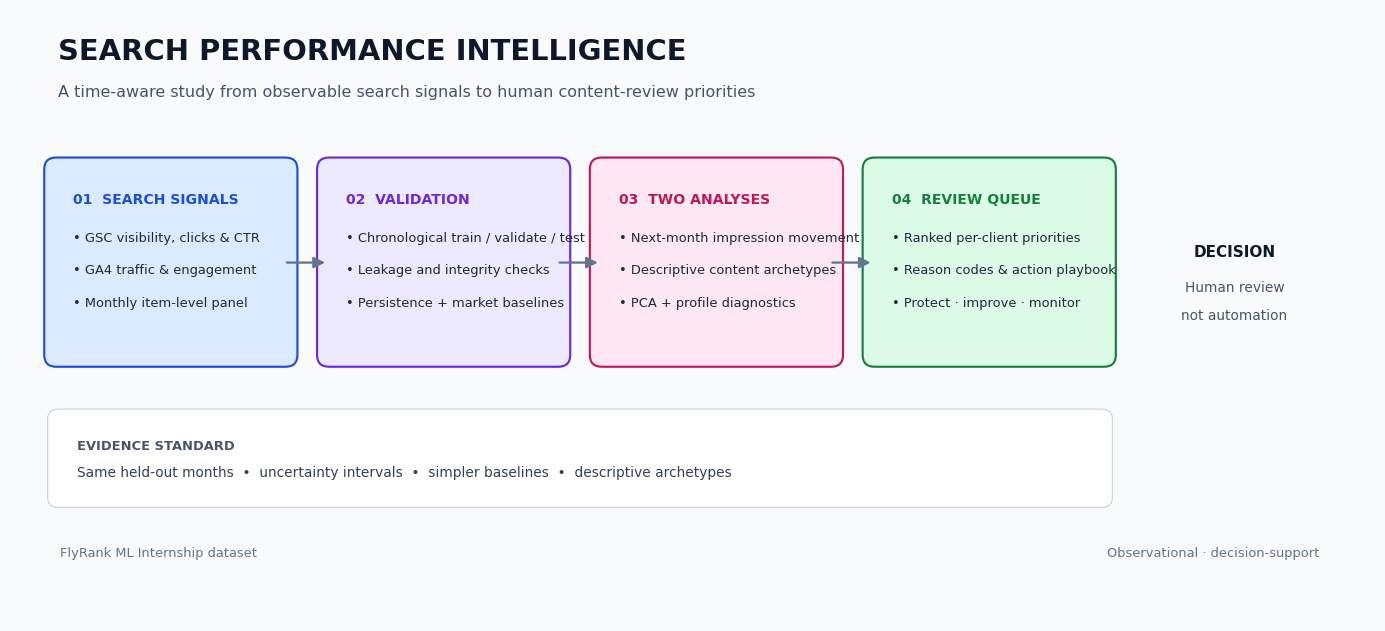

Saved graphical abstract: /content/docs/figures/fig00_graphical_abstract.png


In [ ]:

# Figure 00 — graphical abstract embedded in the deployed paper.
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
fig,ax=plt.subplots(figsize=(16,7.2))
fig.patch.set_facecolor("#F8FAFC"); ax.set_facecolor("#F8FAFC")
ax.set_xlim(0,16); ax.set_ylim(0,7.2); ax.axis("off")
ax.text(.55,6.62,"SEARCH PERFORMANCE INTELLIGENCE",fontsize=19,weight="bold",color="#0F172A")
ax.text(.55,6.18,"A time-aware study from observable search signals to human content-review priorities",fontsize=10.5,color="#475569")
cards=[
(.55,3.15,2.65,2.15,"01  SEARCH SIGNALS",["GSC visibility, clicks & CTR","GA4 traffic & engagement","Monthly item-level panel"],"#DBEAFE","#1D4ED8"),
(3.75,3.15,2.65,2.15,"02  VALIDATION",["Chronological train / validate / test","Leakage and integrity checks","Persistence + market baselines"],"#EDE9FE","#6D28D9"),
(6.95,3.15,2.65,2.15,"03  TWO ANALYSES",["Next-month impression movement","Descriptive content archetypes","PCA + profile diagnostics"],"#FCE7F3","#BE185D"),
(10.15,3.15,2.65,2.15,"04  REVIEW QUEUE",["Ranked per-client priorities","Reason codes & action playbook","Protect · improve · monitor"],"#DCFCE7","#15803D")]
for x,y,w,h,title,lines,face,edge in cards:
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle="round,pad=.16,rounding_size=.14",linewidth=1.4,edgecolor=edge,facecolor=face))
    ax.text(x+.18,y+h-.38,title,fontsize=9.2,weight="bold",color=edge)
    for j,line in enumerate(lines): ax.text(x+.18,y+h-.83-j*.38,"• "+line,fontsize=8.5,color="#1E293B")
for x1,x2 in [(3.2,3.72),(6.4,6.92),(9.6,10.12)]:
    ax.add_patch(FancyArrowPatch((x1,4.22),(x2,4.22),arrowstyle="-|>",mutation_scale=15,linewidth=1.5,color="#64748B"))
ax.add_patch(FancyBboxPatch((.55,1.45),12.25,.92,boxstyle="round,pad=.12,rounding_size=.12",linewidth=.8,edgecolor="#CBD5E1",facecolor="#FFFFFF"))
ax.text(.78,2.02,"EVIDENCE STANDARD",fontsize=8.5,weight="bold",color="#475569")
ax.text(.78,1.70,"Same held-out months  •  uncertainty intervals  •  simpler baselines  •  descriptive archetypes",fontsize=9,color="#334155")
ax.text(14.35,4.30,"DECISION",fontsize=10,weight="bold",color="#0F172A",ha="center")
ax.text(14.35,3.88,"Human review",fontsize=9,color="#475569",ha="center")
ax.text(14.35,3.55,"not automation",fontsize=9,color="#475569",ha="center")
ax.text(.58,.75,"FlyRank ML Internship dataset",fontsize=8.5,color="#64748B")
ax.text(15.35,.75,"Observational · decision-support",fontsize=8.5,color="#64748B",ha="right")
fig.savefig(FIG_DIR/"fig00_graphical_abstract.png",dpi=220,bbox_inches="tight",facecolor=fig.get_facecolor())
plt.show(); plt.close(fig)
print("Saved graphical abstract:",FIG_DIR/"fig00_graphical_abstract.png")


In [ ]:
PAPER_CSS = """
:root{--bg:#fff;--fg:#111827;--mut:#6b7280;--ac:#be185d;--card:#f9fafb;--bd:#e5e7eb}
@media (prefers-color-scheme:dark){:root{--bg:#0b0f19;--fg:#e5e7eb;--mut:#9ca3af;--ac:#f472b6;--card:#111827;--bd:#1f2937}}
*{box-sizing:border-box}body{margin:0;background:var(--bg);color:var(--fg);font:16px/1.65 system-ui,-apple-system,Segoe UI,Roboto,sans-serif}
main{max-width:860px;margin:0 auto;padding:2rem 1.2rem 5rem}h1{font-size:2rem;line-height:1.2;margin:.2rem 0}
h2{margin-top:2.6rem;border-bottom:1px solid var(--bd);padding-bottom:.3rem}h3{margin-top:1.6rem}
.meta,.note,figcaption{color:var(--mut);font-size:.9rem}.abstract{background:var(--card);border-left:4px solid var(--ac);padding:1rem 1.2rem;border-radius:6px}
figure{margin:1.4rem 0}img{max-width:100%;height:auto;border-radius:6px}
.tbl{border-collapse:collapse;width:100%;font-size:.85rem}.tbl th,.tbl td{padding:.35rem .5rem;border-bottom:1px solid var(--bd);text-align:left}
.tblwrap{overflow-x:auto}.tag{display:inline-block;font-size:.72rem;padding:.05rem .45rem;border-radius:999px;border:1px solid var(--ac);color:var(--ac);margin-right:.35rem}
a{color:var(--ac)}code{background:var(--card);padding:.05rem .3rem;border-radius:4px}nav a{margin-right:.8rem;font-size:.85rem}
"""

def esc(x):
    return html.escape(str(x))

def _num(v, nd=3):
    a = abs(v)
    if a >= 1000:
        return f"{v:,.0f}"
    if a >= 100:
        return f"{v:,.1f}"
    return f"{v:,.{nd}f}"

def tbl(df, rename=None, nd=3):
    d = df.copy()
    d = d.drop(columns=[c for c in d.columns if c in ID_COLS or str(c).startswith("_")])
    if rename:
        d = d.rename(columns=rename)
    d.columns = [str(c).replace("_", " ") for c in d.columns]
    return '<div class="tblwrap">' + d.to_html(index=False, border=0, classes="tbl", na_rep="–", float_format=lambda v: _num(v, nd)) + "</div>"

def fig_html(name, caption):
    p = FIG_DIR / f"{name}.png"
    if not p.exists():
        return f'<p class="note">[figure {esc(name)} missing]</p>'
    b64 = base64.b64encode(p.read_bytes()).decode()
    return f'<figure><img alt="{esc(caption)}" src="data:image/png;base64,{b64}"><figcaption>{esc(caption)}</figcaption></figure>'

def ul(items):
    return "<ul>" + "".join(f"<li>{esc(i)}</li>" for i in items) + "</ul>"

def build_paper_html():
    M, Cmp = RESULTS["models"], RESULTS["comparisons"]
    sel, oth = RESULTS["selection"]["selected"], RESULTS["selection"]["other_model"]
    t_sel, t_per = M[sel]["test"], M[PERSIST]["test"]
    sp = Cmp["selected_vs_persistence"]
    rel = (t_per["MAE"] - t_sel["MAE"]) / t_per["MAE"]
    test_span = f"{min(SPLITS['test'])} → {max(SPLITS['test'])}"
    pa, du, bm, rgm = RESULTS["position_audit"], RESULTS["duplicates"], RESULTS["benchmark"], RESULTS["regime"]
    av, qv = RESULTS["archetypes"]["validation"], RESULTS["queue"]

    res_tbl = results_df[["model", "val_MAE", "test_MAE_CI", "test_RMSE", "R2_change", "macro_MAE_per_client", "Spearman", "typical_×error"]]
    paired_tbl = paired_df[["model", "test_MAE", "ΔMAE vs persistence [95% CI]", "verdict vs persistence"]]
    imp_tbl = imp.head(8).reset_index().rename(columns={"index": "feature"})
    prof_tbl = prof[["archetype", "share_of_test_rows", "median_impressions", "median_position", "median_ctr_vs_peers", "median_actual_change", "share_fell_40pct", "action"]]
    bt_cols = (["ordering"] + [f"{o} capture@10% [95% CI]" for o in ("next_at_stake", "next_decline_exposure", "next_clicks")]
               + ["per-client macro capture@10% (at-stake)"])
    play = pd.DataFrame(qv["live"]["playbook"]).sort_values("at_stake_clicks", ascending=False)
    cv_tbl = cv_test[["reason_code", "items_flagged", "outcome", "rate_flagged", "rate_unflagged", "lift"]]
    code_defs = pd.DataFrame([
        ("LOW_CTR_FOR_POSITION", "CTR below half the peer expectation on items with at least median volume, or below 80% of it on top-decile-volume items"),
        ("STRIKING_DISTANCE", "average position between 4 and 20"), ("BURIED_BUT_VISIBLE", "position beyond 20 on an item in the top volume quartile"),
        ("OBSERVED_DECLINE / OBSERVED_GROWTH", "month-over-month change in log1p(impressions) is ≤ −0.5 or ≥ +0.5, with at least 100 current impressions (approximately −39% / +65% at large volumes)"),
        ("PREDICTED_DECLINE / PREDICTED_GROWTH", "predicted next-month change in the bottom / top decile of the preceding period's out-of-time predictions"),
        ("RECOVERY_SIGNAL", "impressions fell at least ~22% last month and the predicted change is in the top quartile"), ("HIGH_VISIBILITY", "top-decile impressions")],
        columns=["reason code", "definition"])
    bt_v = {r["ordering"]: r["next_at_stake: verdict (score vs this)"] for r in qv["backtest"] if r["ordering"] != SCORE}
    macro = qv["per_client_macro_capture"]
    ga4 = RESULTS["ablation"]["ga4_subset"]
    arch_tag = "directional" if av["validated"] else "descriptive"
    inv = L_["invalid_breakdown"]
    inv_tbl = pd.DataFrame({"reason (non-exclusive)": ["clicks > impressions", "no position reported (numerator 0)", "impossible position (between 0 and 1)",
                                                         "non-finite / negative", "any reason (exclusive total)"],
                            "rows": [inv["clicks_gt_impressions"], inv["position_missing"], inv["position_between_0_and_1"], inv["non_finite_or_negative"], inv["any_reason"]]})
    dup_tbl = by_m.loc[by_m["flagged_rows"] > 0, ["flagged_rows", "share_of_rows", "share_of_impressions"]].reset_index()
    pos_tbl = pd.DataFrame({"statistic": ["rows audited", "rows with no position reported", "rows with an impossible position (0–1)", "warehouse-average field coverage",
                                          "median |difference| (positions)", "rows within 1 position", "rank correlation"],
                            "value": [f"{pa['rows']:,}", pct(pa["share_sum_based_zero"], 2), pct(pa["share_sum_based_between_0_and_1"], 2), pct(pa["weighted_field_coverage"]),
                                      num(pa["median_abs_diff"], 4), pct(pa["share_within_1_position"]), num(pa["rank_corr"], 3)]})
    trend_tbl = trend_df[["model", "test_MAE", "ΔMAE vs trend baseline [95% CI]", "verdict vs trend baseline"]]
    weighted_tbl = weighted_df[[c for c in weighted_df.columns if not c.startswith("_")]]
    wf_test_tbl = wf_test[[c for c in wf_test.columns if not c.startswith("_")]]
    wf_all_tbl = wf_all[[c for c in wf_all.columns if not c.startswith("_")]]
    pv_all = {r["model"]: r for r in RESULTS["paired_vs_persistence"]}
    pvt = {r["model"]: r for r in RESULTS["paired_vs_trend"]}
    wd = RESULTS["weighted"]
    route_txt = (f"Predicted-change codes route actions only through a rolling evidence gate (lift of at least 1.15 pooled, above 1.05 in most months, and above 1 in the latest month). "
                 f"Applied to the last three labeled months, predicted decline {'routes' if qv['route_pred_decline_live'] else 'does not route'} actions and predicted growth "
                 f"{'routes' if qv['route_pred_growth_live'] else 'does not route'} them; otherwise the action relies on the observed month-over-month change. ")
    monitor_txt = ("<i>Monitor</i> inside a top tier means a large estimated volume at stake without a specific reason code (typically high-volume page-one items with a modest CTR gap or "
                   "a modest predicted decline): watch them rather than edit them.")
    sections = []

    sections.append(f"""<header><p class="meta">Capstone research paper · FlyRank ML Internship · Google Search Ranking &amp; Discoverability</p>
<h1>Search Performance Intelligence: Ranking Signals &amp; Content Archetypes</h1>
<p class="meta">Freestyle capstone · two co-primary research pillars: Ranking Signal Analysis + Structured Content Archetype Clustering</p>
<p class="meta">{esc(AUTHOR_NAME)} · generated {esc(RUN_RECORD['finished_utc'][:10])} · <a href="{esc(REPO_URL)}">repository</a></p>
<nav>{''.join(f'<a href="#{i}">{t}</a>' for i, t in [('abstract','Abstract'),('graphical-abstract','Graphical abstract'),('introduction','Introduction'),('data','Data'),('methodology','Methodology'),('results','Results'),('limitations','Limitations'),('recommendations','Recommendations'),('reproducibility','Reproducibility'),('acknowledgments','Credit')])}</nav></header>
<section id="abstract"><h2>Abstract</h2><p class="abstract">{esc(ABSTRACT)}</p></section>""")

    sections.append(f"""<section id="graphical-abstract"><h2>Graphical abstract</h2>{fig_html("fig00_graphical_abstract", "Study workflow from search signals through time-aware evaluation and descriptive archetypes to ranked content review.")}</section>""")

    sections.append("""<section id="introduction"><h2>Introduction and problem statement</h2>
<p><b>Decision supported.</b> A content or SEO team cannot review every page every month. This paper asks which items to review first, why, and what kind of review is warranted.</p>
<p><b>Research pillar 01 — Ranking Signal Analysis.</b> Which observable Search Console and GA4 signals are associated with visibility, clicks, engagement and subsequent search-performance movement, and what incremental predictive information do they add beyond simple baselines?</p>
<p><b>Research pillar 02 — Structured Content Archetype Clustering.</b> Can content items be grouped into stable, interpretable performance archetypes, do those archetypes separate subsequent outcomes, and what cautious review actions are appropriate for each group?</p>
<p><b>Integrated decision.</b> How can evidence from both pillars inform a ranked, reason-coded per-client content-review queue without claiming causal effects or knowledge of Google's proprietary algorithm?</p>
<p><b>Why change, not level.</b> Impressions are strongly autocorrelated; predicting the level can look impressive by echoing this month. Predicting the log change makes persistence the zero prediction, so any skill must come from other signals.</p>
<p class="note">Scope: observational, decision-support analysis. It does not establish how Google ranks pages and does not estimate the effect of changing a page.</p></section>""")

    sections.append(f"""<section id="data"><h2>Data</h2>
<p><b>Release and tables.</b> {esc(RESULTS['data']['release'])}; table <code>{esc(RESULTS['data']['table'])}</code> ({RESULTS['data']['daily_rows']:,} daily rows, {esc(RESULTS['data']['first_date'])} to {esc(RESULTS['data']['last_date'])}). Unit of analysis: client × content item × month. All identifiers are pseudonymous hashes used only for joins; none appear here.</p>
<p><b>Feed health.</b> A client-month is usable when the GSC feed reported on at least {MIN_CLIENT_COVERAGE:.0%} of calendar days; otherwise month-over-month changes would measure data gaps, not demand.</p>
<h3>Validity audit — what was checked before any model was trusted</h3>
<p><b>Position field.</b> The sum-based average position and the warehouse's own average position were cross-checked: {pct(pa['share_within_1_position'])} of rows agree within one position (rank correlation {num(pa['rank_corr'], 3)}). Decision: the <i>{esc(pa['decision'])}</i> field is used ({esc(pa['reason'])}). Separately, in the sum-based field {pct(pa['share_sum_based_zero'], 2)} of rows report no position at all (median impressions {num(pa['median_impressions_of_rows_without_position'], 0)}) and {pct(pa['share_sum_based_between_0_and_1'], 2)} have an impossible position between 0 and 1{'; both are dropped as data-quality exclusions' if pa['decision'] == 'sum' else ' (that field is not used here, so these figures describe the rejected source)'}.</p>{tbl(pos_tbl)}
<p><b>Implausible rows</b> were dropped and broken down by reason:</p>{tbl(inv_tbl, nd=0)}
<p><b>Duplicated metric blocks.</b> Metrics replicated across content IDs are not independent observations. Two rules flag them — <i>exact</i> (identical impressions, clicks and position) and <i>near-duplicate</i> (impressions within about 1% and positions within 0.1 among at least {DUP_NEAR_MIN_GROUP} items of one client-month) — flagging {du['flagged_rows']:,} observations ({du['share_of_observations']:.2%}) across {du['clients_affected']} client(s); {du['near_only_rows']:,} were caught only by the near-duplicate rule and the largest block has {du['largest_block_items']} items. They are {'excluded' if du['excluded'] else 'kept'}. Zero next-month labels: {pct(du['zero_label_share_in_blocks'])} inside blocks versus {pct(du['zero_label_share_elsewhere'])} elsewhere.</p>{tbl(dup_tbl) if len(dup_tbl) else ''}
<p><b>Zero outcomes</b> (an absent next-month row or a present row with zero impressions) are kept as real outcomes and reported by split:</p>{tbl(zero_df)}
<p><b>Expected CTR.</b> Each item's expected CTR is that of the same client's other items at the same position bucket in the same month (leave-one-out, shrunk toward a pooled prior that takes the median across clients). The pooled prior's plausibility check: CTR at position 1 is {bm['prior_at_positions'][1]:.2%}, {bm['ctr1_over_ctr10']:.1f}× the CTR at position 10 — <b>{'plausible' if bm['plausible'] else 'not plausible for standard web-search metrics, so missed-click estimates are peer-relative only'}</b>.</p>{tbl(bench_tbl)}
<p><b>Market regime.</b> Items falling month-over-month averaged {pct(reg_split.loc['train', 'mean_share_fell'], 0)} in training months, {pct(reg_split.loc['validation', 'mean_share_fell'], 0)} in validation months and {pct(reg_split.loc['test', 'mean_share_fell'], 0)} in test months{' — a regime shift that errors and biases must be read against' if rgm['shift_flag'] else ''}.</p>{tbl(reg_split.reset_index())}
<h3>Exclusions ledger</h3>{tbl(ledger_df, nd=0)}
<h3>Splits (by feature month)</h3>{tbl(split_table)}
{fig_html('fig01_coverage', 'Client counts, feed health and GA4 presence by month.')}{fig_html('fig02_split_composition', 'Rows by month and split; GA4 coverage is far lower in training months than later ones.')}{fig_html('fig12_ctr_benchmark', 'CTR by position: individual clients versus the pooled median-across-clients prior (log scale).')}{fig_html('fig13_regime', 'Portfolio change of the same items month to month, and the share of items that fell.')}</section>""")

    sections.append(f"""<section id="methodology"><h2>Methodology</h2>
<p><b>Label.</b> y = log1p(next-month impressions) − log1p(current impressions). A prediction of zero equals persistence.</p>
<p><b>Features ({len(FEATURES)}).</b> {len(G_GSC)} GSC signals, {len(G_LAGS)} month-over-month history features, {len(G_GA4)} GA4 / traffic-source features (grouped for ablation). Only information available at the end of the current month is used.</p>
<p><b>Baselines (same rows, same split).</b> persistence; trailing market change (the previous month's median change); constant median change; constant median level (an earlier, weak baseline kept for comparability); decile-median change by current impressions; ridge regression.</p>
<p><b>Models.</b> Random Forest and XGBoost; XGBoost tuned on validation months with early stopping; model selected by validation MAE only. <i>Every</i> model and baseline is paired with persistence <i>and</i> with the trailing-market baseline on the test months, and an impression-weighted view is reported because the queue is about volume. A walk-forward retraining check, added after the first test evaluation, is reported separately and labelled post-hoc.</p>
<p><b>Validation design.</b> Chronological split (train {esc(min(SPLITS['train']))}–{esc(max(SPLITS['train']))}, validation {esc(min(SPLITS['validation']))}–{esc(max(SPLITS['validation']))}, test {esc(min(SPLITS['test']))}–{esc(max(SPLITS['test']))}); training labels are resolved before the first validation forecast (asserted). Intervals are client-clustered bootstraps (1,000 replicates) and comparisons are paired.</p>
<h3>Leakage and integrity checks</h3>{tbl(leak_df)}</section>""")

    sections.append(f"""<section id="results"><h2>Results</h2>
<h3>Every model and baseline versus persistence <span class="tag">observed</span></h3>
<p>On the held-out test months ({esc(test_span)}), the pre-selected {esc(sel)} reaches MAE {t_sel['MAE']:.3f} (95% CI {t_sel['MAE_lo']:.3f}–{t_sel['MAE_hi']:.3f}) versus {t_per['MAE']:.3f} for persistence — a relative change of {rel:+.1%} and a typical multiplicative error of {t_sel['typical_factor']:.2f}× versus {t_per['typical_factor']:.2f}×. The paired difference ({sp['diff']:.3f}, CI {sp['lo']:.3f} to {sp['hi']:.3f}) indicates {VERB[sp['verdict']]} persistence.</p>
<p><b>Selection disclosure.</b> {esc(RESULTS['selection']['disclosure'])}</p>
{tbl(paired_tbl)}{tbl(res_tbl)}{fig_html('fig03_model_comparison', 'Test MAE with 95% client-clustered intervals; bars far off scale are listed in the footnote.')}{fig_html('fig19_paired_difference_forest', 'Paired test MAE differences against persistence and the trailing-market baseline; negative values favour the named method.')}{fig_html('fig04_pred_vs_actual', 'Predicted versus actual log change on the test months (extremes omitted, not clipped).')}
<h3>Versus the model-free trailing-market baseline <span class="tag">observed</span></h3>
<p>The trailing-market baseline moves every item by last month's median change. It shows {VERB[pv_all[TREND]['verdict vs persistence']]} persistence (ΔMAE {pv_all[TREND]['diff']:.3f}, CI {pv_all[TREND]['lo']:.3f} to {pv_all[TREND]['hi']:.3f}); {esc(sel)} shows {VERB[pvt[sel]['verdict vs trend baseline']]} it and {esc(oth)} shows {VERB[pvt[oth]['verdict vs trend baseline']]} it.</p>{tbl(trend_tbl)}
<h3>Volume-weighted view <span class="tag">observed</span></h3>
<p>{wd['share_rows_ge_100']:.0%} of test rows (carrying {wd['share_impressions_ge_100']:.0%} of impressions) have at least 100 impressions. Impression-weighted MAE and MAE on items with at least 100 impressions are shown for every model and baseline, each paired with persistence and with the trend baseline (verdict in parentheses).</p>{tbl(weighted_tbl)}
<h3>Ranking quality, segments and drift <span class="tag">observed</span></h3>{tbl(rank_df)}{tbl(seg_df)}
<p>Adversarial validation separates training from test rows with AUC {RESULTS['drift']['adversarial_auc']:.2f} (0.5 = indistinguishable).</p>
<h3>Which signals add information beyond persistence? <span class="tag">directional</span></h3>{tbl(abl_df[['step','n_features','test_MAE [95% CI]','ΔMAE vs persistence','verdict vs persistence','ΔMAE vs previous step','incremental verdict']])}
{('<p>On GA4-covered test rows only (' + format(ga4['rows'], ',') + '), adding the GA4 block changes MAE by ' + format(ga4['diff'], '.4f') + ' (CI ' + format(ga4['lo'], '.4f') + ' to ' + format(ga4['hi'], '.4f') + '): ' + esc(ga4['verdict']) + '. GA4 coverage in training is low, so this is a statement about this release.</p>') if ga4 else ''}
{fig_html('fig05_signal_ablation', 'Test MAE by feature group, with persistence for reference.')}
<h3>Explainability <span class="tag">directional</span></h3>
<p>Three importance views agree to varying degrees (Spearman rank agreement: native–permutation {RESULTS['importance']['rank_agreement']['native_vs_permutation']:.2f}, native–SHAP {RESULTS['importance']['rank_agreement']['native_vs_shap']:.2f}, permutation–SHAP {RESULTS['importance']['rank_agreement']['permutation_vs_shap']:.2f}). The 15 GA4 features carry {RESULTS['importance']['ga4_importance_share']['shap']:.1f}% of mean |SHAP|; GA4 presence tracks calendar month in training (Spearman {RESULTS['importance']['ga4_time_proxy_rho']:.2f}), so these features may act partly as time indicators. Importance is shared among correlated features and is not causal.</p>
{tbl(imp_tbl)}{fig_html('fig06_shap_beeswarm', 'SHAP summary on a fixed test sample.')}{fig_html('fig07_importance_agreement', 'Three importance methods for the top features.')}
<h3>Error analysis <span class="tag">observed</span></h3>{tbl(band_df)}
<p>Among the worst 1% of errors, {RESULTS['error_analysis']['worst1pct_zero_label_share']:.1%} have zero next-month impressions (against {RESULTS['error_analysis']['all_zero_label_share']:.1%} of all test rows) and {RESULTS['error_analysis']['worst1pct_overprediction_share']:.1%} are over-predictions; mean signed error is {RESULTS['error_analysis']['overall']['mean_signed_error']:+.2f} log units.</p>
{fig_html('fig08_error_by_band', 'MAE and signed bias by current-impression quartile.')}
<h3>Robustness <span class="tag">observed</span></h3>{tbl(rob_df)}
<h3>Walk-forward retraining <span class="tag">directional</span></h3>
<p><b>Post-hoc protocol.</b> A forecast made at the end of month t would come from a model retrained on every label already resolved. For each month the model is refit on all earlier labeled rows (hyperparameters from validation, no new tuning) and predicts that month; a second variant learns the residual against the trailing-market change. This was added after the single-split test results were seen, so it is reported alongside, not instead of, the pre-registered comparison, and read as a hypothesis for the next window.</p>{tbl(wf_test_tbl)}{tbl(wf_all_tbl)}{fig_html('fig14_walk_forward', 'Monthly MAE of walk-forward retraining versus the baselines (post-hoc protocol).')}
<h3>Performance archetypes <span class="tag">{arch_tag}</span></h3>
<p>k = {RESULTS['archetypes']['k']} was chosen by a pre-set stability and size rule; names derive from training medians; items with fewer than {CLUSTER_MIN_IMPR} impressions are not clustered (they form a micro-volume bucket mapped to <i>Monitor</i>). <b>Validation gate:</b> archetype η² = {av['eta_squared']:.3f} (permutation p = {av['permutation_p']:.3f}); predicting each item's change by its archetype's training median versus persistence: {esc(av['vs_persistence']['verdict'])} (ΔMAE {av['vs_persistence']['diff']:.3f}, CI {av['vs_persistence']['lo']:.3f} to {av['vs_persistence']['hi']:.3f}). {'The gate passed.' if av['validated'] else 'The gate did <b>not</b> pass: archetypes are descriptive only and the action map is a review heuristic, not a validated policy.'}</p>{tbl(gate)}{tbl(prof_tbl)}{fig_html('fig09_archetypes', 'Archetype centroids and shares, with realised median change.')}
<h4>Research pillar 02 — archetype visual analysis</h4>
{fig_html('fig15_archetype_pca', 'PCA projection of held-out test items using a transformation fitted on training non-micro rows; colors indicate training-defined archetypes. The micro-volume bucket is projected for context only, not fitted as a K-means cluster; the display is capped at 2,500 rows per archetype.')}
{fig_html('fig21_archetype_profile_heatmap', 'Robust-standardized held-out archetype feature profile heatmap; values are relative within each feature.')}{fig_html('fig16_archetype_radar', 'Radar small multiples compare each archetype’s held-out test medians across the five clustering features, using one shared training non-micro 5th–95th percentile scale. Higher log position means a worse numerical search position.') }
{fig_html('fig17_archetype_prevalence', 'Share of held-out test rows represented by each archetype.')}
{fig_html('fig18_archetype_outcomes', 'Distribution of realized next-month impression change by archetype; descriptive, not causal.')}
<h3>Reason codes versus what happened next <span class="tag">decision-support</span></h3>
<p>Each code is checked on the test months against the realized outcome among flagged versus unflagged items; a lift near 1 means the code is a label, not evidence. Routing uses a rolling evidence gate: in the backtest (validation months) predicted decline {'drives' if qv['route_pred_decline'] else 'does not drive'} primary actions and predicted growth {'drives' if qv['route_pred_growth'] else 'does not drive'} them; for the live queue the gate is re-applied to the last three labeled months. {('Codes flagging more than 35% of items on validation are non-selective: ' + ', '.join(qv['non_selective_codes']) + '.') if qv['non_selective_codes'] else 'All codes are selective (each flags at most 35% of items).'}</p>{tbl(cv_tbl)}
<h3>Queue backtest with fair controls <span class="tag">decision-support</span></h3>
<p>Items are ranked at month t and judged on realized month t+1. Capture@10% is the share of the realized outcome inside the top 10% of each month's ranking (0.10 is random); the per-client macro column applies the same test inside each client's own top decile. On realized at-stake clicks, the score versus the same score with <b>no model</b>: <b>{esc(bt_v['Score, no model (persistence: Δ = 0)'])}</b>; versus a <b>market-trend-only</b> forecast: <b>{esc(bt_v['Score, market trend only (no item model)'])}</b>; versus the <b>other model</b>: <b>{esc(bt_v[f'Score using {oth} predictions'])}</b>; versus ranking by <b>current impressions</b>: <b>{esc(bt_v['Naive: current impressions'])}</b>. Per-client macro capture: score {macro[SCORE]:.2f}, current impressions {macro['Naive: current impressions']:.2f}.</p>
{tbl(bt_df[bt_cols])}{fig_html('fig20_queue_capture_dotplot', 'Top-decile capture of next-month at-stake clicks for the opportunity score and simpler controls, with client-clustered intervals.')}{fig_html('fig10_backtest_gain', 'Cumulative gain: share of realized next-month outcome captured by reviewing the top share of items.')}{tbl(tier_df)}{fig_html('fig11_tier_calibration', 'Realized next-month outcomes by per-client tier.')}
<p>Sensitivity to λ (decline exposure) and β (headroom multiplier): top-5% overlap with the default queue across 100 random draws has mean {qv['sensitivity']['random_summary']['top5_overlap_with_default']['mean']:.2f} and minimum {qv['sensitivity']['random_summary']['top5_overlap_with_default']['min']:.2f}.</p></section>""")

    sections.append(f"""<section id="limitations"><h2>Limitations and honest framing</h2>
<p>Labels used: <span class="tag">observed</span> descriptive facts about this panel · <span class="tag">directional</span> out-of-time associations that may not transfer · <span class="tag">descriptive</span> grouping with no demonstrated outcome separation · <span class="tag">decision-support</span> rankings to focus human review.</p>
{ul(RESULTS['limitations_dynamic'])}
<p>Standing limitations: observational data only; expected CTR is peer-relative, so "missed clicks" is a screening estimate within a client; monthly granularity and no page-text, query-level, backlink or competitor features; one release and one client panel; validation months were used for tuning, so only test-month figures are untouched estimates.</p></section>""")

    pb_lines = "".join(f"<li><b>{esc(r['recommended_action'])}</b> — {int(r['items']):,} items across {int(r['clients'])} clients in the top two per-client tiers; about {r['at_stake_clicks']:,.0f} clicks per month at stake (screening estimate); median position {r['median_position']:.1f}.</li>"
                       for _, r in play.iterrows())
    sections.append(f"""<section id="recommendations"><h2>Ranked recommendations — action playbook</h2>
<p>Scored month: {esc(LAST_MONTH)} ({qv['live']['items']:,} items, {qv['live']['clients']} clients). The queue is <b>per client</b>: within each client, the top 5% of items are <i>Immediate review</i> and the next 15% <i>High priority</i>. Actions below are ordered by the estimated clicks per month at stake within those two tiers; they are review prompts, not guaranteed gains. {route_txt}{monitor_txt}</p>
<ol>{pb_lines}</ol>
<h3>How to use the queue</h3><ol><li>Open one client's queue and work its Immediate-review tier first, in <code>priority_rank_in_client</code> order.</li><li>Read the reason codes before the action label: several can apply to one item, and codes whose lift is near 1 (see Results) are labels, not evidence.</li><li>Re-score monthly; treat tiers as triage ranks, not probabilities.</li></ol>
{tbl(live_tier)}{tbl(playbook)}<h3>Reason codes</h3>{tbl(code_defs)}
<p class="note">Item-level queues contain identifiers and are kept private; an identifier-free sample (the top three items of each of the 25 largest clients) ships with the repository.</p></section>""")

    nb_url = REPO_URL.rstrip("/") + "/blob/main/" + NOTEBOOK_PATH_IN_REPO
    sections.append(f"""<section id="reproducibility"><h2>Reproducibility</h2>
<ul><li>Capstone notebook: <a href="{esc(nb_url)}">{esc(NOTEBOOK_PATH_IN_REPO)}</a>; assignment notebooks live in <code>work/</code> of <a href="{esc(REPO_URL)}">the repository</a>.</li>
<li>Data: gated Hugging Face release (read token required); no raw exports are published.</li>
<li>Seed {SEED}; package versions in <code>outputs_public/requirements-lock.txt</code>; run record in <code>outputs_public/run_record.json</code>; every number on this page is generated by the notebook (<code>outputs_public/results_summary.json</code>).</li>
<li>Run time ≈ 20–40 minutes on a Colab CPU runtime. Git commit: <code>{esc(RUN_RECORD.get('git_commit') or 'n/a')}</code>.</li></ul></section>""")

    sections.append("""<section id="acknowledgments"><h2>Acknowledgments and data credit</h2>
<p><a href="https://flyrank.ai" target="_blank" rel="noopener noreferrer">Built on the FlyRank ML Internship dataset</a>. Thanks to the FlyRank internship team for access to the warehouse release and the capstone framework.</p></section>""")

    return ('<!doctype html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">'
            f'<title>Search Performance Intelligence: Ranking Signals &amp; Content Archetypes</title><meta name="description" content="{esc(ABSTRACT[:240])}">'
            f'<style>{PAPER_CSS}</style></head><body><main>' + "\n".join(sections) + "</main></body></html>")

PAPER_HTML = build_paper_html()
(PAPER_DIR / "index.html").write_text(PAPER_HTML, encoding="utf-8")
(PAPER_DIR / ".nojekyll").write_text("")
placeholders = [n for n, v in {"AUTHOR_NAME": AUTHOR_NAME, "REPO_URL": REPO_URL, "PAPER_URL": PAPER_URL}.items() if ("<" in v or v == "Your Name")]
print(f"Wrote {PAPER_DIR / 'index.html'}  ({len(PAPER_HTML) / 1e6:.2f} MB)")
if placeholders:
    print(f"⚠ Placeholder metadata still set: {placeholders} — edit the config cell and re-run this cell before publishing.")

Wrote /content/docs/index.html  (6.50 MB)
⚠ Placeholder metadata still set: ['PAPER_URL'] — edit the config cell and re-run this cell before publishing.


### 9.3 `submission/paper_url.txt` (mandatory — exactly one line)

After enabling GitHub Pages, set `PAPER_URL` in the config cell to the **exact deployed URL** and re-run this cell. The file lives at the repository root in `submission/`.

In [ ]:
def write_paper_url(url):
    url = url.strip()
    assert url.startswith("https://") and not any(ch in url for ch in "<> \n"), f"PAPER_URL is not a real URL yet: {url!r}"
    (SUBMISSION_DIR / "paper_url.txt").write_text(url + "\n")
    return url

try:
    print("paper_url.txt ->", write_paper_url(PAPER_URL))
except AssertionError as err:
    print("Not written yet:", err)

Not written yet: PAPER_URL is not a real URL yet: 'https://<your-username>.github.io/<your-repo>/'


### 9.3b Repo README and `requirements.txt`

The repository is part of the deliverable. This cell writes a `README.md` (abstract, layout, how to reproduce, data credit) and a `requirements.txt` from the run's package versions. An existing README is **never overwritten** unless its first line is the autogenerated marker.

In [ ]:
README_MARK = "<!-- autogenerated by the capstone notebook (§9.3b); delete this line to keep your own edits -->"
readme_path = REPO_ROOT / "README.md"
readme = f"""{README_MARK}
# Search Performance Intelligence: Ranking Signals & Content Archetypes

**Lane:** Freestyle — Integrated Ranking Signal Analysis & Structured Content Archetype Clustering (two co-primary research pillars).

FlyRank ML Internship — Google Search Ranking & Discoverability capstone (ML track) · {AUTHOR_NAME}

**Deployed paper:** {PAPER_URL}

## Abstract
{ABSTRACT}

## Repository layout
| Path | Contents |
|---|---|
| `work/` | every assignment notebook and the capstone notebook (`{NOTEBOOK_PATH_IN_REPO}`) |
| `docs/` | the deployed paper (`index.html`, figures); GitHub Pages serves this folder |
| `submission/paper_url.txt` | exactly one line: the deployed paper URL |
| `outputs_public/` | aggregate, shareable outputs: `results_summary.json`, `run_record.json`, `requirements-lock.txt`, an identifier-free queue sample |
| `outputs_private/` | **not committed** (git-ignored): identifier-level queue and the warehouse cache |

## Reproduce
1. Request access to the gated FlyRank warehouse release on Hugging Face and create a **read** token; add it as the Colab secret `HF_TOKEN` (or export `HF_TOKEN`).
2. Open `{NOTEBOOK_PATH_IN_REPO}` in Colab, fill in the three metadata fields in the config cell, and choose **Runtime → Run all** (about 20–40 minutes), then save.
3. Every number, figure and the paper page are generated from that run; nothing is typed by hand.

## Scope
Observational decision support. It does not reverse-engineer Google's ranking algorithm, estimate causal effects of refreshing pages, or publish client names, domains, URLs, private queries, credentials or raw exports.

## Data credit
[Built on the FlyRank ML Internship dataset](https://flyrank.ai).
"""
if (not readme_path.exists()) or readme_path.read_text(encoding="utf-8").startswith(README_MARK):
    readme_path.write_text(readme, encoding="utf-8")
    print(f"Wrote {readme_path}")
else:
    print("README.md already exists and was not generated by this notebook — left untouched.")
(REPO_ROOT / "requirements.txt").write_text("\n".join(f"{k}>={v}" for k, v in versions.items()) + "\n")
print("Wrote requirements.txt")

Wrote /content/README.md
Wrote requirements.txt


### 9.4 Programmatic self-check (replaces pre-ticked checkboxes)

Each line is evaluated against the actual artifacts; ❌ lines are things still to do.

In [ ]:
def check(label, ok, detail=""):
    return {"check": label, "status": "✅" if ok else "❌", "detail": detail}

paper_text = (PAPER_DIR / "index.html").read_text(encoding="utf-8")
no_figs = re.sub(r'src="data:image/png;base64,[^"]+"', "", paper_text)
required_ids = ["abstract", "introduction", "data", "methodology", "results", "limitations", "recommendations", "reproducibility", "acknowledgments"]
id_pat = re.compile(r"(client|content)_[0-9a-f]{12,}")
public_files = [p for p in PUBLIC_DIR.glob("*") if p.suffix in {".csv", ".json", ".txt"}]
leaks = [p.name for p in public_files if id_pat.search(p.read_text(errors="ignore"))] + (["docs/index.html"] if id_pat.search(no_figs) else [])
banned = [w for w in ["proves", "proven", "proof", "guarantees"] if re.search(rf"\b{w}\b", no_figs, re.I)]
url_file = SUBMISSION_DIR / "paper_url.txt"
n_models = len(RESULTS["models"])

checks = [
    check("Abstract is exactly 5 sentences", len(sentences(ABSTRACT)) == 5),
    check("Paper contains all 9 required sections", all(f'id="{i}"' in paper_text for i in required_ids)),
    check("Credit link 'Built on the FlyRank ML Internship dataset' → flyrank.ai (new tab)",
          'href="https://flyrank.ai" target="_blank"' in paper_text and "Built on the FlyRank ML Internship dataset" in paper_text),
    check("New graphical abstract and improved charts generated", all((FIG_DIR / f).exists() for f in ["fig00_graphical_abstract.png", "fig19_paired_difference_forest.png", "fig20_queue_capture_dotplot.png", "fig21_archetype_profile_heatmap.png"]), f"{len(list(FIG_DIR.glob('fig*.png')))} figure files found"),
    check("No identifier-like strings in the paper or public outputs", not leaks, str(leaks) if leaks else ""),
    check("No overclaiming words in the paper", not banned, str(banned) if banned else ""),
    check("Leakage tests all passed", all(r["result"] == "PASS" for r in RESULTS["leakage_tests"])),
    check("Persistence baseline reported on the same split", PERSIST in RESULTS["models"]),
    check("EVERY model and baseline is paired with persistence", len(RESULTS["paired_vs_persistence"]) == n_models - 1),
    check("EVERY model and baseline is paired with the trailing-market baseline", len(RESULTS["paired_vs_trend"]) == n_models - 1),
    check("Volume-weighted comparison recorded", len(RESULTS["weighted"]["rows"]) == n_models),
    check("Walk-forward retraining evaluated and labelled post-hoc", RESULTS["walk_forward"]["post_hoc"] and len(RESULTS["walk_forward"]["test_table"]) == 5),
    check("Rolling routing gate evaluated (backtest and live)", "gate_validation" in RESULTS["queue"] and "gate_live" in RESULTS["queue"]),
    check("Selection disclosure recorded", bool(RESULTS["selection"].get("disclosure"))),
    check("Position-field cross-check and decision recorded", "decision" in RESULTS["position_audit"], RESULTS["position_audit"]["decision"]),
    check("Invalid-row breakdown and exact + near duplicate audit recorded", "invalid_breakdown" in RESULTS["ledger"] and "near_rows" in RESULTS["duplicates"]),
    check("CTR benchmark sanity check recorded", "plausible" in RESULTS["benchmark"], "plausible" if RESULTS["benchmark"]["plausible"] else "NOT plausible (stated in paper)"),
    check("Regime diagnostic recorded", "shift_flag" in RESULTS["regime"]),
    check("Archetype validation gate evaluated", "validated" in RESULTS["archetypes"]["validation"]),
    check("No dead action branches (backtest and current queue)", not (RESULTS["queue"]["dead_action_branches"] or RESULTS["queue"]["dead_action_branches_live"]),
          str(RESULTS["queue"]["dead_action_branches"] + RESULTS["queue"]["dead_action_branches_live"])),
    check("Paper metadata filled in (author, repo, URL)", not placeholders, str(placeholders) if placeholders else ""),
    check("Notebook is running inside a git repo (so docs/ and submission/ are in it)", (REPO_ROOT / ".git").exists(), str(REPO_ROOT)),
    check("submission/paper_url.txt exists with exactly one line", url_file.exists() and len(url_file.read_text().strip().splitlines()) == 1),
    check("Repo has a work/ folder for assignment notebooks", (REPO_ROOT / "work").exists(), "create work/ and add every assignment notebook"),
    check("README.md and requirements.txt present at the repo root", (REPO_ROOT / "README.md").exists() and (REPO_ROOT / "requirements.txt").exists()),
    check("ID-level queue is git-ignored", "outputs_private/" in (REPO_ROOT / ".gitignore").read_text()),
]
checks_df = pd.DataFrame(checks)
display(checks_df)
n_bad = int((checks_df["status"] == "❌").sum())
print("All automated checks pass." if n_bad == 0 else f"{n_bad} item(s) still to do (see ❌). Then save this notebook so outputs are recorded.")

,check,status,detail
0,Abstract is exactly 5 sentences,✅,
1,Paper contains all 9 required sections,✅,
2,Credit link 'Built on the FlyRank ML Internshi...,✅,
3,New graphical abstract and improved charts gen...,✅,22 figure files found
4,No identifier-like strings in the paper or pub...,✅,
5,No overclaiming words in the paper,✅,
6,Leakage tests all passed,✅,
7,Persistence baseline reported on the same split,✅,
8,EVERY model and baseline is paired with persis...,✅,
9,EVERY model and baseline is paired with the tr...,✅,


4 item(s) still to do (see ❌). Then save this notebook so outputs are recorded.
